# Лекция 7. Data-centric CV: автоматическая разметка и active learning

Курс «Современное компьютерное зрение». Блокнот рассчитан на запуск в Google Colab (бесплатный GPU T4) и проверен на CPU в режиме `FAST_DEV_RUN`.

В предыдущих лекциях мы изучали модели: детекторы, сегментаторы, CLIP, VLM. В этой лекции модель почти зафиксирована, а предметом инженерной работы становятся данные: как получить метки быстро и дёшево с помощью больших моделей, как понять, насколько этим меткам можно верить, какие объекты отдать человеку и как сделать так, чтобы через полгода можно было ответить на вопрос «откуда взялась эта метка».

## Цели лекции

После лекции вы сможете:

1. Спроектировать схему разметки (таксономию, поля, ограничения) и записать её в виде JSON Schema / Pydantic-модели.
2. Объяснить разницу между «просьбой ответить в JSON», схемой в промпте, повтором с обратной связью и constrained decoding; оценить вероятность получить валидный ответ за $K$ попыток.
3. Построить и проверить прокси уверенности автоматической метки: вероятность токена, margin, self-consistency, согласие со второй моделью; откалибровать его.
4. Спланировать стратифицированную ручную проверку и оценить долю ошибок с доверительным интервалом; посчитать Cohen κ, Fleiss κ, Krippendorff α.
5. Реализовать и честно сравнить стратегии active learning: uncertainty, diversity (core-set), disagreement (QBC), гибриды; решить проблему cold start и выбрать момент остановки.
6. Организовать human-in-the-loop, вести provenance меток и версионировать датасет.

## Содержание

Часть I. Теория

1. Data-centric подход и цена ошибок разметки
2. Конвейер разметки: форматы, инструменты, источники автоматических меток
3. Схема разметки и JSON Schema
4. Structured generation: от промпта к constrained decoding
5. Повтор при невалидном ответе
6. Прокси уверенности, self-consistency и калибровка
7. Проверка второй моделью и confident learning
8. Стратифицированная ручная проверка
9. Согласие разметчиков: κ и α
10. Active learning: постановка, uncertainty, diversity, disagreement
11. Бюджет разметки, cold start и критерии остановки
12. Human-in-the-loop
13. Provenance, версионирование и документация датасета
14. Практические рекомендации

Часть II. Практика (CIFAR-10, Qwen3-VL, CLIP)

0–2. Установка, данные и манифест, загрузка VLM
3. Схема: Pydantic → JSON Schema, валидация
4. Structured generation: четыре режима и маскирование токенов
5. Авторазметка VLM и CLIP, self-consistency
6. Контроль качества: κ, прокси, калибровка, стратифицированный аудит, confident learning
7. Active learning: семь стратегий, смещение выборки, остановка, cold start
8. Human-in-the-loop
9. Provenance, версии, datasheet, поиск утечек
10. Итоги

## Как запускать

- Colab: Runtime → Change runtime type → T4 GPU, затем Runtime → Run all. Полный прогон на GPU занимает порядка получаса; при нехватке видеопамяти блокнот сам переключится с Qwen3-VL-4B на 2B.
- CPU: блокнот запускается без изменений; `FAST_DEV_RUN` включается автоматически и уменьшает выборки. Сохранённые в блокноте выводы получены на CPU (2 ядра) с Qwen3-VL-2B в bfloat16.
- Платные API не используются; все модели открытые и загружаются с Hugging Face Hub.
- Связанные лабораторные: lab 07 (разметка с VLM, схема, повтор, аудит, κ) и lab 08 (active learning) в [репозитории курса](https://github.com/fmi-ml-courses/computer_vision_2026_students).

# Часть I. Теория

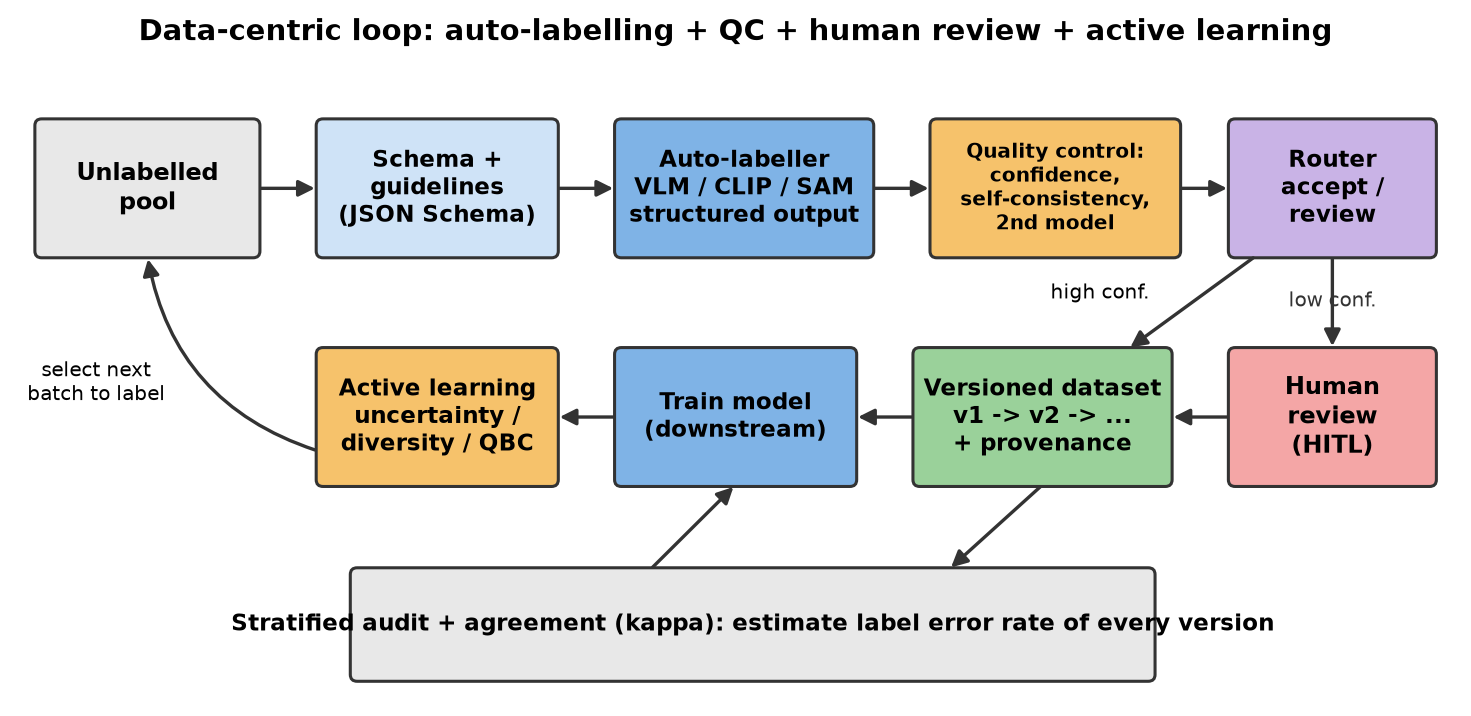

## 1. Data-centric подход и цена ошибок разметки

### 1.1. Model-centric и data-centric

Классическая постановка машинного обучения считает датасет фиксированным, а работу исследователя — поиском лучшей модели, функции потерь и гиперпараметров. Это model-centric подход. Data-centric подход меняет местами переменную и константу: архитектура (часто это готовая foundation-модель с дообучаемой головой) почти фиксирована, а итерации идут над данными — что размечать, как размечать, как найти и исправить ошибки, как покрыть редкие случаи.

Почему это стало центральной темой именно сейчас:

- Сильные предобученные модели (CLIP, DINOv2, SAM, VLM) сделали «модельную» часть дешёвой: линейная голова поверх замороженных признаков часто даёт качество, близкое к полному дообучению. Узким местом становятся метки для конкретной задачи.
- Те же модели сами стали разметчиками. VLM может за доли секунды описать изображение, классифицировать его в заданной таксономии и вернуть JSON. Вопрос сместился с «как разметить» на «как проверить и как поверить».
- Стоимость ошибки в данных обычно выше стоимости ошибки в модели: систематически неверная метка обучает модель неверному правилу, а ошибка в тестовой разметке искажает выбор модели.

### 1.2. Ошибки разметки повсеместны

Даже в эталонных датасетах метки содержат ошибки:

- [Northcutt et al., 2021](https://arxiv.org/abs/2103.14749) нашли в тестовых частях 10 популярных датасетов в среднем не менее 3.3 % ошибок, в валидационной части ImageNet — не менее 6 %. Кандидатов на ошибку находили алгоритмически, а затем проверяли людьми: подтвердилась примерно половина (51 %) кандидатов.
- В [CIFAR-10N](https://arxiv.org/abs/2110.12088) каждое обучающее изображение CIFAR-10 разметили три человека с Amazon Mechanical Turk. Единогласными оказались 60.27 % изображений. Доля ошибок в отдельной разметке («Random 1–3») — около 17–18 %, при голосовании большинством («Aggregate») — 9.03 %, а в «худшей» разметке, где выбирается неверная метка, если она есть хотя бы у одного разметчика, — 40.21 %. Важный вывод работы: реальный человеческий шум зависит от конкретного изображения (instance-dependent), а не только от пары классов.
- Тестовые части CIFAR содержат почти-дубликаты обучающих изображений: 3.3 % для CIFAR-10 и 10 % для CIFAR-100 ([ciFAIR](https://arxiv.org/abs/1902.00423)); после их замены точность популярных моделей падает на 9–14 % относительно исходной.

Последствия ошибок различаются для обучающих и тестовых данных. Ошибки в обучении модель частично «переживает» (особенно случайный шум при большом объёме данных), хотя и теряет качество и калибровку. Ошибки в тесте опаснее: они меняют ранжирование моделей. В той же работе [Northcutt et al.](https://arxiv.org/abs/2103.14749) показано, что модели меньшей ёмкости могут оказаться практичнее больших: на ImageNet с исправленными метками ResNet-18 обходит ResNet-50, если доля исходно ошибочных тестовых примеров вырастет всего на 6 %, а на CIFAR-10 VGG-11 обходит VGG-19 при росте на 5 %. Выбор модели по «грязному» тесту может быть неверным.

### 1.3. Типы шума

Пусть $y^*$ — истинная метка, $\tilde y$ — наблюдаемая. Принято различать:

- равномерный (symmetric) шум: $P(\tilde y = j \mid y^* = i) = \varepsilon / (C-1)$ для всех $j \ne i$;
- класс-зависимый шум: матрица переходов $T_{ij} = P(\tilde y = j \mid y^* = i)$ не зависит от изображения, но разные пары классов путаются с разной частотой (кошка ↔ собака часто, кошка ↔ корабль почти никогда). Именно эту модель использует confident learning ([Northcutt et al.](https://arxiv.org/abs/1911.00068)) — оценивает совместное распределение $P(\tilde y, y^*)$;
- instance-dependent шум: $P(\tilde y \mid y^*, x)$ зависит от самого изображения (размытое, мелкое, нетипичное). Это самый реалистичный и самый трудный случай.

Автоматическая разметка моделью даёт в основном класс- и instance-dependent шум, причём систематический: модель ошибается одинаково на похожих объектах. Поэтому одной из главных идей лекции будет независимость источников проверки.

### 1.4. Пример: цена ошибок

Допустим, нужно разметить 100 000 изображений по 20 классам. Человек тратит 4 секунды на изображение (примерно 110 часов работы). VLM на одной GPU тратит 0.3 секунды (8 часов машинного времени), но ошибается в 8 % случаев. Если направить на проверку человеком 15 % самых неуверенных меток, а прокси уверенности хорошее, то большинство ошибок попадёт именно в эти 15 %. Человек проверяет 15 000 изображений (≈ 17 часов), и в датасете остаётся, скажем, 1–2 % ошибок. Ключевые слова здесь — «если прокси хорошее»: всю вторую половину лекции мы учимся это проверять.

## 2. Конвейер разметки

### 2.1. Этапы

Типичный конвейер (рисунок выше):

1. Определение задачи и схемы: таксономия, правила разметки (guidelines) с примерами и пограничными случаями, формат результата.
2. Пилотная разметка: несколько разметчиков размечают небольшую выборку, измеряется согласие, правила уточняются. Это самый дешёвый способ найти неоднозначности таксономии.
3. Массовая разметка: люди, модели или их комбинация (предразметка моделью + исправление человеком).
4. Контроль качества: прокси уверенности, вторая модель, выборочная проверка, согласие.
5. Маршрутизация: часть меток принимается, часть уходит на проверку.
6. Версионирование: результат фиксируется как версия датасета с журналом происхождения меток.
7. Обучение и анализ ошибок модели, active learning выбирает, что размечать дальше. Цикл повторяется.

### 2.2. Форматы

- COCO JSON — один файл с массивами `images`, `annotations` и `categories`; рамки задаются как `[x, y, width, height]` в пикселях, маски — полигонами или RLE.
- YOLO — один текстовый файл на изображение, строка `class x_center y_center width height` с координатами, нормированными на размер изображения.
- Pascal VOC — XML на изображение, рамки `xmin, ymin, xmax, ymax`.
- Для классификации и подписей удобен JSONL: одна строка — одна аннотация с идентификатором объекта, меткой и метаданными. Его легко дописывать, сравнивать и хранить в git или DVC.

Ошибки конвертации форматов (перепутанные центр/угол, нормировка, индексация классов с 0 или с 1) — частая причина «необъяснимо плохого» обучения. Минимальная защита — визуализировать несколько случайных аннотаций после каждой конвертации.

### 2.3. Инструменты

Для ручной разметки в CV чаще всего используют открытые [CVAT](https://github.com/cvat-ai/cvat) и [Label Studio](https://labelstud.io/). Оба поддерживают предразметку моделью (pre-annotation): модель предлагает рамки или метки, человек их принимает или исправляет. Важно, что предразметка не нейтральна по отношению к человеку — об этом в разделе 12.

### 2.4. Источники автоматических меток

- Модели-учителя закрытого набора классов: обученный детектор или классификатор размечает новые данные (pseudo-labelling, self-training).
- Zero-shot модели: CLIP (лекция 5) классифицирует по текстовым описаниям классов; open-vocabulary детекторы и SAM (лекция 3) дают рамки и маски.
- VLM (лекция 6): по инструкции возвращают метку, описание, атрибуты, рамки — в структурированном виде.
- Слабая разметка (weak supervision): программные эвристики («labelling functions»), каждая из которых шумная, объединяются генеративной моделью их точностей и корреляций. Система [Snorkel](https://arxiv.org/abs/1711.10160) в пользовательском исследовании позволила экспертам строить модели в 2.8 раза быстрее и в среднем на 45.5 % качественнее, чем при ручной разметке за то же время.

Пример масштабной автоматической разметки — data engine [Segment Anything](https://arxiv.org/abs/2304.02643). Он прошёл три стадии:

1. assisted-manual: разметчики исправляли маски, предложенные моделью; модель переобучалась 6 раз, а время на маску снизилось с 34 до 14 секунд; собрано 4.3 млн масок на 120 тыс. изображений;
2. semi-automatic: модель размечала уверенные объекты сама, люди добавляли пропущенные — ещё 5.9 млн масок на 180 тыс. изображений, всего 10.2 млн;
3. fully automatic: итоговый SA-1B — 1.1 млрд масок, 99.1 % из которых сгенерированы полностью автоматически.

Это и есть цикл «модель размечает → человек исправляет → модель переобучается» в промышленном масштабе.

Для текстовых задач большие языковые модели уже сравнимы с краудсорсингом. [Wang et al., 2021](https://arxiv.org/abs/2108.13487) оценили, что разметка GPT-3 обходится на 50–96 % дешевле человеческой при сопоставимом качестве downstream-модели. [Gilardi et al., 2023](https://arxiv.org/abs/2303.15056) показали, что ChatGPT точнее краудворкеров в четырёх задачах из пяти при стоимости менее 0.003 доллара за аннотацию — примерно в 20 раз дешевле MTurk. Для изображений ситуация аналогична с VLM, но с поправкой: VLM хуже справляются с мелкими объектами, подсчётом и пространственными отношениями (лекция 6), поэтому контроль качества для них ещё важнее.

## 3. Схема разметки и JSON Schema

### 3.1. Таксономия

Схема начинается с таксономии — списка классов и правил, по которым объект относят к классу. Хорошая таксономия:

- взаимоисключающая (если задача — один класс на объект) или явно многометочная;
- полная: содержит класс `other` / `unknown` для объектов вне списка. Без него разметчик (человек или модель) вынужден выбрать ближайший класс, и ошибки «вне таксономии» становятся неотличимы от обычных;
- операционализированная: для каждого класса есть определение, положительные и отрицательные примеры и правило для пограничных случаев (является ли пикап «automobile» или «truck»? В [описании CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) это решено явно: «automobile» — седаны, внедорожники и подобные машины, «truck» — только большие грузовики, а пикапов нет ни в одном из классов);
- стабильная: изменение таксономии делает старые метки несопоставимыми с новыми, поэтому у схемы есть версия.

Отдельные флаги «не уверен» и «изображение плохого качества» полезнее, чем кажется: они дают разметчику легальный способ сообщить о проблеме вместо того, чтобы выбирать случайный класс.

### 3.2. JSON Schema

[JSON Schema](https://json-schema.org/understanding-json-schema/reference/object) — стандартный язык описания структуры JSON-документов. Основные ключевые слова для разметки:

| Ключевое слово | Смысл | Пример использования |
|---|---|---|
| `type` | тип значения | `"object"`, `"string"`, `"number"`, `"boolean"`, `"array"` |
| `properties` | схемы полей объекта | `{"class_name": {...}, "caption": {...}}` |
| `required` | обязательные поля | `["class_name", "caption"]` |
| `additionalProperties: false` | запрет лишних полей | модель не добавит `"breed"` |
| `enum` | закрытый список значений | классы таксономии |
| `minLength`, `maxLength`, `pattern` | ограничения строки | подпись 3–120 символов |
| `minimum`, `maximum` | ограничения числа | уверенность в [0, 1] |
| `items`, `minItems`, `maxItems` | ограничения массива | список рамок |
| `$defs`, `$ref` | переиспользуемые фрагменты | описание рамки |

Пример схемы для детекции:

```json
{
  "type": "object",
  "properties": {
    "objects": {
      "type": "array", "maxItems": 50,
      "items": {
        "type": "object",
        "properties": {
          "label": {"enum": ["person", "car", "bicycle", "other"]},
          "bbox_xyxy": {"type": "array", "items": {"type": "integer", "minimum": 0}, "minItems": 4, "maxItems": 4}
        },
        "required": ["label", "bbox_xyxy"], "additionalProperties": false
      }
    }
  },
  "required": ["objects"], "additionalProperties": false
}
```

Заметьте, чего JSON Schema не проверяет: что $x_{\min} < x_{\max}$, что рамка лежит внутри изображения, что подпись соответствует классу. Это семантические проверки, их пишут кодом после структурной валидации. В Python схему удобно описывать классом [Pydantic](https://docs.pydantic.dev/latest/): из класса генерируется JSON Schema, а методы-валидаторы реализуют семантические правила.

### 3.3. Порядок полей и «рассуждение»

Для генеративной модели порядок полей в JSON — это порядок генерации. Если первым идёт `class_name`, решение принимается сразу, без «размышления». Если первым идёт `caption` или поле `reasoning`, модель сначала описывает изображение, а затем выбирает класс с учётом своего описания. Это может как повысить точность (аналог chain-of-thought), так и снизить её (модель «уговаривает» себя). Порядок полей — гиперпараметр, который стоит проверять на пилотной выборке. В практике мы ставим класс первым, чтобы получить вероятность класса за один проход модели.

## 4. Structured generation: от промпта к constrained decoding

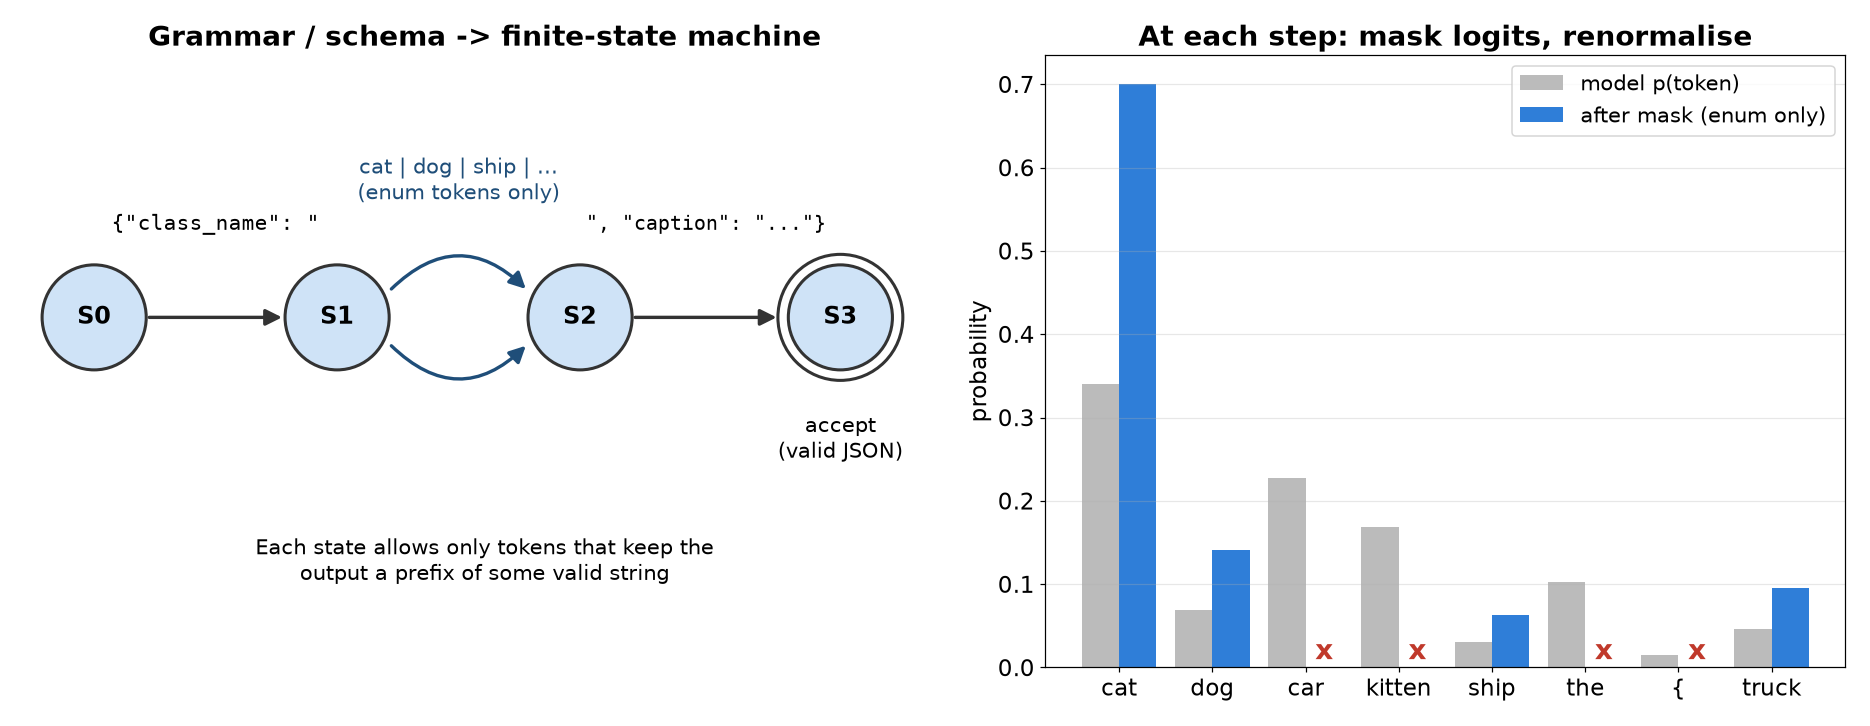

### 4.1. Четыре уровня гарантий

1. Инструкция в промпте («ответь в JSON»). Никаких гарантий: модель может добавить пояснение, обернуть ответ в блок кода, выбрать свои имена полей.
2. Схема в промпте. Модель видит точные имена полей и допустимые значения. Качество заметно растёт, но гарантий по-прежнему нет.
3. JSON mode / structured outputs API. Многие серверы инференса принимают схему и сами обеспечивают валидность — внутри это обычно constrained decoding.
4. Constrained (grammar-constrained) decoding. На каждом шаге генерации логиты токенов, нарушающих грамматику, обнуляются (устанавливаются в $-\infty$), и распределение перенормируется. Результат валиден по построению.

### 4.2. Как работает маскирование

Пусть $\mathcal V$ — словарь, $s$ — текущее состояние автомата, распознающего допустимые строки, $A(s) \subseteq \mathcal V$ — токены, после которых строка остаётся префиксом какой-то допустимой строки. Тогда

$$ \tilde p(v \mid x, y_{<t}) = \frac{p(v \mid x, y_{<t})\, \mathbb 1[v \in A(s_t)]}{\sum_{u \in A(s_t)} p(u \mid x, y_{<t})}. $$

Для регулярных выражений и JSON Schema без рекурсии автомат конечный. [Outlines](https://arxiv.org/abs/2307.09702) строит конечный автомат по регулярному выражению и заранее индексирует для каждого состояния, какие токены словаря допустимы, — тогда маска на шаге генерации получается поиском в индексе, а не перебором словаря. Для контекстно-свободных грамматик (вложенный JSON, рекурсивные структуры) нужен автомат с магазинной памятью. [XGrammar](https://arxiv.org/abs/2411.15100) делит токены на контекстно-независимые (допустимость которых определяется только позицией в грамматике и может быть вычислена заранее) и контекстно-зависимые (проверяются во время генерации), что делает маскирование для CFG почти бесплатным. В [llama.cpp](https://github.com/ggml-org/llama.cpp/blob/master/grammars/README.md) грамматики задаются в формате GBNF, и есть конвертер JSON Schema → GBNF. В `transformers` простейший механизм — аргумент `prefix_allowed_tokens_fn` метода `generate` ([документация](https://huggingface.co/docs/transformers/main_classes/text_generation)): функция получает уже сгенерированные токены и возвращает список разрешённых; мы используем его в практике.

### 4.3. Тонкости

- Границы токенов. Токенизатор режет строки не по символам грамматики: токен ` "cat` может содержать и кавычку, и начало значения. Автомат должен работать на уровне символов внутри токена. Отсюда же эффект «сдвига»: если грамматика навязывает токенизацию, которую модель редко видела при обучении (например, слово по буквам), вероятности становятся неестественными и качество падает.
- Маска не делает ответ верным. Constrained decoding гарантирует синтаксис и закрытый список значений, но не правильность класса. Если модель «хотела» ответить `kitten`, а разрешено только `cat`/`dog`/…, то маска перенормирует распределение среди разрешённых токенов; это обычно разумно, но доля вероятности, ушедшая на запрещённые токены, — полезный сигнал: чем она больше, тем менее схема соответствует тому, что «видит» модель.
- Влияние на рассуждение. [Tam et al., 2024 («Let Me Speak Freely?»)](https://arxiv.org/abs/2408.02442) показали, что строгие ограничения формата ухудшают способности модели к рассуждению, и чем жёстче ограничения, тем сильнее деградация. Практический компромисс — давать модели свободное поле для описания или рассуждения перед полем с решением, либо делать два шага: свободный ответ, затем извлечение в схему.
- Префикс (prefill). Самый простой «constrained decoding» — начать ответ ассистента за модель: если ответ уже начинается с `{"class_name": "`, следующей будет метка. Это работает в любой локальной модели и в API, которые разрешают prefill.

### 4.4. Пример: вероятность класса за один проход

Если первые токены всех меток различны (в Qwen3-VL: `air`, `autom`, `bird`, `cat`, ...), то после префикса `{"class_name": "` вероятность метки равна вероятности её первого токена, и всё распределение по классам получается из одного прямого прохода модели:

$$ p(c \mid x) = \frac{p(\mathrm{tok}_1(c) \mid x, \text{prefix})}{\sum_{c'} p(\mathrm{tok}_1(c') \mid x, \text{prefix})}. $$

Это дешевле генерации и сразу даёт white-box прокси уверенности. Если первые токены совпадают (например, `truck` и `trailer` начинаются с `tr`), вероятность метки — произведение вероятностей всех её токенов, и её считают по префиксному дереву.

## 5. Повтор при невалидном ответе

### 5.1. Схема повтора

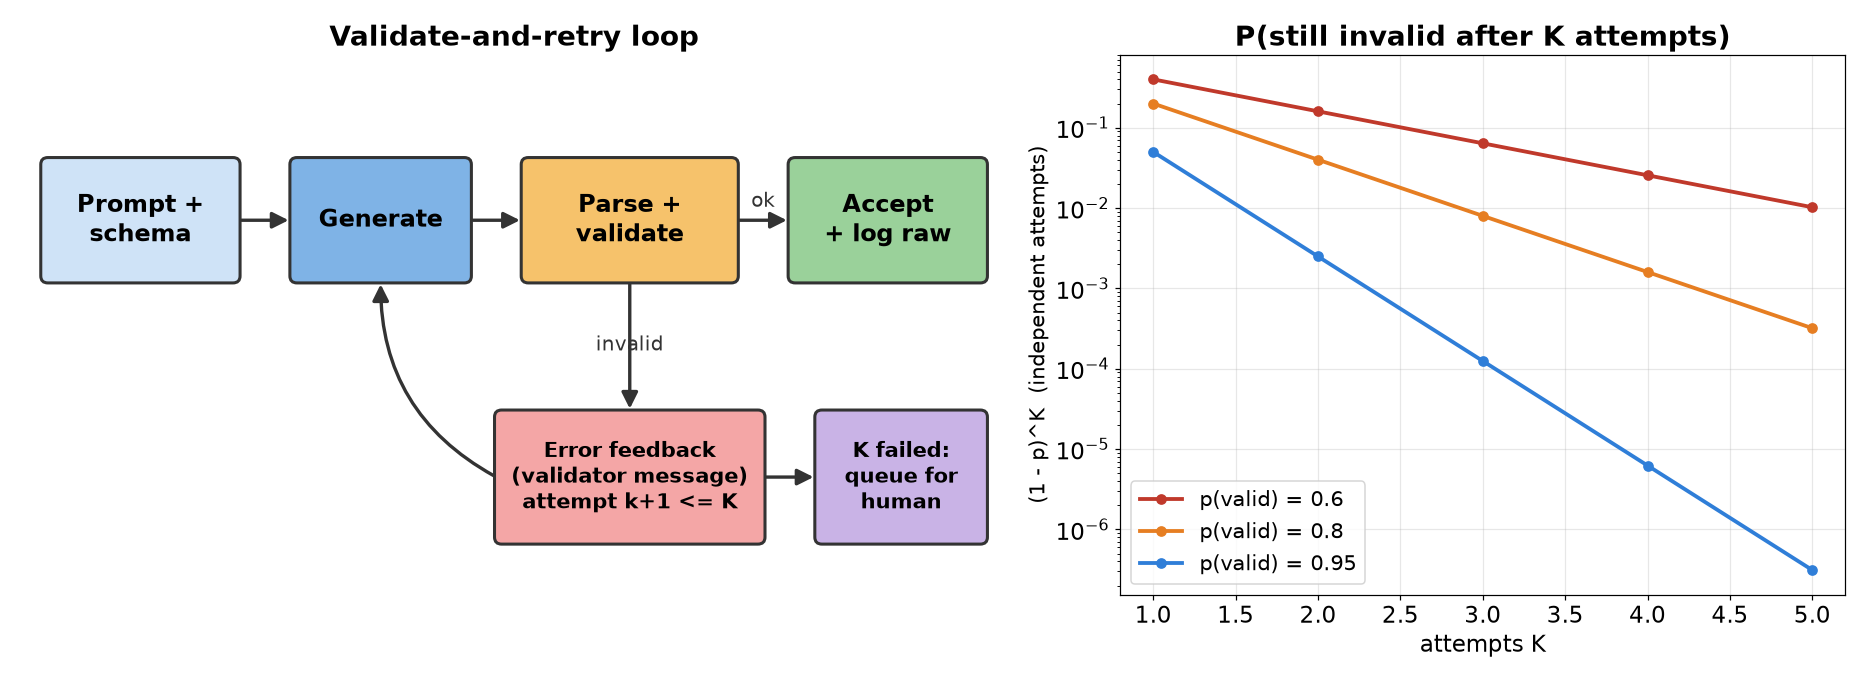

Если гарантии валидности нет (API без structured outputs, сложная семантическая проверка), используется цикл: сгенерировать → извлечь JSON → проверить схему → проверить семантику → при ошибке повторить. Варианты повтора:

- слепой повтор с сэмплированием (другая случайная траектория);
- повтор с обратной связью: в промпт добавляются предыдущий ответ и текст ошибки валидатора («`confidence`: Input should be less than or equal to 1»). Модель исправляет конкретное поле, и вероятность успеха растёт;
- ремонт (repair): исправление кодом типичных ошибок (лишняя запятая, блок Markdown вокруг JSON, одинарные кавычки) до повторного вызова модели. Ремонт должен быть консервативным: нельзя «чинить» значения (обрезать неизвестный класс до ближайшего), иначе ошибка модели превратится в тихую ошибку данных.

### 5.2. Сколько попыток нужно

Если попытки независимы и каждая успешна с вероятностью $p$, то вероятность неудачи после $K$ попыток и ожидаемое число попыток до первого успеха равны

$$ P_{\text{fail}}(K) = (1 - p)^K, \qquad \mathbb E[\text{attempts}] = \frac{1}{p}. $$

При $p = 0.8$ три попытки дают $1 - 0.2^3 = 99.2\,\%$ валидных ответов при средней цене 1.25 вызова. Но независимость — оптимистичное допущение. При жадном декодировании одинаковый вход даёт одинаковый ответ, поэтому слепой повтор бесполезен; при сэмплировании ошибки коррелированы — если модель не понимает изображение, она ошибается на нём снова и снова. На практике вероятность успеха $k$-й попытки снижается с $k$, и объекты, не прошедшие валидацию за $K$ попыток, — кандидаты на ручную проверку, а не на четвёртую попытку.

Пример расчёта бюджета: 10 000 изображений, $p = 0.9$, $K = 3$. Ожидаемое число вызовов ≈ $10\,000 \cdot (1 + 0.1 + 0.01) = 11\,100$, невалидных после трёх попыток ≈ $10\,000 \cdot 0.001 = 10$ — эти 10 изображений отправляются человеку.

### 5.3. Что записывать

Каждая попытка сохраняется с текстом ответа, ошибкой валидатора, параметрами генерации и временем. Журнал попыток показывает систематические проблемы: если 80 % ошибок — неизвестный класс `kitten`, проблема не в формате, а в таксономии или промпте.

## 6. Прокси уверенности, self-consistency и калибровка

### 6.1. Что такое прокси уверенности

Для каждой автоматической метки $\hat y_i$ хотим число $s_i$, которое предсказывает, верна ли она. Прокси оценивают по двум свойствам:

- ранжирование: ошибочные метки должны иметь меньшее $s$. Мера — AUROC задачи «верна ли метка» (вероятность того, что случайная верная метка получит большее $s$, чем случайная ошибочная) или AUPRC для поиска ошибок;
- калибровка: среди меток с $s \approx 0.9$ должно быть около 90 % верных. Мера — ECE (раздел 6.4).

Хорошее ранжирование нужно, чтобы выбирать, что проверять; хорошая калибровка — чтобы выбрать порог и оценить долю ошибок без полной проверки.

### 6.2. Виды прокси

White-box (нужен доступ к вероятностям токенов):

- вероятность класса $p_{\max} = \max_c p(c \mid x)$ (для генеративной модели — вероятность токенов метки, раздел 4.4);
- margin $p_{(1)} - p_{(2)}$ — разность двух старших вероятностей; лучше $p_{\max}$ отражает «колебание» между двумя классами;
- энтропия $H = -\sum_c p_c \log p_c$ — учитывает весь хвост распределения;
- для свободного текста — средняя или минимальная логарифмическая вероятность токенов ответа. Она смешивает уверенность в содержании и в формулировке, поэтому для разметки предпочтительнее закрытый список меток.

Black-box (доступен только текст ответа):

- словесная (verbalized) уверенность: модель сама пишет «confidence: 0.9». [Xiong et al., 2023](https://arxiv.org/abs/2306.13063) систематически показали, что языковые модели в этом режиме переуверены, возможно подражая тому, как уверенность выражают люди, и что согласованность нескольких ответов помогает уменьшить переуверенность. White-box методы в их сравнении работали лучше black-box, но разрыв невелик (AUROC 0.605 против 0.522), и ни один метод не был стабильно лучшим;
- самооценка P(True): модели показывают её же ответ и спрашивают «верен ли ответ?», уверенностью считают вероятность токена «True» ([Kadavath et al., 2022](https://arxiv.org/abs/2207.05221));
- self-consistency (раздел 6.3).

### 6.3. Self-consistency

Идея [self-consistency](https://arxiv.org/abs/2203.11171): если сгенерировать несколько ответов (с сэмплированием, разными рассуждениями) и выбрать самый частый, точность растёт — в исходной работе на задачах арифметики GSM8K прирост составил +17.9 %. Для разметки важнее второе применение: доля голосов за итоговый ответ — прокси уверенности.

Источники разнообразия для изображений:

- сэмплирование при температуре $T > 0$;
- test-time augmentation: отражение, небольшой сдвиг или масштаб, изменение яркости — преобразования, которые не меняют истинную метку;
- перефразирование промпта и перестановка списка классов (модели чувствительны к порядку вариантов);
- разные модели (это уже раздел 7).

Если ответ — одна метка из $C$, то $K$ сэмплов дают оценку моды и доли голосов $v = \max_c n_c / K$. При $K = 5$ прокси принимает всего несколько значений (0.4, 0.6, 0.8, 1.0), поэтому для ранжирования оно грубее, чем $p_{\max}$. Зато доступно для закрытых API.

Пример. Для изображения кошки модель трижды из пяти ответила `cat`, дважды `dog`: $v = 0.6$. Для другого изображения — пять раз `ship`: $v = 1.0$. Первое — кандидат на проверку, второе принимаем, если высокая согласованность действительно соответствует высокой точности на калибровочной выборке. Важно: согласованность измеряет устойчивость модели, а не правильность. Модель может стабильно ошибаться (например, всегда называть маленький грузовик `automobile`), и self-consistency этого не заметит. От систематических ошибок защищает только независимый источник — вторая модель или человек.

### 6.4. Калибровка

Разобьём $[0,1]$ на $M$ интервалов $B_m$ по уверенности. Тогда

$$ \mathrm{ECE} = \sum_{m=1}^{M} \frac{|B_m|}{n} \left| \mathrm{acc}(B_m) - \mathrm{conf}(B_m) \right|. $$

Диаграмма надёжности (reliability diagram) — график $\mathrm{acc}(B_m)$ против $\mathrm{conf}(B_m)$; у идеально калиброванной модели точки лежат на диагонали. [Guo et al., 2017](https://arxiv.org/abs/1706.04599) показали, что современные глубокие сети систематически переуверены, и что простейший способ исправить это — temperature scaling: логиты делятся на одно число $T$, подобранное по NLL на отложенной выборке:

$$ \hat p_i = \mathrm{softmax}(z_i / T), \qquad T^* = \arg\min_T \; -\sum_{i \in \mathcal D_{\text{cal}}} \log \hat p_{i, y_i}. $$

$T > 1$ «смягчает» распределение (лечит переуверенность), $T < 1$ заостряет. Argmax не меняется, поэтому точность не меняется. Для калибровки нужна размеченная выборка — но её всё равно приходится делать для аудита (раздел 8), и одна и та же выборка из нескольких сотен объектов служит обеим целям. Следует помнить, что калибровка зависит от распределения данных: при сдвиге домена её нужно проверять заново.

### 6.5. Selective prediction и кривая risk–coverage

Если отсортировать метки по уверенности и принимать только верхнюю долю $c$ (coverage), то доля ошибок среди принятых (risk) обычно падает с уменьшением $c$. Кривая risk–coverage показывает компромисс, а задача выбора порога формулируется как «максимальное покрытие при риске не выше $r^*$». [Geifman & El-Yaniv, 2017](https://arxiv.org/abs/1705.08500) предложили способ выбрать порог с гарантией: например, на ImageNet достигается ошибка top-5 2 % с вероятностью 99.9 % при покрытии около 60 %. Для разметки это прямо переводится в правило: «принимать автоматически, если уверенность выше $\tau$; иначе — человеку».

## 7. Проверка второй моделью и confident learning

### 7.1. Вторая модель

Согласие двух моделей повышает доверие к метке только в той мере, в какой их ошибки независимы. Пусть модели ошибаются с вероятностями $e_1, e_2$. Если ошибки независимы и при ошибке модели выбирают разные неверные классы, то доля ошибок среди меток, где модели согласны, приблизительно равна

$$ P(\text{both wrong, same class} \mid \text{agree}) \approx \frac{e_1 e_2 / (C - 1)}{(1 - e_1)(1 - e_2) + e_1 e_2 / (C-1)}, $$

то есть очень мала. Но реальные ошибки коррелированы: модели, обученные на похожих веб-данных, путают одни и те же пары классов. Поэтому вторую модель выбирают максимально «непохожей»: другой принцип обучения (контрастивный CLIP против генеративной VLM), другая архитектура, другие данные. Согласие используют как фильтр для автоматического принятия, а расхождение — как сигнал для проверки. Вторая модель может быть и более слабой, но специализированной: например, детектор, обученный на тысяче ручных меток, проверяет рамки VLM.

Вариант «модель-судья» (LLM-as-a-judge): вторая модель получает изображение и предложенную метку и отвечает, верна ли она. Это дешевле полной повторной разметки, но судья подвержен эффекту якоря — он склонен соглашаться с предложенной меткой.

### 7.2. Confident learning

[Confident learning](https://arxiv.org/abs/1911.00068) ищет ошибки разметки в имеющемся датасете без эталона, предполагая класс-зависимый шум. Алгоритм:

1. Обучить классификатор на шумных метках и получить вероятности $\hat p_{ik}$ для каждого объекта out-of-fold (кросс-валидацией), чтобы модель не запомнила метку объекта.
2. Для каждого класса порог $t_k = \frac{1}{|\{i: \tilde y_i = k\}|}\sum_{i: \tilde y_i = k} \hat p_{ik}$ — средняя уверенность модели в классе $k$ на объектах с этой меткой.
3. Объект $i$ с меткой $\tilde y_i = j$ попадает в ячейку $C_{j,k}$ «уверенной совместной матрицы», если $\hat p_{ik} \ge t_k$ (при нескольких таких $k$ — с наибольшей вероятностью).
4. Внедиагональные ячейки $C_{j,k}, j \ne k$ — кандидаты на ошибки; из них оценивается совместное распределение $P(\tilde y, y^*)$ и количество ошибок, а кандидаты ранжируются, например, по $\hat p_{i,\tilde y_i}$ (self-confidence).

Пороги $t_k$ по классам — главное отличие от наивного «выбросить объекты с низкой вероятностью»: они учитывают, что для трудных классов модель в среднем менее уверена. Реализация — библиотека [cleanlab](https://github.com/cleanlab/cleanlab). Найденные кандидаты не исправляют автоматически, а отправляют человеку: в работе о тестовых наборах подтвердилась примерно половина из них ([Northcutt et al., 2021](https://arxiv.org/abs/2103.14749)).

## 8. Стратифицированная ручная проверка

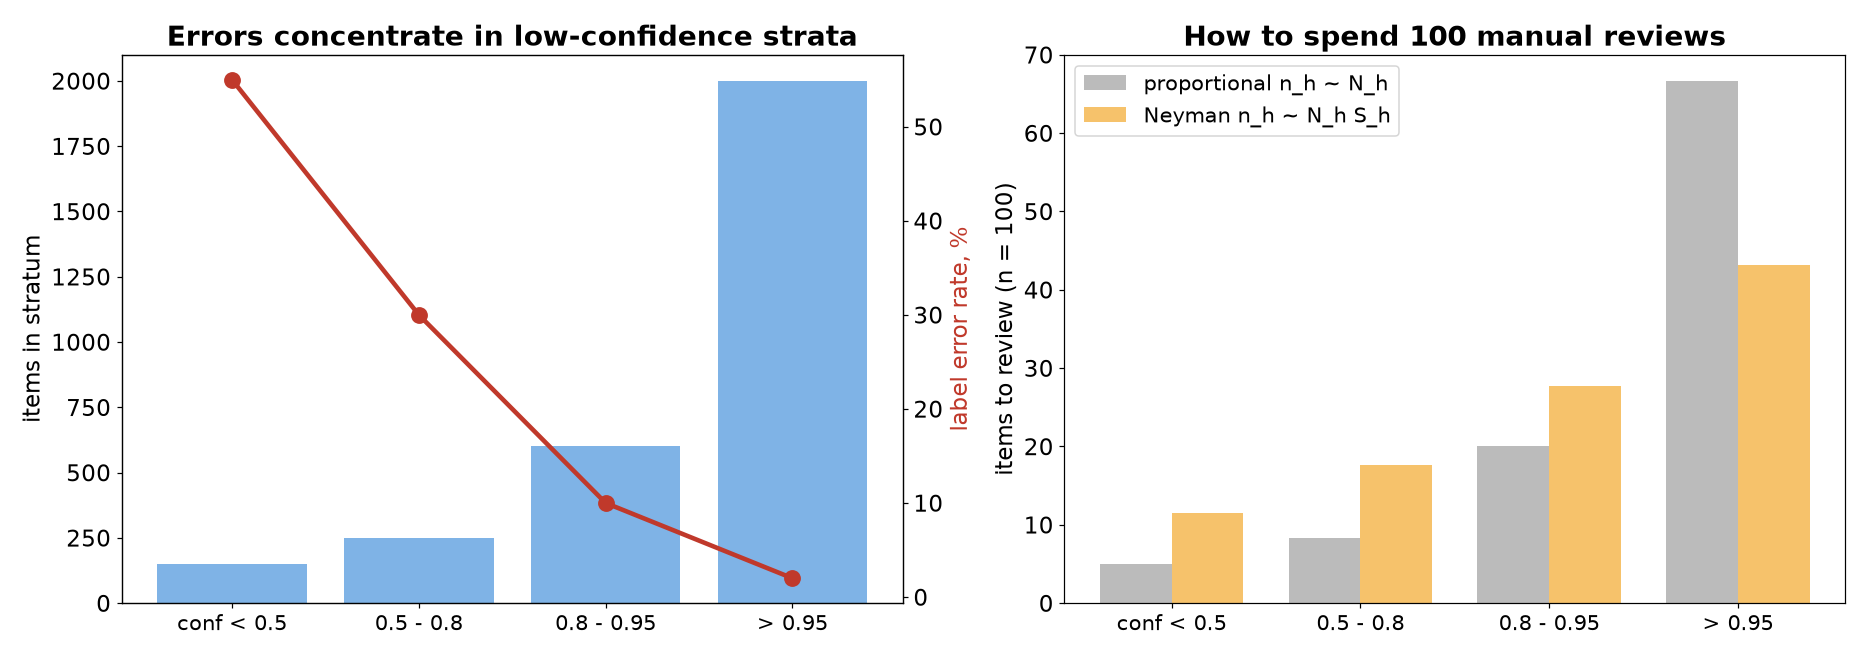

### 8.1. Зачем выборочная проверка

Прокси показывают, где ошибки вероятнее, но не говорят, сколько их на самом деле. Долю ошибок $e$ в автоматической разметке $N$ объектов оценивают по выборке, которую проверяет человек. Это задача выборочного обследования, и для неё есть классическая теория.

### 8.2. Простая случайная выборка

При выборке без возвращения $n$ из $N$ объектов с $k$ найденными ошибками:

$$ \hat e = \frac{k}{n}, \qquad \widehat{\mathrm{Var}}(\hat e) = \frac{\hat e (1 - \hat e)}{n - 1}\left(1 - \frac{n}{N}\right). $$

При малых $e$ нормальный интервал $\hat e \pm 1.96 \sqrt{\widehat{\mathrm{Var}}}$ неточен (может уходить ниже нуля, а при $k = 0$ имеет нулевую ширину). Лучше использовать интервал Уилсона или точный интервал Клоппера — Пирсона. Полезное «правило трёх»: если в $n$ проверенных объектах не найдено ни одной ошибки, 95 % верхняя граница доли ошибок примерно $3/n$. Чтобы утверждать «ошибок меньше 1 %», нужно без единой ошибки проверить около 300 объектов.

### 8.3. Стратификация

Разобьём объекты на страты $h = 1..H$ (по уверенности, по классу, по источнику метки), $N_h$ — размеры, $W_h = N_h / N$. Из каждой страты берём случайную выборку $n_h$. Несмещённая оценка и её дисперсия:

$$ \hat e_{\text{st}} = \sum_h W_h \hat e_h, \qquad \widehat{\mathrm{Var}}(\hat e_{\text{st}}) = \sum_h W_h^2 \left(1 - \frac{n_h}{N_h}\right) \frac{\hat e_h (1 - \hat e_h)}{n_h - 1}. $$

Размещение выборки по стратам:

- пропорциональное: $n_h \propto N_h$ — никогда не хуже простой случайной выборки;
- оптимальное по Нейману: $n_h \propto N_h \sigma_h$, где $\sigma_h = \sqrt{e_h (1 - e_h)}$ — стандартное отклонение индикатора ошибки в страте. Больше проверок там, где ошибки вероятны и разброс велик.

Для разметки естественная стратификация — по уверенности модели: в страте высокой уверенности ошибок мало, в страте низкой — много. Значения $e_h$ для Неймана неизвестны заранее, но их можно взять из калиброванной уверенности ($e_h \approx 1 - \bar p_h$) или из пилотной проверки. Даже грубое приближение обычно даёт выигрыш.

Пример. 10 000 меток: 8 000 с уверенностью ≥ 0.95 (ожидаемая доля ошибок 1 %), 1 500 в диапазоне 0.8–0.95 (8 %), 500 ниже 0.8 (35 %). Бюджет — 200 проверок. $N_h \sigma_h$: $8000 \cdot 0.099 = 796$, $1500 \cdot 0.271 = 407$, $500 \cdot 0.477 = 238$. Размещение по Нейману — примерно 110, 57 и 33 проверки, а пропорциональное — 160, 30 и 10. Ожидаемая доля ошибок $e = 0.8 \cdot 0.01 + 0.15 \cdot 0.08 + 0.05 \cdot 0.35 = 3.75\,\%$. Стандартная ошибка оценки: простая случайная выборка — $\sqrt{0.0375 \cdot 0.9625 / 200} \approx 1.34$ п. п., пропорциональное размещение — $\sqrt{\sum_h W_h \sigma_h^2 / n} \approx 1.23$ п. п., размещение Неймана — $\sum_h W_h \sigma_h / \sqrt n \approx 1.02$ п. п. (поправкой на конечность совокупности пренебрегаем). Дисперсия у Неймана в 1.7 раза меньше, то есть ту же точность, что у простой случайной выборки, Нейман даёт примерно на 40 % меньшим бюджетом.

Ещё одно правило: выборка для аудита должна быть случайной внутри страт. Проверка «самых подозрительных» объектов полезна для исправления ошибок, но не даёт несмещённой оценки их доли — это две разные задачи, и бюджет обычно делят между ними.

## 9. Согласие разметчиков: κ и α

### 9.1. Cohen κ

Два разметчика (люди, модели, человек и модель) разметили одни и те же $n$ объектов. $p_o$ — доля совпадений, $p_e = \sum_c p_c^{(1)} p_c^{(2)}$ — ожидаемая доля случайных совпадений при независимой разметке с теми же частотами классов:

$$ \kappa = \frac{p_o - p_e}{1 - p_e}. $$

Пример. Бинарная задача «есть ли дефект», 100 изображений. Оба разметчика сказали «дефекта нет» на 85, «есть» на 5, расходятся на 10 (по 5 в каждую сторону). $p_o = 0.90$. Частоты «есть»: у каждого 10 %. $p_e = 0.9 \cdot 0.9 + 0.1 \cdot 0.1 = 0.82$. $\kappa = (0.90 - 0.82) / 0.18 = 0.44$ — «умеренное» согласие при 90 % совпадений. Это и есть причина использовать κ: при несбалансированных классах сырой процент совпадений вводит в заблуждение.

Шкала [Landis & Koch (1977)](https://doi.org/10.2307/2529310) — 0.21–0.40 «fair», 0.41–0.60 «moderate», 0.61–0.80 «substantial», 0.81–1.00 «almost perfect» — условна, но широко используется. Ограничения κ: зависит от распространённости классов (тот же уровень реальной согласованности даёт меньший κ при более редком положительном классе) и не учитывает «близость» классов (ошибка кошка↔собака равна ошибке кошка↔корабль; для порядковых шкал используют взвешенный κ).

### 9.2. Fleiss κ и Krippendorff α

Fleiss κ обобщает идею на $r$ разметчиков, каждый из которых размечает каждый объект. Для объекта $i$ с $n_{ij}$ голосами за класс $j$:

$$ P_i = \frac{1}{r(r-1)} \sum_j n_{ij}(n_{ij} - 1), \quad \bar P = \frac{1}{n}\sum_i P_i, \quad P_e = \sum_j p_j^2, \quad \kappa_F = \frac{\bar P - P_e}{1 - P_e}. $$

Krippendorff α записывается как $\alpha = 1 - D_o / D_e$ (наблюдаемое и ожидаемое рассогласование) и удобен на практике: допускает пропуски (не каждый разметчик размечал каждый объект), любое число разметчиков и разные шкалы (номинальную, порядковую, интервальную) через функцию расстояния между метками. Для данных краудсорсинга с неполным перекрытием это обычно лучший выбор.

### 9.3. Что делать с согласием

- Низкое согласие людей между собой — сигнал проблемы в таксономии или инструкции, а не в разметчиках. Сначала уточняют правила.
- Согласие модели с людьми полезно сравнивать с согласием людей между собой: если κ(модель, человек) близко к κ(человек, человек), модель размечает «на уровне человека» для этой задачи.
- Согласие — не точность: два разметчика могут согласованно ошибаться. Поэтому кроме κ нужен аудит по эталону (раздел 8).
- Для детекции и сегментации согласие считают через сопоставление объектов по IoU и затем согласие меток сопоставленных пар; отдельно — долю объектов, найденных только одним разметчиком.

## 10. Active learning

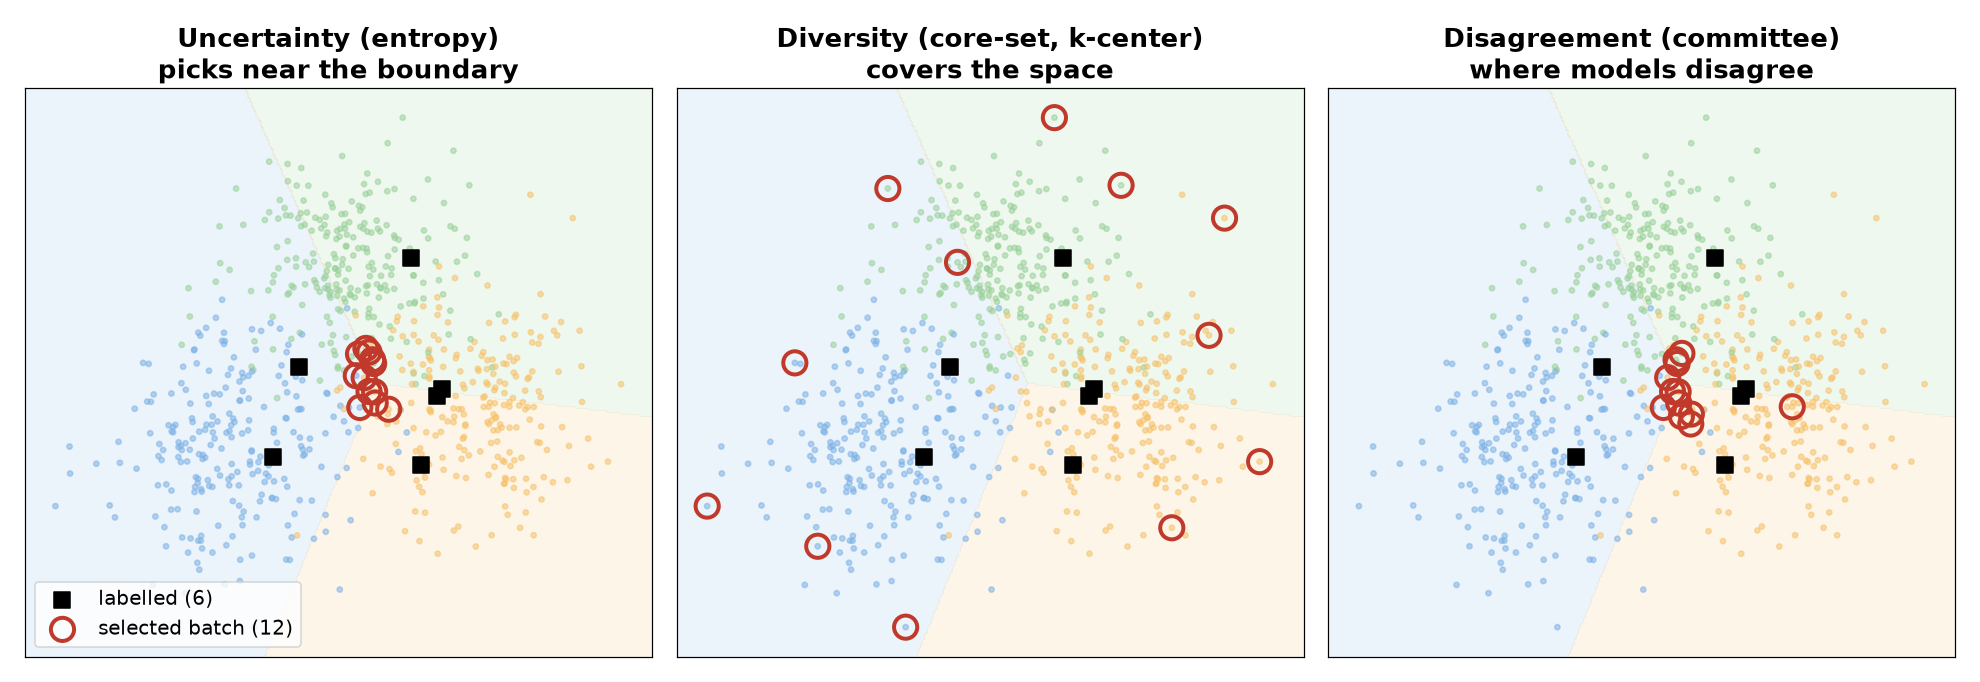

### 10.1. Постановка

Pool-based active learning: есть размеченное множество $\mathcal L$, неразмеченный пул $\mathcal U$, модель $f_\theta$ и oracle (человек), который по запросу возвращает метку. На каждом раунде:

1. обучить $f_\theta$ на $\mathcal L$;
2. функцией полезности (acquisition function) $a(x)$ выбрать батч $\mathcal B \subset \mathcal U$, $|\mathcal B| = b$;
3. получить метки $\mathcal B$, перенести в $\mathcal L$.

Цель — максимальное качество при заданном бюджете меток или минимальный бюджет для заданного качества. Обзоры: классический [Settles](https://minds.wisconsin.edu/handle/1793/60660), для глубокого обучения — [Ren et al.](https://arxiv.org/abs/2009.00236).

### 10.2. Uncertainty sampling

Выбираем объекты, в которых модель меньше всего уверена:

$$ a_{\text{LC}}(x) = 1 - \max_c p(c \mid x), \qquad a_{\text{margin}}(x) = -\left(p_{(1)}(x) - p_{(2)}(x)\right), \qquad a_{\text{H}}(x) = -\sum_c p(c \mid x) \log p(c \mid x). $$

Least confidence, margin и энтропия совпадают для двух классов и различаются для многих: энтропия выбирает объекты, где модель «размазана» по многим классам, margin — где она колеблется между двумя. Margin часто оказывается сильной базой.

Проблемы uncertainty sampling:

- батч из $b$ самых неуверенных объектов часто избыточен: это почти одинаковые объекты у одной границы;
- выборка смещена: модель видит в основном трудные объекты у границ, и распределение классов в $\mathcal L$ искажается;
- выбросы и шумные объекты имеют высокую неопределённость, но малую полезность;
- при очень малом $\mathcal L$ уверенность модели ещё бессмысленна (cold start).

### 10.3. Байесовский взгляд: BALD

Неопределённость бывает двух видов: алеаторная (в самих данных — изображение действительно неоднозначно) и эпистемическая (модели не хватает знаний — исправляется данными). Размечать полезно второе. BALD ([Houlsby et al.](https://arxiv.org/abs/1112.5745)) выбирает объекты с максимальной взаимной информацией между предсказанием и параметрами модели:

$$ a_{\text{BALD}}(x) = \mathbb H\big[\mathbb E_{\theta}\, p(y \mid x, \theta)\big] - \mathbb E_{\theta}\, \mathbb H\big[p(y \mid x, \theta)\big]. $$

Первое слагаемое — полная неопределённость, второе — средняя неопределённость отдельных моделей (алеаторная часть). Разность велика, когда отдельные модели уверены, но не согласны друг с другом. [Gal et al.](https://arxiv.org/abs/1703.02910) реализовали это для глубоких сетей через MC dropout: $\theta$ сэмплируются включённым на инференсе dropout.

### 10.4. Disagreement: query-by-committee

Комитет из $M$ моделей (разные инициализации, бутстреп-выборки, архитектуры) голосует; выбираем объекты с максимальным рассогласованием, например энтропией голосов:

$$ a_{\text{VE}}(x) = -\sum_c \frac{V_c(x)}{M} \log \frac{V_c(x)}{M}, $$

где $V_c(x)$ — число моделей, проголосовавших за $c$. Это дискретный аналог BALD. Для разметки с помощью foundation-моделей естественный «комитет» — VLM, CLIP и обучаемая модель: объекты, на которых они расходятся, информативны и для active learning, и для контроля качества.

### 10.5. Diversity: core-set

Подход [core-set](https://arxiv.org/abs/1708.00489) (Sener & Savarese) рассматривает active learning как задачу покрытия: выбрать такие $b$ точек, чтобы размеченное множество «покрывало» весь пул в пространстве признаков, — тогда ошибка на пуле ограничена ошибкой на размеченных точках плюс слагаемое, зависящее от радиуса покрытия $\delta$. Минимизация радиуса — задача k-center:

$$ \min_{\mathcal B} \; \max_{x \in \mathcal U} \; \min_{x' \in \mathcal L \cup \mathcal B} d(x, x'). $$

Она NP-трудна, но жадный алгоритм (каждый раз брать точку, максимально удалённую от уже выбранных и размеченных) даёт 2-приближение. Минусы: чувствителен к выбросам (дальние точки — часто мусор) и к качеству пространства признаков; в высоких размерностях расстояния менее информативны. Хорошие признаки (CLIP, DINOv2) делают core-set намного полезнее.

### 10.6. Гибриды: BADGE и «сначала неопределённость, потом разнообразие»

[BADGE](https://arxiv.org/abs/1906.03671) объединяет неопределённость и разнообразие: для каждого объекта строится градиентный эмбеддинг — градиент функции потерь по весам последнего слоя при псевдометке $\hat y = \arg\max p$:

$$ g_x = (p(x) - e_{\hat y}) \otimes h(x), $$

где $h(x)$ — признаки предпоследнего слоя. Норма $g_x$ велика для неуверенных объектов, направление отражает их «тип». Батч выбирается инициализацией k-means++ по $g_x$: точки далеко друг от друга и с большой нормой. Более простой гибрид: взять $k \cdot b$ самых неуверенных объектов и выбрать из них $b$ разнообразных k-center или кластеризацией.

### 10.7. Насколько active learning действительно помогает

Результаты в литературе неоднородны. [Munjal et al.](https://arxiv.org/abs/2002.09564) показали, что при одинаковых и честно настроенных условиях выигрыш стратегий над случайной выборкой непостоянен, а при сильной регуляризации и аугментации различия становятся незначительными или исчезают. Практические правила:

- случайная выборка — обязательная база в каждом эксперименте;
- несколько сидов и доверительные интервалы; кривые обучения, а не одна точка;
- одинаковые гиперпараметры и протокол обучения для всех стратегий; тест — независимый случайный;
- сравнение по площади под кривой обучения (AULC) и по бюджету, нужному для заданного качества;
- active learning наиболее полезен при сильном дисбалансе классов, дорогой разметке и хороших признаках; при сбалансированных данных и дешёвой разметке выигрыш может не окупить сложность.

## 11. Бюджет разметки, cold start и критерии остановки

### 11.1. Бюджет и стоимость

Бюджет измеряют не числом объектов, а стоимостью. Стоимость разметки объекта зависит от его трудности (трудные объекты, которые выбирает uncertainty sampling, размечаются дольше), от вида разметки (подтвердить предложенную метку дешевле, чем выбрать с нуля; маска дороже рамки) и от того, кто размечает (эксперт-медик дороже краудворкера). Отсюда cost-sensitive active learning: полезность объекта делят на ожидаемую стоимость его разметки. Размер батча — компромисс между частотой переобучения модели (маленький батч эффективнее по меткам) и организационными затратами (разметчикам удобнее большие партии).

### 11.2. Cold start

При очень малом $\mathcal L$ uncertainty-стратегии работают плохо: модель ещё ничего не знает, и её неуверенность случайна. При малом бюджете полезнее выбирать типичные, представительные объекты, а при большом — трудные. [TypiClust](https://arxiv.org/abs/2202.02794) формализует это: признаки из self-supervised модели, кластеризация на столько кластеров, сколько меток в бюджете, из каждого кластера — самый типичный объект (обратное среднее расстояние до ближайших соседей). Авторы показали, что при малых бюджетах выбор типичных объектов лучше, а нетипичных — хуже случайного, при больших — наоборот. В полуобучаемом режиме на CIFAR-10 с 10 метками они получили 93.2 % точности. [ProbCover](https://arxiv.org/abs/2205.11320) решает ту же задачу как максимальное покрытие шарами фиксированного радиуса.

Foundation-модели дают ещё один выход: zero-shot стартовый набор. CLIP или VLM предлагают для каждого класса самые уверенные кандидаты, человек только подтверждает или исправляет. Это дёшево (подтверждение быстрее выбора) и сразу покрывает все классы — включая редкие, которые случайная выборка может пропустить.

### 11.3. Когда остановиться

Без эталона точность во время разметки неизвестна. Критерии остановки:

- stabilizing predictions ([Bloodgood & Vijay-Shanker](https://arxiv.org/abs/1409.5165)): на неразмеченном stop set считается κ между предсказаниями моделей соседних раундов; остановка, когда среднее κ за последние три раунда превышает 0.99. Порог 0.99 в работе использовался без подстройки;
- насыщение кривой на небольшой размеченной валидации (дорого, но надёжно);
- падение максимальной полезности $a(x)$ в пуле;
- экономический: остановиться, когда ожидаемый прирост качества от следующего батча не окупает его стоимость.

## 12. Human-in-the-loop

### 12.1. Маршрутизация

Human-in-the-loop (HITL) объединяет все предыдущие части: модель размечает, прокси уверенности и вторая модель решают, что принять автоматически, человек проверяет остальное, исправления возвращаются в обучение. Простейшая политика:

$$ \text{route}(x) = \begin{cases} \text{accept}, & \hat p(x) \ge \tau \ \text{and} \ \text{checks}(x) \\ \text{human}, & \text{otherwise}, \end{cases} $$

где $\hat p$ — калиброванная уверенность, а checks — согласие видов и второй модели. Порог $\tau$ выбирается по кривой risk–coverage на калибровочной выборке под целевую долю ошибок; итоговая доля ошибок проверяется аудитом. Дополнительно в проверку всегда отправляют небольшую случайную долю «принятых» меток — без этого невозможно заметить, что модель начала ошибаться уверенно (например, после сдвига данных).

### 12.2. Человек — не идеальный oracle

Предразметка меняет поведение людей:

- В исследовании с 410 разметчиками и более чем 7000 аннотаций подсказки LLM не ускорили разметку, но повысили уверенность разметчиков и сдвинули распределение их меток в сторону меток модели ([Schroeder et al., 2025](https://arxiv.org/abs/2507.15821), задачи с субъективной разметкой).
- В эксперименте с оценкой предложенных ИИ меток ([Beck et al., 2025](https://arxiv.org/html/2509.08514v1)) требование исправлять приводило к меньшему числу исправлений и большему числу пропущенных ошибок (undercorrection); точнее оказались разметчики, скептически относящиеся к ИИ.
- С другой стороны, в сложных задачах разметки текстов экспертами подсказки увеличили скорость и согласие разметчиков при пренебрежимо малом смещении ([Schulz et al., 2019](https://arxiv.org/abs/1906.02564)).

Вывод: эффект якоря (anchoring) и automation bias зависят от задачи и интерфейса, их нужно измерять. Приёмы снижения: часть объектов размечать «вслепую» без подсказки и сравнивать; не показывать уверенность модели или показывать только для неуверенных; вставлять контрольные объекты с известной меткой (gold questions), включая объекты, где модель заведомо ошибается; измерять согласие между разметчиками, а не только с моделью.

### 12.3. Расходы на проверку

Стоимость HITL складывается из проверки маршрутизированных объектов, аудита и калибровки. Метрика эффективности — число исправленных ошибок на 100 проверок: при хорошем прокси оно высокое для самых неуверенных объектов и падает с ростом доли проверяемых. Это позволяет остановить проверку, когда она перестаёт окупаться.

## 13. Provenance, версионирование и документация датасета

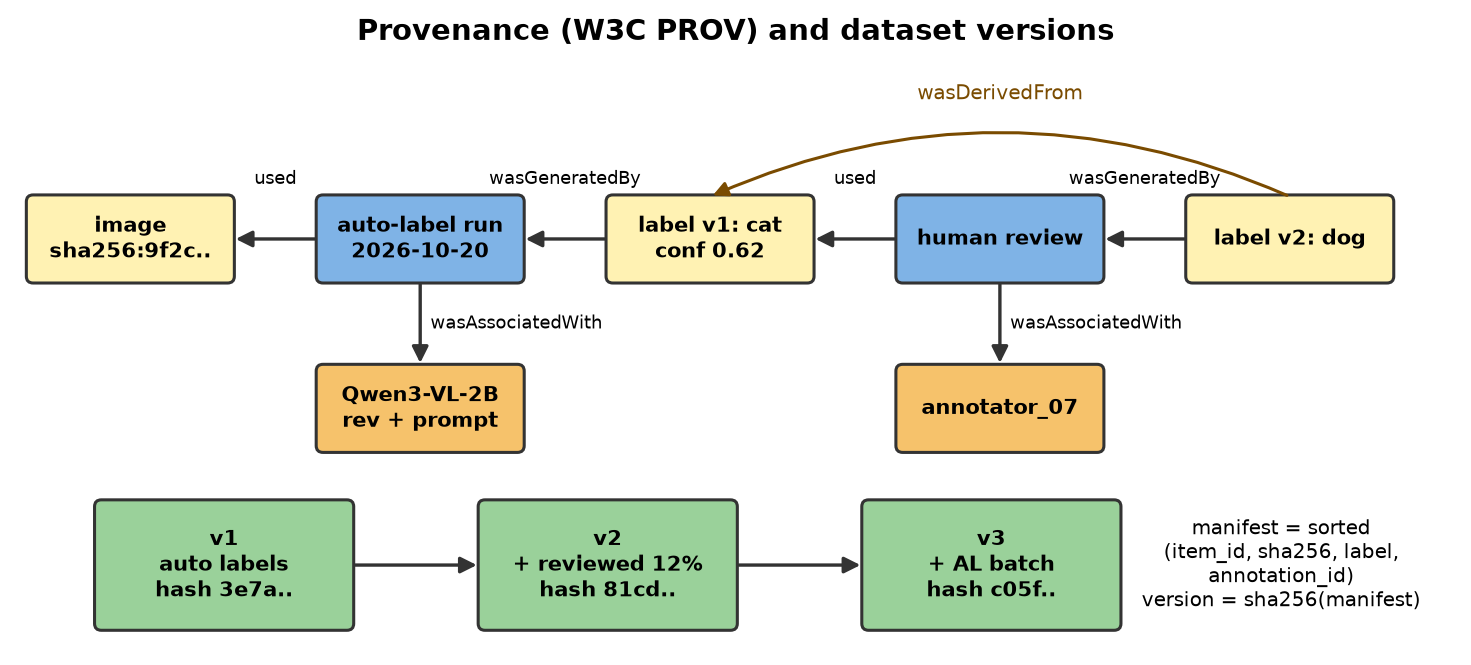

### 13.1. Provenance меток

Provenance (происхождение) метки — ответ на вопросы: кто или что поставил метку, когда, по какой версии инструкции и схемы, какой моделью (идентификатор и ревизия весов), с каким промптом и параметрами декодирования, из какой предыдущей метки она получена. Стандартная модель — W3C [PROV-DM](https://www.w3.org/TR/prov-dm/) (рекомендация W3C от 30 апреля 2013 года):

- entity — объект данных (изображение, метка, версия датасета);
- activity — действие, которое использовало и породило сущности (прогон авторазметки, проверка человеком);
- agent — кто отвечает за действие (модель, разметчик, организация);
- отношения: `used` (действие использовало сущность), `wasGeneratedBy` (сущность порождена действием), `wasAssociatedWith` (действие связано с агентом), `wasAttributedTo` (сущность приписана агенту), `wasDerivedFrom` (сущность получена из другой).

Практическая реализация — журнал аннотаций только на добавление (append-only JSONL): метки никогда не перезаписываются; исправление — новая запись со ссылкой `derived_from` на исходную. Тогда можно восстановить любую версию, найти все метки, поставленные определённой ревизией модели (если в ней нашли ошибку), и посчитать, сколько исправлений внёс каждый разметчик.

### 13.2. Версионирование

Датасет — это не папка, а версия: детерминированный манифест (идентификатор объекта, хеш содержимого, идентификатор аннотации), а идентификатор версии — хеш манифеста. Свойства:

- одинаковые данные дают одинаковый идентификатор, любое изменение — другой;
- в описании эксперимента достаточно указать идентификатор версии данных рядом с коммитом кода;
- diff между версиями — это diff манифестов: какие метки изменились и почему.

[DVC](https://dvc.org/doc/start/data-management/data-versioning) реализует ту же идею для больших файлов: в git хранится маленький файл `.dvc` с MD5-хешем данных, сами данные лежат в кеше, адресуемом этим хешем, а переход к версии — `git checkout` плюс `dvc checkout`.

### 13.3. Утечки и дубликаты

Версионирование должно включать проверку разбиений: точные дубликаты находятся по хешам, почти-дубликаты — по близости эмбеддингов (CLIP, DINOv2) или перцептивным хешам. Утечки между train и test завышают качество, как показал пример ciFAIR (раздел 1.2). При разметке потоков (видео, серии снимков одного объекта) разбиение делают по группам (по видео, пациенту, месту съёмки), а не по отдельным кадрам.

### 13.4. Документация

[Datasheets for Datasets](https://arxiv.org/abs/1803.09010) предлагают стандартный набор вопросов о мотивации, составе, процессе сбора, предобработке и разметке, использовании, распространении и сопровождении датасета. [Data Cards](https://arxiv.org/abs/2204.01075) — практический формат такой документации. Для автоматически размеченных данных особенно важно указать модели и их версии, долю меток, проверенных человеком, оценку доли ошибок с методом её получения и известные систематические ошибки.

## 14. Практические рекомендации

1. Начинайте со схемы и инструкции, проверенных на пилотной выборке с несколькими разметчиками. Измерьте согласие людей — это потолок, к которому стремится авторазметка.
2. Используйте закрытые списки и constrained decoding везде, где это возможно; свободный текст оставляйте для полей, где он действительно нужен. Повтор с обратной связью — для API без гарантий формата; объекты, не прошедшие повтор, — человеку.
3. Получайте white-box уверенность (вероятность метки), если модель локальная; для закрытых API — self-consistency по нескольким видам и промптам. Калибруйте на размеченной выборке и проверяйте калибровку после каждого изменения модели или данных.
4. Используйте вторую модель с максимально независимыми ошибками; расхождения — первые кандидаты на проверку.
5. Оценивайте долю ошибок стратифицированным случайным аудитом с доверительным интервалом; отдельно тратьте бюджет на поиск ошибок (confident learning, низкая уверенность).
6. В active learning всегда сравнивайте со случайной выборкой на нескольких сидах; для старта используйте типичные объекты или zero-shot кандидатов; для батчей — гибриды неопределённости и разнообразия.
7. Учитывайте, что человек подвержен влиянию подсказок; вставляйте контрольные объекты и часть проверок делайте вслепую.
8. Ведите append-only журнал аннотаций с полным provenance, версионируйте датасет хешем манифеста, проверяйте утечки между разбиениями, пишите datasheet.

# Часть II. Практика

Практика воспроизводит весь цикл data-centric разметки на CIFAR-10. Классы CIFAR-10 известны, поэтому эталон есть для каждого изображения. Он играет роль «человека-эксперта» (oracle): мы показываем эталонную метку только тогда, когда по протоколу человек действительно посмотрел бы на изображение. Так можно честно измерить качество автоматической разметки и цену ручной проверки. Важно понимать ограничение: oracle никогда не ошибается и не устаёт, а настоящий человек ошибается (раздел 12.2 теории). Поэтому все оценки стоимости в практике оптимистичны.

| Раздел | Что делаем | Модели |
|---|---|---|
| 1. Данные | манифест с хешами, стратифицированное разбиение, проверка дубликатов | — |
| 2. Загрузка VLM | memory probe, переход 4B → 2B, ревизия весов | Qwen3-VL-4B / 2B |
| 3. Схема | Pydantic-модель → JSON Schema, валидация, сообщения об ошибках | — |
| 4. Structured generation | свободный JSON, схема в промпте, повтор с обратной связью, constrained decoding, маскирование токенов | Qwen3-VL |
| 5. Авторазметка | метки VLM с вероятностями, self-consistency по нескольким видам изображения, вторая модель | Qwen3-VL, CLIP ViT-B/32 |
| 6. Контроль качества | κ, AUROC прокси уверенности, калибровка, стратифицированный аудит, confident learning | CLIP |
| 7. Active learning | семь стратегий, смещение выборки, критерий остановки, cold start | логистическая регрессия на признаках CLIP |
| 8. Human-in-the-loop | маршрутизация по уверенности, стоимость, влияние на downstream-модель | — |
| 9. Provenance и версии | журнал аннотаций, манифест, хеш версии, diff, datasheet, поиск утечек | — |

Режимы запуска:

- GPU (Colab T4) — основной режим: Qwen3-VL-4B в 4-bit, сотни изображений для VLM и тысячи для active learning.
- CPU — режим проверки кода (`FAST_DEV_RUN = True`): Qwen3-VL-2B в bfloat16 и малые выборки. Выводы, сохранённые в блокноте, получены именно так. Числа по VLM на 6–20 изображениях шумные; разделы 6–9 используют CLIP на 2000 изображениях и информативны и на CPU.

## 0. Установка и конфигурация

In [1]:
import importlib, subprocess, sys

def ensure(pkg, spec=None):
    """Импортирует пакет, а если его нет — ставит через pip."""
    try:
        return importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec or pkg], check=False)
        return importlib.import_module(pkg)

import torch
HAS_GPU = torch.cuda.is_available()

# Qwen3-VL поддерживается в transformers начиная с 4.57
import transformers
from packaging.version import Version
if Version(transformers.__version__) < Version("4.57.0"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers>=4.57", "accelerate"], check=False)
    print("transformers обновлён: перезапустите среду (Runtime → Restart session) и запустите блокнот заново.")
for pkg, spec in [("accelerate", None), ("pandas", None), ("pyarrow", None), ("scipy", None),
                  ("sklearn", "scikit-learn"), ("pydantic", "pydantic>=2"), ("jsonschema", None)]:
    ensure(pkg, spec)
if HAS_GPU:
    ensure("bitsandbytes")

import importlib.metadata as md
VERSIONS = {p: md.version(p) for p in ["torch", "transformers", "pydantic", "jsonschema", "scikit-learn", "numpy"]}
print(VERSIONS, "| GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "нет")

{'torch': '2.14.1+cpu', 'transformers': '5.19.0', 'pydantic': '2.14.1', 'jsonschema': '4.26.0', 'scikit-learn': '1.9.1', 'numpy': '2.5.2'} | GPU: нет


In [2]:
import os, gc, io, re, json, time, math, random, hashlib, datetime, platform
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from huggingface_hub import hf_hub_download
from transformers import AutoProcessor, AutoModelForImageTextToText

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

MODEL_CANDIDATES = ["Qwen/Qwen3-VL-4B-Instruct", "Qwen/Qwen3-VL-2B-Instruct"]   # 4B → 2B при нехватке памяти
VRAM_BUDGET_GB = None        # None — вся свободная память GPU; например 3, чтобы увидеть переход на 2B
CLIP_ID = "openai/clip-vit-base-patch32"
FAST_DEV_RUN = not HAS_GPU

def n_(gpu, cpu):
    """Размер выборки: полный на GPU, уменьшенный в режиме FAST_DEV_RUN."""
    return cpu if FAST_DEV_RUN else gpu

N_POOL   = n_(8000, 2000)   # неразмеченный пул (для CLIP-разметки и active learning)
N_TEST   = n_(2000, 1000)   # отложенный тест, не используется ни для каких решений
N_VLM    = n_(300, 20)      # изображения, размечаемые VLM
N_FORMAT = n_(40, 6)        # изображения для сравнения режимов structured generation
IMG_SIDE = 256              # CIFAR 32×32 увеличиваем до 256×256 → 8×8 = 64 визуальных токена Qwen3-VL

if HAS_GPU:
    COMPUTE_DTYPE = torch.bfloat16 if torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16   # T4 → fp16
else:
    COMPUTE_DTYPE = torch.bfloat16
DEVICE = "cuda" if HAS_GPU else "cpu"
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
RESULTS = []    # итоговая таблица: (раздел, метрика, значение)

def record(section, metric, value):
    RESULTS.append(dict(section=section, metric=metric, value=value))

print("DEVICE:", DEVICE, "| dtype:", COMPUTE_DTYPE, "| FAST_DEV_RUN:", FAST_DEV_RUN)

DEVICE: cpu | dtype: torch.bfloat16 | FAST_DEV_RUN: True


## 1. Данные: манифест, разбиение, дубликаты

Берём тестовую часть [CIFAR-10](https://huggingface.co/datasets/uoft-cs/cifar10) (10 000 изображений 32×32, 10 классов по 1000) в формате parquet. Первое, что делается с любыми данными в data-centric подходе, — манифест: постоянный идентификатор каждого объекта, хеш его содержимого и источник. Хеш SHA-256 байтов изображения позволяет:

- находить точные дубликаты;
- проверять, что объект в версии датасета не подменён;
- ссылаться на объект в журнале аннотаций независимо от пути к файлу.

Затем делаем стратифицированное разбиение: отложенный тест (на нём только измеряем), неразмеченный пул (из него выбираем, что размечать) и подвыборку пула для VLM.

изображений: 10000 | ревизия датасета: 0b2714987fa4
точных дубликатов по SHA-256: 0
{'test': 1000, 'pool': 2000, 'vlm subset': 20}
           item_id                                                           sha256 split
cifar10/test/00021 f86e26bedc5b45261ee4ebbf1d46283ae49afddc6446d0877c4c5f9d25976e34  test
cifar10/test/00028 c4c7f8cbcc0b29dd555b011bb335295d253d2c17e9a2452eee17b37559e94f87  test
cifar10/test/00036 d5f51a299843a26985aefcc6999f215d6dce45a8ad71f9c5ce60e9de2312799a  test


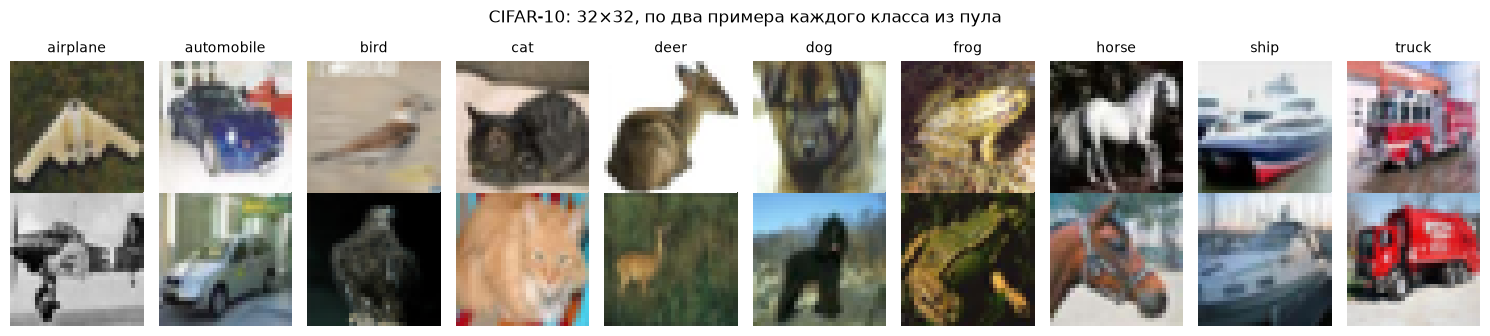

In [3]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
DATA_REPO, DATA_FILE = "uoft-cs/cifar10", "plain_text/test-00000-of-00001.parquet"
path = hf_hub_download(DATA_REPO, DATA_FILE, repo_type="dataset")
DATA_REVISION = Path(path).parent.parent.name if "snapshots" in path else "unknown"   # commit датасета на Hub
raw = pd.read_parquet(path)
raw["item_id"] = [f"cifar10/test/{i:05d}" for i in range(len(raw))]
raw["sha256"] = raw.img.map(lambda d: hashlib.sha256(d["bytes"]).hexdigest())
raw["truth"] = raw.label.map(lambda i: CLASSES[i])
print("изображений:", len(raw), "| ревизия датасета:", DATA_REVISION[:12])
print("точных дубликатов по SHA-256:", int(raw.sha256.duplicated().sum()))

def stratified_split(df, sizes, seed=SEED):
    """Делит df на части заданных размеров с равной долей каждого класса."""
    rng = np.random.default_rng(seed)
    parts = {k: [] for k in sizes}
    for c, g in df.groupby("label"):
        idx = rng.permutation(g.index.values)
        start = 0
        for k, n in sizes.items():
            m = n // len(CLASSES)
            parts[k].extend(idx[start:start + m]); start += m
    return {k: df.loc[sorted(v)].reset_index(drop=True) for k, v in parts.items()}

S = stratified_split(raw, {"test": N_TEST, "pool": N_POOL})
test_df, pool_df = S["test"], S["pool"]
vlm_df = stratified_split(pool_df, {"vlm": N_VLM})["vlm"]
assert not set(test_df.sha256) & set(pool_df.sha256), "пересечение пула и теста"

def to_pil(row):
    return Image.open(io.BytesIO(row["img"]["bytes"])).convert("RGB")

manifest = pd.concat([test_df.assign(split="test"), pool_df.assign(split="pool")])[["item_id", "sha256", "split"]]
manifest.to_csv(ART / "images_manifest.csv", index=False)
print({k: len(v) for k, v in [("test", test_df), ("pool", pool_df), ("vlm subset", vlm_df)]})
print(manifest.head(3).to_string(index=False))

fig, axs = plt.subplots(2, 10, figsize=(15, 3.4))
for c in range(10):
    for r in range(2):
        row = pool_df[pool_df.label == c].iloc[r]
        axs[r, c].imshow(to_pil(row)); axs[r, c].axis("off")
        if r == 0:
            axs[r, c].set_title(CLASSES[c], fontsize=10)
plt.suptitle("CIFAR-10: 32×32, по два примера каждого класса из пула", fontsize=12); plt.tight_layout(); plt.show()

Точных дубликатов нет, но это не значит, что нет почти-дубликатов: одно и то же фото с другим сжатием или кадрированием даёт другой хеш. Для CIFAR известно, что заметная часть тестовых изображений имеет почти-дубликаты в обучающей части ([ciFAIR](https://arxiv.org/abs/1902.00423)). Почти-дубликаты ищут по близости эмбеддингов; мы сделаем это в разделе 4, когда получим признаки CLIP.

## 2. VLM: загрузка с memory probe

Используем ту же процедуру, что в лекции 6: пробуем Qwen3-VL-4B в 4-bit NF4, проверяем пик памяти на самом тяжёлом запросе этой практики (изображение 256×256 и ответ до 160 токенов), при нехватке переходим на 2B. На CPU сразу грузится 2B в bfloat16.

In [4]:
def free_memory():
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()

def load_vlm(model_id):
    proc = AutoProcessor.from_pretrained(model_id)
    if HAS_GPU:
        from transformers import BitsAndBytesConfig
        bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                 bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=COMPUTE_DTYPE)
        model = AutoModelForImageTextToText.from_pretrained(model_id, quantization_config=bnb,
                                                            dtype=COMPUTE_DTYPE, device_map={"": 0})
    else:
        model = AutoModelForImageTextToText.from_pretrained(model_id, dtype=COMPUTE_DTYPE)
    return model.eval(), proc

def chat_text(proc, prompt, with_image=True, system=None, prefill=""):
    """Шаблон чата; prefill — начало ответа ассистента, которое мы навязываем модели."""
    content = ([{"type": "image"}] if with_image else []) + [{"type": "text", "text": prompt}]
    msgs = ([{"role": "system", "content": [{"type": "text", "text": system}]}] if system else []) + \
           [{"role": "user", "content": content}]
    return proc.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True) + prefill

def vlm_inputs(img, prompt, prefill="", system=None):
    text = chat_text(proc, prompt, img is not None, system, prefill)
    if img is None:
        return proc(text=[text], return_tensors="pt").to(model.device)
    img = img.convert("RGB").resize((IMG_SIDE, IMG_SIDE), Image.BICUBIC)
    return proc(text=[text], images=[img], return_tensors="pt").to(model.device)

def vlm_generate(img, prompt, max_new_tokens=96, prefill="", sample=False, temperature=1.0,
                 allowed_fn=None, stop=None, seed=None):
    inputs = vlm_inputs(img, prompt, prefill)
    kw = dict(max_new_tokens=max_new_tokens, do_sample=sample)
    if sample:
        kw.update(temperature=temperature, top_p=1.0, top_k=0)
        if seed is not None:
            torch.manual_seed(seed)
    else:
        kw.update(temperature=None, top_p=None, top_k=None)
    if allowed_fn is not None:
        kw["prefix_allowed_tokens_fn"] = allowed_fn(inputs["input_ids"].shape[1])
    if stop:
        kw.update(stop_strings=stop, tokenizer=proc.tokenizer)
    t0 = time.time()
    with torch.inference_mode():
        out = model.generate(**inputs, **kw)
    new = out[0, inputs["input_ids"].shape[1]:]
    return dict(text=proc.decode(new, skip_special_tokens=True), seconds=time.time() - t0, n_new=int(len(new)))

def memory_probe(candidates, budget_gb=VRAM_BUDGET_GB):
    global model, proc
    log = []
    if HAS_GPU:
        total = torch.cuda.get_device_properties(0).total_memory / 2**30
        if budget_gb is not None:
            torch.cuda.set_per_process_memory_fraction(min(1.0, budget_gb / total), 0)
        budget = budget_gb if budget_gb is not None else torch.cuda.mem_get_info()[0] / 2**30
    else:
        candidates, budget = [c for c in candidates if "2B" in c], None
    for mid in candidates:
        model = proc = None
        try:
            if HAS_GPU:
                torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
            model, proc = load_vlm(mid)
            probe = Image.fromarray(np.random.default_rng(0).integers(0, 255, (IMG_SIDE, IMG_SIDE, 3), dtype=np.uint8))
            r = vlm_generate(probe, "Describe this image in detail.", max_new_tokens=160)
            peak = torch.cuda.max_memory_allocated() / 2**30 if HAS_GPU else float("nan")
            ok = budget is None or peak <= 0.9 * budget
            log.append(dict(model=mid, status="ok" if ok else "over budget", peak_GiB=round(peak, 2),
                            weights_GiB=round(model.get_memory_footprint() / 2**30, 2), probe_s=round(r["seconds"], 1)))
            if ok:
                return mid, pd.DataFrame(log)
        except (torch.cuda.OutOfMemoryError, MemoryError, RuntimeError, ValueError) as e:
            if not isinstance(e, (torch.cuda.OutOfMemoryError, MemoryError)) and "memory" not in str(e).lower():
                raise
            log.append(dict(model=mid, status="OOM", error=str(e)[:80]))
        model = proc = None
        free_memory()
    raise RuntimeError("Ни одна модель не прошла memory probe")

MODEL_ID, PROBE_LOG = memory_probe(MODEL_CANDIDATES)
# ревизия весов (commit на Hub) — обязательная часть provenance
MODEL_REVISION = Path(hf_hub_download(MODEL_ID, "config.json")).parent.name
print("Модель:", MODEL_ID, "| ревизия:", MODEL_REVISION[:12])
PROBE_LOG

Модель: Qwen/Qwen3-VL-2B-Instruct | ревизия: 89644892e4d8


,model,status,peak_GiB,weights_GiB,probe_s
0,Qwen/Qwen3-VL-2B-Instruct,ok,NaN,3.96,48.5


## 3. Схема разметки: Pydantic → JSON Schema

Схема — это контракт между тем, кто размечает (человек или модель), и всеми, кто потом использует метки. Мы описываем её один раз как класс Pydantic и из него получаем:

- JSON Schema, которую можно вставить в промпт или передать движку constrained decoding;
- валидатор с понятными сообщениями об ошибках, которые можно вернуть модели при повторе.

Решения, заложенные в схему:

- `class_name` — закрытый список (enum) из 10 классов CIFAR-10 и явного класса `other`. Без `other` модель вынуждена выбрать ближайший класс даже для изображения «вне таксономии», и такие ошибки потом невозможно отличить от обычных.
- `caption` — короткое описание от 3 до 120 символов. Ограничение длины защищает от «простыней» и пустых строк.
- `uncertain` — флаг, которым разметчик сам сообщает о сомнении. Он нужен для маршрутизации на проверку человеком.
- `confidence` — число от 0 до 1. Мы увидим, что словесная уверенность модели и вероятность её токенов — разные величины.
- `extra="forbid"` превращается в `additionalProperties: false`: лишние поля считаются ошибкой, а не тихо отбрасываются.
- Версия схемы и её хеш попадают в каждую аннотацию: если таксономия изменится, будет видно, какие метки размечены по старым правилам.

In [5]:
from typing import Literal
from pydantic import BaseModel, Field, ConfigDict, ValidationError
import jsonschema

LABELS = CLASSES + ["other"]
SCHEMA_VERSION = "cifar_image_label/1.0.0"

class ImageLabel(BaseModel):
    """One annotation of a CIFAR-10 image."""
    model_config = ConfigDict(extra="forbid")
    class_name: Literal[tuple(LABELS)] = Field(description="main object class; 'other' if none fits")
    caption: str = Field(min_length=3, max_length=120, description="short English caption")
    uncertain: bool = Field(description="true if the image is ambiguous")
    confidence: float = Field(ge=0.0, le=1.0, description="confidence in class_name, 0..1")

JSON_SCHEMA = ImageLabel.model_json_schema()
SCHEMA_SHA = hashlib.sha256(json.dumps(JSON_SCHEMA, sort_keys=True).encode()).hexdigest()
print("schema:", SCHEMA_VERSION, "| sha256:", SCHEMA_SHA[:16])
(ART / "schema.json").write_text(json.dumps(JSON_SCHEMA, indent=2))
print(json.dumps(JSON_SCHEMA, indent=1)[:1000], "...")

schema: cifar_image_label/1.0.0 | sha256: c8736a326507a6a3
{
 "additionalProperties": false,
 "description": "One annotation of a CIFAR-10 image.",
 "properties": {
  "class_name": {
   "description": "main object class; 'other' if none fits",
   "enum": [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
    "other"
   ],
   "title": "Class Name",
   "type": "string"
  },
  "caption": {
   "description": "short English caption",
   "maxLength": 120,
   "minLength": 3,
   "title": "Caption",
   "type": "string"
  },
  "uncertain": {
   "description": "true if the image is ambiguous",
   "title": "Uncertain",
   "type": "boolean"
  },
  "confidence": {
   "description": "confidence in class_name, 0..1",
   "maximum": 1.0,
   "minimum": 0.0,
   "title": "Confidence",
   "type": "number"
  }
 },
 "required": [
  "class_name",
  "caption",
  "uncertain",
  "confidence"
 ],
 "title": "ImageLabel",
 "type": "obje

Проверим схему на типичных ошибках, которые реально встречаются в ответах моделей. Один и тот же объект проверяем двумя способами: стандартным валидатором JSON Schema (так проверит любой сервис на любом языке) и Pydantic (так удобно в Python, и сообщения короче).

In [6]:
validator = jsonschema.Draft202012Validator(JSON_SCHEMA)
cases = {
    "valid":            {"class_name": "cat", "caption": "a cat sitting on grass", "uncertain": False, "confidence": 0.9},
    "class not in enum": {"class_name": "kitten", "caption": "a small kitten", "uncertain": False, "confidence": 0.9},
    "extra field":      {"class_name": "dog", "caption": "a dog", "uncertain": False, "confidence": 0.8, "breed": "pug"},
    "missing field":    {"class_name": "ship", "uncertain": False, "confidence": 0.7},
    "out of range":     {"class_name": "frog", "caption": "a green frog", "uncertain": False, "confidence": 1.7},
    "too long caption": {"class_name": "bird", "caption": "a bird " * 30, "uncertain": True, "confidence": 0.4},
    "wrong type":       {"class_name": "deer", "caption": "a deer", "uncertain": "no", "confidence": "high"},
}
rows = []
for name, obj in cases.items():
    js_err = [f"{'/'.join(map(str, e.path)) or '(root)'}: {e.message[:60]}" for e in validator.iter_errors(obj)]
    try:
        ImageLabel.model_validate(obj, strict=True); pd_err = []
    except ValidationError as e:
        pd_err = [f"{'.'.join(map(str, x['loc']))}: {x['msg'][:50]}" for x in e.errors()]
    rows.append(dict(case=name, jsonschema_ok=not js_err, pydantic_ok=not pd_err,
                     first_error=(js_err or ["—"])[0]))
pd.DataFrame(rows)

,case,jsonschema_ok,pydantic_ok,first_error
0,valid,True,True,—
1,class not in enum,False,False,class_name: 'kitten' is not one of ['airplane'...
2,extra field,False,False,(root): Additional properties are not allowed ...
3,missing field,False,False,(root): 'caption' is a required property
4,out of range,False,False,confidence: 1.7 is greater than the maximum of...
5,too long caption,False,False,caption: 'a bird a bird a bird a bird a bird a...
6,wrong type,False,False,uncertain: 'no' is not of type 'boolean'


Оба валидатора согласны во всех случаях. Обратите внимание на `strict=True`: без него Pydantic по умолчанию приводит типы (строку `"0.9"` превратит в число), а JSON Schema такого не делает. Для разметки строгий режим безопаснее: неожиданный тип — повод разобраться, а не молча исправить.

Теперь функция разбора ответа модели. Модели часто оборачивают JSON в блок кода Markdown или добавляют фразу перед ним, поэтому сначала извлекаем первый объект `{...}`, потом валидируем. Функция возвращает либо объект, либо короткое описание ошибки — оно понадобится для повтора с обратной связью.

In [7]:
def extract_json(text):
    """Достаёт первый JSON-объект из ответа (учитывает ```json ... ``` и текст вокруг)."""
    text = re.sub(r"```(?:json)?", "", text)
    start = text.find("{")
    if start < 0:
        raise ValueError("no JSON object found")
    depth, in_str, esc = 0, False, False
    for i, ch in enumerate(text[start:], start):
        if in_str:
            esc = (ch == "\\") and not esc
            if ch == '"' and not esc:
                in_str = False
            continue
        if ch == '"':
            in_str = True
        elif ch == "{":
            depth += 1
        elif ch == "}":
            depth -= 1
            if depth == 0:
                return json.loads(text[start:i + 1])
    raise ValueError("unterminated JSON object")

def parse_label(text):
    """→ (ImageLabel | None, сообщение об ошибке | None)."""
    try:
        obj = extract_json(text)
    except (ValueError, json.JSONDecodeError) as e:
        return None, f"not valid JSON: {str(e)[:80]}"
    try:
        return ImageLabel.model_validate(obj, strict=True), None
    except ValidationError as e:
        return None, "; ".join(f"{'.'.join(map(str, x['loc'])) or 'root'}: {x['msg']}" for x in e.errors())[:300]

for t in ['```json\n{"class_name": "cat", "caption": "a cat", "uncertain": false, "confidence": 0.8}\n```',
          'Sure! {"class": "cat", "description": "a cat"}',
          '{"class_name": "cat", "caption": "a cat", "uncertain": false, "confidence": 0.8']:
    print(parse_label(t))

(ImageLabel(class_name='cat', caption='a cat', uncertain=False, confidence=0.8), None)
(None, 'class_name: Field required; caption: Field required; uncertain: Field required; confidence: Field required; class: Extra inputs are not permitted; description: Extra inputs are not permitted')
(None, 'not valid JSON: unterminated JSON object')


## 4. Structured generation: четыре режима

Сравним на одних и тех же изображениях четыре основных способа (и один вспомогательный) получить от VLM валидную аннотацию (теория — разделы 4–5).

| Режим | Как | Что гарантирует |
|---|---|---|
| A. Свободный JSON | просим «ответь в JSON» без схемы | ничего: ключи и значения на усмотрение модели |
| A + повтор | как A, но при невалидном ответе повторный запрос содержит схему, прошлый ответ и ошибку валидатора | показывает, насколько обратная связь исправляет «плохой» первый ответ |
| B. Схема в промпте | вставляем JSON Schema и список классов | ничего формально, но обычно сильно лучше A |
| C. B + повтор | при невалидном ответе возвращаем модели ошибку валидатора, до 3 попыток | валидность с вероятностью $1-(1-p)^3$ при независимых попытках |
| D. Constrained | ответ начинается с навязанного префикса `{"class_name": "`, класс выбирается только среди разрешённых токенов, остальной JSON собирается кодом | валидность по построению |

Режим D — упрощённый, но честный вариант constrained decoding. Полноценные движки ([Outlines](https://github.com/dottxt-ai/outlines), [XGrammar](https://github.com/mlc-ai/xgrammar), грамматики GBNF в [llama.cpp](https://github.com/ggml-org/llama.cpp/blob/master/grammars/README.md)) на каждом шаге маскируют все токены, которые нарушили бы грамматику. Нам достаточно маскировать на одном шаге — выборе класса, — потому что остальная структура фиксирована. Бонус: на этом шаге мы получаем полное распределение вероятностей по 11 меткам, то есть white-box прокси уверенности.

Первые токены названий классов в словаре Qwen различны (`air`, `autom`, `bird`, `cat`, ...), поэтому вероятность класса равна вероятности его первого токена после префикса. Ниже это проверяется явно.

In [8]:
tok = proc.tokenizer
PREFILL = '{"class_name": "'
pre_ids = tok(PREFILL, add_special_tokens=False).input_ids
FIRST_TOKEN = {}
for lab in LABELS:
    ids = tok(PREFILL + lab + '"', add_special_tokens=False).input_ids
    assert ids[:len(pre_ids)] == pre_ids, "токенизация префикса зависит от продолжения"
    FIRST_TOKEN[lab] = ids[len(pre_ids)]
assert len(set(FIRST_TOKEN.values())) == len(LABELS), "первые токены классов совпадают"
LABEL_TOKEN_IDS = torch.tensor([FIRST_TOKEN[l] for l in LABELS])
print({l: tok.decode([i]) for l, i in FIRST_TOKEN.items()})

SCHEMA_PROMPT = (
    "Classify the main object in this image (a low-resolution CIFAR-10 photo).\n"
    f"Allowed classes: {', '.join(LABELS)}. Use \"other\" only if none fits.\n"
    "Return only a JSON object, no markdown, that matches this JSON Schema:\n"
    + json.dumps(JSON_SCHEMA, separators=(",", ":")))
FREE_PROMPT = ("What is the main object in this image? Answer in JSON with the object class, "
               "a short caption, whether you are uncertain, and your confidence from 0 to 1.")
PROMPT_SHA = {k: hashlib.sha256(v.encode()).hexdigest() for k, v in
              [("schema", SCHEMA_PROMPT), ("free", FREE_PROMPT)]}

@torch.inference_mode()
def class_distribution(img, prompt=SCHEMA_PROMPT):
    """Один прямой проход с префиксом → распределение по LABELS и доля массы, попавшая в разрешённые токены."""
    inputs = vlm_inputs(img, prompt, prefill=PREFILL)
    logits = model(**inputs).logits[0, -1].float()
    p_full = torch.softmax(logits, -1)
    p_lab = p_full[LABEL_TOKEN_IDS]
    return (p_lab / p_lab.sum()).cpu().numpy(), float(p_lab.sum())

def label_constrained(img):
    """Режим D: класс из маскированного распределения + caption с остановкой на кавычке."""
    t0 = time.time()
    p, mass = class_distribution(img)
    k = int(p.argmax()); lab = LABELS[k]
    prefill = PREFILL + lab + '", "caption": "'
    r = vlm_generate(img, SCHEMA_PROMPT, max_new_tokens=32, prefill=prefill, stop=['"'])
    cap = r["text"].split('"')[0].strip()[:120]
    if len(cap) < 3:
        cap = f"a photo of a {lab}"
    obj = {"class_name": lab, "caption": cap, "uncertain": bool(p[k] < 0.5), "confidence": round(float(p[k]), 4)}
    text = json.dumps(obj)
    return dict(text=text, p=p, mass=mass, seconds=time.time() - t0, n_new=r["n_new"] + 1)

{'airplane': 'air', 'automobile': 'autom', 'bird': 'bird', 'cat': 'cat', 'deer': 'deer', 'dog': 'dog', 'frog': 'frog', 'horse': 'horse', 'ship': 'ship', 'truck': 'truck', 'other': 'other'}


Повтор с обратной связью (режим C). Модели возвращается её же ответ и текст ошибки валидатора. Это обычно эффективнее «слепого» повтора: модель видит, какое именно поле нарушено. Каждая попытка сохраняется — в реальном конвейере журнал попыток нужен для анализа того, какие ошибки модель делает систематически.

In [9]:
def label_with_retry(img, first_prompt=SCHEMA_PROMPT, max_attempts=3):
    """Повтор с обратной связью: в повторный запрос входят схема, прошлый ответ и ошибка валидатора."""
    attempts, prompt = [], first_prompt
    for a in range(max_attempts):
        r = vlm_generate(img, prompt, max_new_tokens=96)
        obj, err = parse_label(r["text"])
        attempts.append(dict(attempt=a + 1, text=r["text"], error=err, seconds=r["seconds"], n_new=r["n_new"]))
        if obj is not None:
            break
        prompt = (SCHEMA_PROMPT + "\n\nYour previous answer was invalid.\nPrevious answer: " + r["text"][:400]
                  + "\nValidation error: " + err + "\nReturn only the corrected JSON object.")
    return attempts

fmt_df = vlm_df.groupby("label", group_keys=False).head(max(1, N_FORMAT // 10)).head(N_FORMAT).reset_index(drop=True)
fmt_rows, examples = [], {}
for i, row in fmt_df.iterrows():
    img = to_pil(row)
    for mode in ["A", "A+retry", "B", "C", "D"]:
        if mode == "A":
            r = vlm_generate(img, FREE_PROMPT, max_new_tokens=96); att = [dict(text=r["text"], seconds=r["seconds"], n_new=r["n_new"])]
        elif mode == "A+retry":
            att = label_with_retry(img, first_prompt=FREE_PROMPT)
        elif mode == "B":
            r = vlm_generate(img, SCHEMA_PROMPT, max_new_tokens=96); att = [dict(text=r["text"], seconds=r["seconds"], n_new=r["n_new"])]
        elif mode == "C":
            att = label_with_retry(img)
        else:
            r = label_constrained(img); att = [dict(text=r["text"], seconds=r["seconds"], n_new=r["n_new"])]
        obj, err = parse_label(att[-1]["text"])
        fmt_rows.append(dict(item=row.item_id, truth=row.truth, mode=mode, valid=obj is not None,
                             correct=obj is not None and obj.class_name == row.truth,
                             attempts=len(att), seconds=sum(a["seconds"] for a in att),
                             tokens=sum(a["n_new"] for a in att), error=err))
        if mode not in examples or (err and not examples[mode][2]):
            examples[mode] = (row.truth, att[0]["text"][:220], parse_label(att[0]["text"])[1], len(att))
fmt = pd.DataFrame(fmt_rows)
summary = fmt.groupby("mode").agg(valid_rate=("valid", "mean"), accuracy=("correct", "mean"),
                                  mean_attempts=("attempts", "mean"), sec_per_image=("seconds", "mean"),
                                  gen_tokens=("tokens", "mean")).round(3)
summary = summary.loc[["A", "A+retry", "B", "C", "D"]]
summary.index = ["A free JSON", "A + retry with schema feedback", "B schema in prompt", "C = B + retry", "D constrained"]
for m in ["A", "A+retry", "B", "C", "D"]:
    record("4 structured generation", f"valid rate, mode {m}", float(fmt[fmt["mode"] == m].valid.mean()))
print("изображений:", len(fmt_df))
summary

изображений: 6


,valid_rate,accuracy,mean_attempts,sec_per_image,gen_tokens
A free JSON,0.0,0.0,1.0,72.396,50.5
A + retry with schema feedback,1.0,1.0,2.0,132.337,98.0
B schema in prompt,1.0,1.0,1.0,71.499,47.0
C = B + retry,1.0,1.0,1.0,62.863,47.0
D constrained,1.0,1.0,1.0,63.454,9.5


In [10]:
for m, (truth, text, err, n_att) in examples.items():
    print(f"--- режим {m} (эталон: {truth}; попыток: {n_att})\nпервый ответ: {text}\nошибка валидации первого ответа: {err}\n")
print(fmt[fmt.error.notna()].groupby("mode").error.apply(lambda s: s.str.split(":").str[0].value_counts().to_dict()))

--- режим A (эталон: airplane; попыток: 1)
первый ответ: ```json
{
  "object_class": "model airplane",
  "short_caption": "A red model airplane with a biplane design.",
  "you_are_uncertain": false,
  "confidence": 0.95
}
```
ошибка валидации первого ответа: class_name: Field required; caption: Field required; uncertain: Field required; object_class: Extra inputs are not permitted; short_caption: Extra inputs are not permitted; you_are_uncertain: Extra inputs are not permitted

--- режим A+retry (эталон: airplane; попыток: 2)
первый ответ: ```json
{
  "object_class": "model airplane",
  "short_caption": "A red model airplane with a biplane design.",
  "you_are_uncertain": false,
  "confidence": 0.95
}
```
ошибка валидации первого ответа: class_name: Field required; caption: Field required; uncertain: Field required; object_class: Extra inputs are not permitted; short_caption: Extra inputs are not permitted; you_are_uncertain: Extra inputs are not permitted

--- режим B (эталон: airplan

Что показал прогон (CPU, Qwen3-VL-2B, 6 изображений; на GPU с 4B выборка больше, но картина обычно та же):

- A (свободный JSON): 0 % валидных ответов. Модель охотно отвечает в JSON, но придумывает свои ключи (`object_class`, `short_caption`, `you_are_uncertain`) и пишет класс свободным текстом (`model airplane`). Синтаксически это JSON, по схеме — нет: «ответь в JSON» не равно «ответь по нашей схеме».
- A + повтор: все 6 ответов стали валидными со второй попытки, и все классы верны. Обратная связь от валидатора (какие поля отсутствуют, какие лишние) плюс схема в повторном запросе исправляют формат за одну итерацию, но удваивают стоимость.
- B (схема в промпте): 100 % валидных с первой попытки, поэтому в режиме C повтор ни разу не понадобился. Обратите внимание на первый ответ B: он обёрнут в блок кода Markdown. Строгий парсер `json.loads(text)` его бы отверг; валидным его делает функция `extract_json`. Такой «ремонт» безопасен, потому что не меняет значений.
- D (constrained): 100 % валидных по построению и всего около 10 сгенерированных токенов вместо 47: структуру JSON пишет код, модель генерирует только подпись. По времени на CPU D не выигрывает, потому что делает два прохода по изображению (распределение класса и подпись), а на CPU доминирует обработка входа. В рабочей системе второй проход переиспользует KV-кеш первого.
- Точность класса у всех валидных режимов 100 % — на 6 простых изображениях режимы различаются форматом, а не качеством. Разница в точности, если она есть, видна на сотнях изображений в режиме GPU.

Вывод для практики: схема в промпте — минимальная норма; повтор с обратной связью нужен как страховка; constrained decoding даёт гарантию и, что не менее важно, вероятность класса (следующий раздел).

### 4.1. Маскирование через `prefix_allowed_tokens_fn`

В `transformers` есть общий механизм ограничения генерации: функция `prefix_allowed_tokens_fn(batch_id, input_ids)` на каждом шаге возвращает список разрешённых следующих токенов ([документация](https://huggingface.co/docs/transformers/main_classes/text_generation)). Построим префиксное дерево (trie) токенов всех допустимых ответов и разрешим только продолжения, которые остаются внутри дерева. Это та же идея, что в Outlines и XGrammar, только для конечного списка строк вместо грамматики.

Сравним свободный однословный ответ и ограниченный. Свободная модель отвечает «как ей удобно»: с заглавной буквы, с точкой, синонимом (`Car` вместо `automobile`), и такой ответ нужно ещё нормализовать. Ограниченная модель обязана выбрать строку из списка.

In [11]:
def build_trie(strings):
    trie = {}
    for s in strings:
        node = trie
        for t in tok(s, add_special_tokens=False).input_ids + [tok.convert_tokens_to_ids("<|im_end|>")]:
            node = node.setdefault(t, {})
    return trie

TRIE = build_trie(LABELS)

def trie_allowed(prompt_len):
    def fn(batch_id, input_ids):
        node = TRIE
        for t in input_ids[prompt_len:].tolist():
            node = node.get(t)
            if node is None:              # вышли из дерева (не должно случаться)
                return [tok.convert_tokens_to_ids("<|im_end|>")]
        return list(node.keys()) or [tok.convert_tokens_to_ids("<|im_end|>")]
    return fn

WORD_PROMPT = f"What is the main object in this image? Answer with one word from: {', '.join(LABELS)}."
trie_rows = []
for _, row in fmt_df.iterrows():
    img = to_pil(row)
    free = vlm_generate(img, WORD_PROMPT, max_new_tokens=8)["text"].strip()
    cons = vlm_generate(img, WORD_PROMPT, max_new_tokens=8, allowed_fn=trie_allowed)["text"].strip()
    trie_rows.append(dict(truth=row.truth, free_answer=free, free_exact_match=free in LABELS,
                          constrained_answer=cons, constrained_in_set=cons in LABELS))
pd.DataFrame(trie_rows)

,truth,free_answer,free_exact_match,constrained_answer,constrained_in_set
0,airplane,airplane,True,airplane,True
1,horse,horse,True,horse,True
2,cat,cat,True,cat,True
3,dog,dog,True,dog,True
4,truck,truck,True,truck,True
5,ship,ship,True,ship,True


На этих 6 изображениях свободный однословный ответ всегда совпал с допустимой меткой: когда список классов указан в промпте, Qwen3-VL-2B его соблюдает. Ограничение здесь ничего не изменило — и это нормальный результат: маска нужна не потому, что модель обычно ошибается в формате, а потому, что на десятках тысяч изображений редкие отклонения (`Car`, `kitten`, `A cat.`) неизбежны, и каждое из них ломает конвейер или требует ручной нормализации. Маска делает такой исход невозможным, не меняя ответов там, где модель и так права.

## 5. Авторазметка: VLM, self-consistency и вторая модель

### 5.1. VLM: распределение по классам для нескольких «видов» изображения

Для каждого изображения из подвыборки получаем распределение по 11 меткам (режим D) в трёх вариантах:

1. исходное изображение и основной промпт;
2. зеркально отражённое изображение (test-time augmentation, TTA): метка класса от отражения не меняется, поэтому смена ответа — признак неустойчивости;
3. исходное изображение и перефразированный промпт: смена ответа от формулировки — тоже признак неустойчивости.

Из этих распределений строим прокси уверенности:

- $p_{\max}$ и margin (разность двух старших вероятностей) первого вида — white-box уверенность;
- согласие видов — доля видов, у которых argmax совпал с итоговой меткой;
- среднее распределение по видам — простой ансамбль.

Сэмплирование (self-consistency в смысле [Wang et al.](https://arxiv.org/abs/2203.11171)) здесь не требует новых проходов модели: класс задаётся одним токеном, поэтому сэмплирование ответа при температуре 1 эквивалентно выбору класса из уже вычисленного распределения. Мы сэмплируем K = 10 «ответов» и считаем долю голосов за моду — это black-box прокси, которое доступно и для закрытого API, где вероятности не возвращаются.

In [12]:
PARA_PROMPT = SCHEMA_PROMPT.replace("Classify the main object in this image (a low-resolution CIFAR-10 photo).",
                                    "Which category best describes the object shown in this small photo?")
VIEWS = {"original": (lambda im: im, SCHEMA_PROMPT),
         "hflip":    (ImageOps.mirror, SCHEMA_PROMPT),
         "paraphrase": (lambda im: im, PARA_PROMPT)}
K_SAMPLES = 10
rng_sc = np.random.default_rng(SEED)
vlm_rows, t0 = [], time.time()
for _, row in vlm_df.iterrows():
    img = to_pil(row)
    P = np.stack([class_distribution(f(img), pr)[0] for f, pr in VIEWS.values()])
    p0 = P[0]; srt = np.sort(p0)[::-1]
    lab = LABELS[int(p0.argmax())]
    votes = rng_sc.choice(len(LABELS), size=K_SAMPLES, p=p0 / p0.sum())
    vlm_rows.append(dict(item_id=row.item_id, truth=row.truth, vlm_label=lab,
                         p_max=float(srt[0]), margin=float(srt[0] - srt[1]),
                         view_agree=float(np.mean(P.argmax(1) == p0.argmax())),
                         sc_vote=float(np.mean(votes == np.bincount(votes).argmax())),
                         ens_label=LABELS[int(P.mean(0).argmax())], ens_p=float(P.mean(0).max())))
vlm_lab = pd.DataFrame(vlm_rows)
print(f"{len(vlm_lab)} изображений, {time.time() - t0:.0f} с ({(time.time() - t0) / len(vlm_lab) / len(VIEWS):.1f} с на проход)")
vlm_lab["vlm_correct"] = vlm_lab.vlm_label == vlm_lab.truth
print("точность VLM (вид 1):", round(vlm_lab.vlm_correct.mean(), 3),
      "| ансамбль 3 видов:", round((vlm_lab.ens_label == vlm_lab.truth).mean(), 3),
      "| все 3 вида согласны:", round((vlm_lab.view_agree == 1).mean(), 3))
record("5 auto-labelling", "VLM accuracy (view 1)", float(vlm_lab.vlm_correct.mean()))
vlm_lab.head(8).round(3)

20 изображений, 1472 с (24.5 с на проход)
точность VLM (вид 1): 0.9 | ансамбль 3 видов: 0.95 | все 3 вида согласны: 0.95


,item_id,truth,vlm_label,p_max,margin,view_agree,sc_vote,ens_label,ens_p,vlm_correct
0,cifar10/test/00281,airplane,airplane,1.000,1.000,1.0,1.0,airplane,1.000,True
1,cifar10/test/01224,horse,horse,1.000,1.000,1.0,1.0,horse,1.000,True
2,cifar10/test/02207,cat,cat,1.000,1.000,1.0,1.0,cat,1.000,True
3,cifar10/test/03204,dog,dog,0.998,0.996,1.0,1.0,dog,0.995,True
4,cifar10/test/03264,dog,dog,1.000,1.000,1.0,1.0,dog,1.000,True
5,cifar10/test/03846,truck,truck,1.000,1.000,1.0,1.0,truck,1.000,True
6,cifar10/test/03870,ship,ship,1.000,0.999,1.0,1.0,ship,1.000,True
7,cifar10/test/04045,horse,horse,1.000,1.000,1.0,1.0,horse,1.000,True


### 5.2. Вторая модель: CLIP zero-shot

Вторая модель должна ошибаться иначе, чем первая; иначе её согласие ничего не добавляет. CLIP ViT-B/32 обучен контрастивно, а не генеративно, имеет другую архитектуру и данные, поэтому подходит. Используем ансамбль текстовых шаблонов (лекция 5) и признаки изображений для разделов 6–9. Для TTA считаем признаки и отражённых изображений.

In [13]:
from transformers import CLIPModel, CLIPProcessor
clip = CLIPModel.from_pretrained(CLIP_ID).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)

def _as_tensor(out):
    """transformers 5 возвращает объект с pooler_output, 4.x — тензор."""
    return out if torch.is_tensor(out) else out.pooler_output

@torch.inference_mode()
def clip_image_features(df, flip=False, bs=128):
    feats = []
    for s in range(0, len(df), bs):
        ims = [to_pil(r) for _, r in df.iloc[s:s + bs].iterrows()]
        if flip:
            ims = [ImageOps.mirror(im) for im in ims]
        x = clip_proc(images=ims, return_tensors="pt").to(DEVICE)
        f = _as_tensor(clip.get_image_features(**x)).float()
        feats.append(torch.nn.functional.normalize(f, dim=-1).cpu())
    return torch.cat(feats).numpy()

TEMPLATES = ["a photo of a {}.", "a blurry photo of a {}.", "a low resolution photo of a {}.",
             "a photo of the small {}.", "a pixelated photo of a {}.", "a close-up photo of a {}."]
with torch.inference_mode():
    W = []
    for c in CLASSES:
        x = clip_proc(text=[t.format(c) for t in TEMPLATES], return_tensors="pt", padding=True).to(DEVICE)
        e = torch.nn.functional.normalize(_as_tensor(clip.get_text_features(**x)).float(), dim=-1).mean(0)
        W.append(torch.nn.functional.normalize(e, dim=0).cpu())
    W = torch.stack(W).numpy()
CLIP_SCALE = float(clip.logit_scale.detach().exp())

t0 = time.time()
F_pool, F_pool_flip = clip_image_features(pool_df), clip_image_features(pool_df, flip=True)
F_test = clip_image_features(test_df)
print(f"признаки CLIP: пул {F_pool.shape}, тест {F_test.shape}, {time.time() - t0:.0f} с")

def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

y_pool, y_test = pool_df.label.values, test_df.label.values
Z_pool, Z_flip = CLIP_SCALE * F_pool @ W.T, CLIP_SCALE * F_pool_flip @ W.T
P_clip = softmax(Z_pool)
clip_pred = P_clip.argmax(1)
clip_acc = float((clip_pred == y_pool).mean())
print("CLIP zero-shot на пуле:", round(clip_acc, 4))
record("5 auto-labelling", "CLIP zero-shot accuracy (pool)", clip_acc)
# логистическая регрессия на нормированных признаках CLIP (разделы 6–8): одна и та же сила регуляризации
# для всех экспериментов; при C≈1 модель на 10–40 метках почти не обучается (вспомните раздел 10.7 теории)
C_LR = 30.0

признаки CLIP: пул (2000, 512), тест (1000, 512), 210 с
CLIP zero-shot на пуле: 0.8895


In [14]:
pos = {iid: i for i, iid in enumerate(pool_df.item_id)}
vi = vlm_lab.item_id.map(pos).values
vlm_lab["clip_label"] = [CLASSES[k] for k in clip_pred[vi]]
vlm_lab["clip_p"] = P_clip[vi].max(1)
vlm_lab["models_agree"] = vlm_lab.vlm_label == vlm_lab.clip_label
agree = vlm_lab[vlm_lab.models_agree]; dis = vlm_lab[~vlm_lab.models_agree]
print(f"VLM и CLIP согласны на {len(agree)}/{len(vlm_lab)}; точность там, где согласны: "
      f"{agree.vlm_correct.mean():.3f}; там, где нет: VLM {dis.vlm_correct.mean() if len(dis) else float('nan'):.3f}, "
      f"CLIP {(dis.clip_label == dis.truth).mean() if len(dis) else float('nan'):.3f}")
vlm_lab[~vlm_lab.models_agree | ~vlm_lab.vlm_correct][["item_id", "truth", "vlm_label", "p_max", "view_agree", "clip_label", "clip_p"]].round(3)

VLM и CLIP согласны на 19/20; точность там, где согласны: 0.947; там, где нет: VLM 0.000, CLIP 0.000


,item_id,truth,vlm_label,p_max,view_agree,clip_label,clip_p
9,cifar10/test/04441,automobile,truck,0.977,1.000,truck,0.712
15,cifar10/test/06502,frog,other,0.730,0.333,dog,0.367


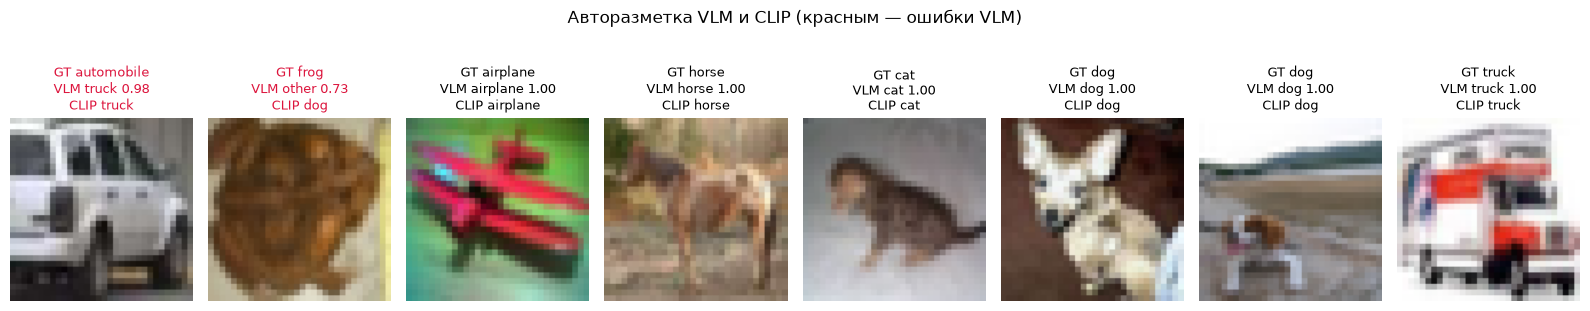

In [15]:
fig, axs = plt.subplots(1, min(8, len(vlm_lab)), figsize=(16, 3.4))
show = pd.concat([vlm_lab[~vlm_lab.vlm_correct], vlm_lab[vlm_lab.vlm_correct]]).head(len(axs))
for ax, (_, r) in zip(axs, show.iterrows()):
    ax.imshow(to_pil(pool_df.iloc[pos[r.item_id]]).resize((96, 96), Image.NEAREST)); ax.axis("off")
    ax.set_title(f"GT {r.truth}\nVLM {r.vlm_label} {r.p_max:.2f}\nCLIP {r.clip_label}", fontsize=9,
                 color="crimson" if not r.vlm_correct else "black")
plt.suptitle("Авторазметка VLM и CLIP (красным — ошибки VLM)", fontsize=12, y=0.99); plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

Результаты на 20 изображениях (CPU, 2B):

- точность VLM по первому виду — 90 % (2 ошибки из 20), ансамбль трёх видов — 95 %: он исправил ошибку на лягушке, где виды расходились (согласие видов 0.33);
- ошибка `frog → other` сопровождается низкой уверенностью ($p_{\max} = 0.73$) и расхождением видов — прокси уверенности её «видят»;
- ошибка `automobile → truck` — уверенная ($p_{\max} = 0.98$), устойчивая по всем трём видам, и CLIP ошибается так же. На изображении белый внедорожник или пикап — именно пограничный случай таксономии CIFAR-10 (раздел 3.1 теории). Ни self-consistency, ни согласие моделей такую ошибку не ловят: обе модели одинаково понимают слово `truck` иначе, чем авторы датасета. Такие ошибки находит только человек или уточнение инструкции (например, добавить в промпт определения классов);
- VLM и CLIP согласны в 19 случаях из 20, и среди согласованных меток одна ошибочная (та самая общая). Согласие — сильный фильтр, но не гарантия.

CLIP zero-shot на всём пуле — 88.95 %; эти метки используются в разделах 6–9 как «автоматическая разметка» большого объёма.

## 6. Контроль качества

### 6.1. Согласие: Cohen κ и Fleiss κ

Сырой процент совпадений завышает согласие, если классы несбалансированы или оба разметчика часто выбирают один и тот же класс. Каппа вычитает согласие, ожидаемое случайно (теория, раздел 9):

$$ \kappa = \frac{p_o - p_e}{1 - p_e}. $$

Cohen κ — для пары разметчиков, Fleiss κ — для нескольких разметчиков, каждый из которых размечает все объекты. Как трёх «разметчиков» для Fleiss κ возьмём VLM (вид 1), ансамбль трёх видов VLM и CLIP.

In [16]:
from sklearn.metrics import cohen_kappa_score, confusion_matrix, roc_auc_score

def fleiss_kappa(ratings, categories):
    """ratings: массив (n_items, n_raters) меток."""
    n, r = ratings.shape
    counts = np.stack([(ratings == c).sum(1) for c in categories], 1)
    p_j = counts.sum(0) / (n * r)
    P_i = (np.sum(counts ** 2, 1) - r) / (r * (r - 1))
    P_bar, P_e = P_i.mean(), np.sum(p_j ** 2)
    return (P_bar - P_e) / (1 - P_e)

k_rows = [("VLM vs GT", cohen_kappa_score(vlm_lab.vlm_label, vlm_lab.truth)),
          ("CLIP vs GT", cohen_kappa_score(vlm_lab.clip_label, vlm_lab.truth)),
          ("VLM vs CLIP", cohen_kappa_score(vlm_lab.vlm_label, vlm_lab.clip_label)),
          ("CLIP vs GT, весь пул", cohen_kappa_score(clip_pred, y_pool))]
k_df = pd.DataFrame(k_rows, columns=["pair", "cohen_kappa"])
k_df["raw_agreement"] = [np.mean(vlm_lab.vlm_label == vlm_lab.truth), np.mean(vlm_lab.clip_label == vlm_lab.truth),
                         np.mean(vlm_lab.vlm_label == vlm_lab.clip_label), clip_acc]
fk = fleiss_kappa(vlm_lab[["vlm_label", "ens_label", "clip_label"]].values, LABELS)
print(f"Fleiss κ (VLM вид 1, ансамбль VLM, CLIP; n = {len(vlm_lab)}): {fk:.3f}")
record("6 QC", "Cohen kappa CLIP vs GT (pool)", float(k_rows[3][1]))
k_df.round(3)

Fleiss κ (VLM вид 1, ансамбль VLM, CLIP; n = 20): 0.944


,pair,cohen_kappa,raw_agreement
0,VLM vs GT,0.890,0.90
1,CLIP vs GT,0.889,0.90
2,VLM vs CLIP,0.944,0.95
3,"CLIP vs GT, весь пул",0.877,0.89


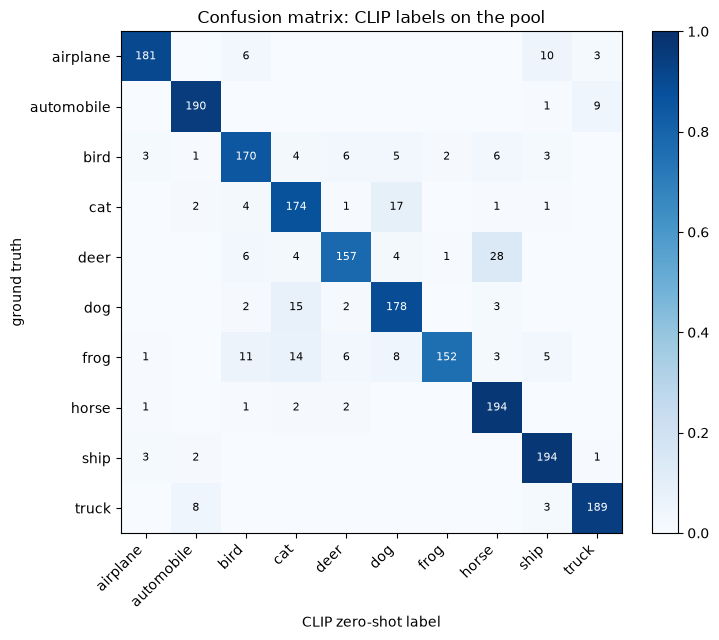

частые путаницы (GT → CLIP): [('deer', 'horse', 28), ('cat', 'dog', 17), ('dog', 'cat', 15), ('frog', 'cat', 14), ('frog', 'bird', 11)]


In [17]:
cm = confusion_matrix(y_pool, clip_pred, labels=range(10))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm[i].sum() / 2 else "black")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("CLIP zero-shot label"); ax.set_ylabel("ground truth"); ax.set_title("Confusion matrix: CLIP labels on the pool")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:5], off.shape))[0]
print("частые путаницы (GT → CLIP):", [(CLASSES[a], CLASSES[b], int(off[a, b])) for a, b in top])

Наблюдения:

- На 20 изображениях κ(VLM, CLIP) = 0.944 выше, чем κ каждой модели с эталоном (0.89). Модели согласны друг с другом больше, чем с истиной, — признак коррелированных ошибок (общая ошибка `automobile → truck`). Высокое согласие моделей нельзя принимать за высокую точность.
- На пуле из 2000 изображений CLIP даёт κ = 0.877 с эталоном при 88.95 % совпадений: при 10 сбалансированных классах $p_e \approx 0.1$, поэтому κ лишь немного ниже доли совпадений. При сильном дисбалансе разница была бы гораздо больше (пример в разделе 9.1 теории).
- Матрица путаницы показывает класс-зависимый шум: чаще всего CLIP путает оленя с лошадью (28 случаев), кошку с собакой (17 и 15 в обе стороны), лягушку с кошкой и птицей. Это и есть пары, для которых в инструкции нужны пограничные примеры и куда в первую очередь стоит направлять ручную проверку.

### 6.2. Прокси уверенности: какое лучше отделяет ошибки

Хорошее прокси уверенности должно ранжировать: у ошибочных меток оно ниже, чем у верных. Меру ранжирования даёт AUROC задачи «верна ли метка»: 0.5 — прокси бесполезно, 1 — идеально отделяет. Сравниваем на метках CLIP по всему пулу (там тысячи объектов) и на метках VLM (на CPU объектов мало, оценка шумная).

In [18]:
def entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

correct = clip_pred == y_pool
srtP = np.sort(P_clip, 1)
proxies = {"p_max": srtP[:, -1], "margin": srtP[:, -1] - srtP[:, -2], "neg_entropy": -entropy(P_clip),
           "TTA agree (hflip)": (Z_flip.argmax(1) == clip_pred).astype(float),
           "p_max x TTA agree": srtP[:, -1] * (Z_flip.argmax(1) == clip_pred)}
au = pd.DataFrame([dict(model="CLIP (pool)", proxy=k, AUROC=roc_auc_score(correct, v)) for k, v in proxies.items()])
if vlm_lab.vlm_correct.nunique() == 2:
    for k in ["p_max", "margin", "view_agree", "sc_vote", "clip_p"]:
        au.loc[len(au)] = dict(model=f"VLM (n={len(vlm_lab)})", proxy=k, AUROC=roc_auc_score(vlm_lab.vlm_correct, vlm_lab[k]))
    au.loc[len(au)] = dict(model=f"VLM (n={len(vlm_lab)})", proxy="agrees with CLIP",
                           AUROC=roc_auc_score(vlm_lab.vlm_correct, vlm_lab.models_agree.astype(float)))
else:
    print("У VLM на этой выборке нет ошибок (или нет верных ответов): AUROC для VLM не определён.")
record("6 QC", "AUROC p_max (CLIP pool)", float(au.AUROC[0]))
au.round(3)

,model,proxy,AUROC
0,CLIP (pool),p_max,0.887
1,CLIP (pool),margin,0.889
2,CLIP (pool),neg_entropy,0.877
3,CLIP (pool),TTA agree (hflip),0.637
4,CLIP (pool),p_max x TTA agree,0.886
5,VLM (n=20),p_max,1.000
6,VLM (n=20),margin,1.000
7,VLM (n=20),view_agree,0.750
8,VLM (n=20),sc_vote,1.000
9,VLM (n=20),clip_p,0.972


### 6.3. Калибровка и temperature scaling

Прокси может хорошо ранжировать и при этом быть смещённым: «0.9» может означать 75 % верных ответов. Для порога маршрутизации нам нужны калиброванные вероятности. Проверим калибровку с помощью ECE (expected calibration error) и диаграммы надёжности, а затем подберём одну температуру $T$ на небольшом размеченном наборе (200 объектов, которые проверил бы человек) по минимуму отрицательного логарифма правдоподобия ([Guo et al.](https://arxiv.org/abs/1706.04599)):

$$ \hat p = \mathrm{softmax}(z / T), \qquad T^* = \arg\min_T \; -\sum_{i \in \text{cal}} \log \hat p_{i, y_i}(T). $$

Температура не меняет argmax, поэтому точность меток не меняется — меняется только смысл чисел.

T* = 0.768;  ECE до: 0.0467,  после: 0.0201  (на 1800 объектах вне калибровочного набора)


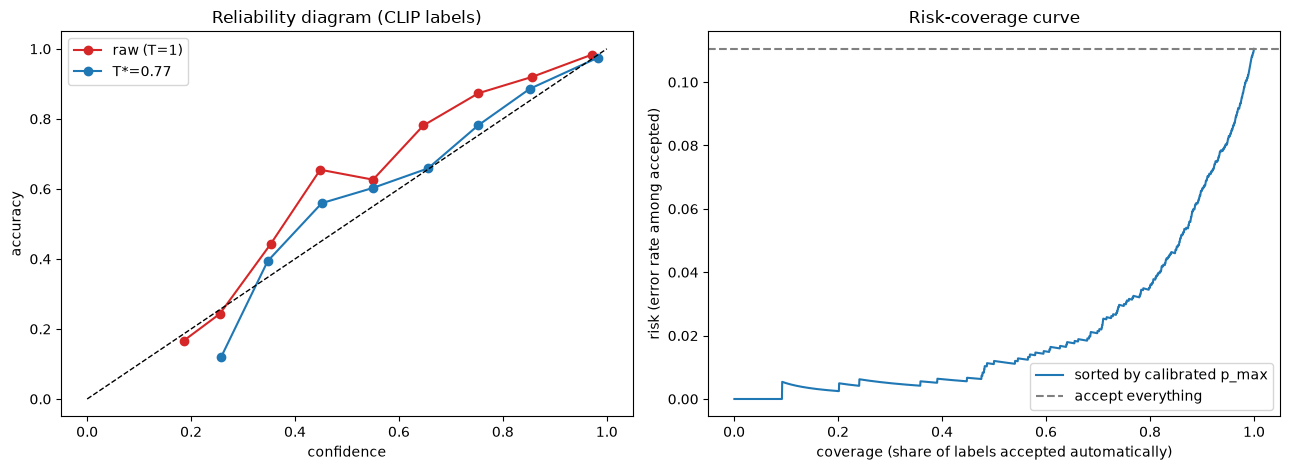

,target_risk,coverage
0,0.01,0.4815
1,0.02,0.6850
2,0.05,0.8570


In [19]:
from scipy.optimize import minimize_scalar

def ece(P, y, bins=15):
    conf, pred = P.max(1), P.argmax(1)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return e

rng_cal = np.random.default_rng(SEED)
cal_idx = rng_cal.choice(len(pool_df), 200, replace=False)
eval_mask = np.ones(len(pool_df), bool); eval_mask[cal_idx] = False
nll = lambda logT: -np.log(softmax(Z_pool[cal_idx] / np.exp(logT))[np.arange(200), y_pool[cal_idx]] + 1e-12).mean()
T_STAR = float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))
P_cal = softmax(Z_pool / T_STAR)
print(f"T* = {T_STAR:.3f};  ECE до: {ece(P_clip[eval_mask], y_pool[eval_mask]):.4f},  "
      f"после: {ece(P_cal[eval_mask], y_pool[eval_mask]):.4f}  (на {eval_mask.sum()} объектах вне калибровочного набора)")
record("6 QC", "ECE before temperature scaling", float(ece(P_clip[eval_mask], y_pool[eval_mask])))
record("6 QC", "ECE after temperature scaling", float(ece(P_cal[eval_mask], y_pool[eval_mask])))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for P, name, c in [(P_clip, "raw (T=1)", "tab:red"), (P_cal, f"T*={T_STAR:.2f}", "tab:blue")]:
    conf, ok = P[eval_mask].max(1), (P[eval_mask].argmax(1) == y_pool[eval_mask])
    edges = np.linspace(0, 1, 11); mids, accs = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 5:
            mids.append(conf[m].mean()); accs.append(ok[m].mean())
    axs[0].plot(mids, accs, "o-", color=c, label=name)
axs[0].plot([0, 1], [0, 1], "k--", lw=1); axs[0].set_xlabel("confidence"); axs[0].set_ylabel("accuracy")
axs[0].set_title("Reliability diagram (CLIP labels)"); axs[0].legend()
# risk–coverage
order = np.argsort(-P_cal.max(1)); err_sorted = (~correct)[order]
cov = np.arange(1, len(order) + 1) / len(order); risk = np.cumsum(err_sorted) / np.arange(1, len(order) + 1)
axs[1].plot(cov, risk, color="tab:blue", label="sorted by calibrated p_max")
axs[1].axhline((~correct).mean(), color="gray", ls="--", label="accept everything")
axs[1].set_xlabel("coverage (share of labels accepted automatically)"); axs[1].set_ylabel("risk (error rate among accepted)")
axs[1].set_title("Risk-coverage curve"); axs[1].legend(); plt.tight_layout(); plt.show()
rc = pd.DataFrame([dict(target_risk=r, coverage=float(cov[risk <= r].max()) if (risk <= r).any() else 0.0) for r in [0.01, 0.02, 0.05]])
rc

Выводы:

- Ранжирование: $p_{\max}$, margin и энтропия CLIP почти одинаково хорошо отделяют ошибки (AUROC 0.88–0.89). Согласие с отражённым изображением само по себе слабое прокси (0.64): оно бинарное и ловит лишь часть ошибок, — но полезно как дополнительная проверка в маршрутизации (раздел 8). У VLM на 20 изображениях всего 2 ошибки, поэтому AUROC VLM (1.0 у $p_{\max}$, 0.75 у согласия видов и у согласия с CLIP) статистически ничего не значит; он показывает лишь, что одну из двух ошибок согласие не заметило.
- Калибровка: CLIP с шаблонами промптов оказался недоуверенным — на диаграмме надёжности красная кривая выше диагонали, и $T^* = 0.77 < 1$ заостряет распределение. ECE снизилась с 0.047 до 0.020 на объектах, не участвовавших в подборе $T$. Направление поправки заранее неизвестно: глубокие сети чаще переуверены ([Guo et al.](https://arxiv.org/abs/1706.04599)), здесь — наоборот, поэтому калибровку всегда проверяют на данных.
- Risk–coverage: при общей доле ошибок 11 % можно автоматически принять 48 % меток с риском не выше 1 %, 68.5 % — с риском не выше 2 % и 86 % — с риском не выше 5 %. Это и есть «бюджет доверия» к автоматической разметке.

### 6.4. Стратифицированная ручная проверка

Сколько ошибок в автоматических метках? Проверить всё дорого, поэтому проверяем выборку и оцениваем долю ошибок с доверительным интервалом (теория, раздел 8). Сравним три плана с одинаковым бюджетом 100 проверок:

- простая случайная выборка (SRS);
- стратифицированная по калиброванной уверенности, пропорциональное размещение $n_h \propto N_h$;
- стратифицированная, размещение Неймана $n_h \propto N_h \sigma_h$, где $\sigma_h = \sqrt{e_h (1 - e_h)}$, а априорная доля ошибок $e_h$ берётся из калиброванной уверенности: $e_h = 1 - \bar p_h$. Знать истинную долю ошибок не нужно.

Оценка в стратифицированном плане: $\hat e = \sum_h W_h \hat e_h$, $W_h = N_h / N$, дисперсия $\sum_h W_h^2 (1 - n_h/N_h)\, \hat e_h (1 - \hat e_h) / (n_h - 1)$. Повторяем аудит 2000 раз и смотрим смещение, разброс и покрытие 95 % доверительного интервала.

In [20]:
conf_cal = P_cal.max(1); err = (~correct).astype(float)
strata = np.digitize(conf_cal, [0.8, 0.97])              # 0: <0.8, 1: 0.8–0.97, 2: ≥0.97
st = pd.DataFrame(dict(stratum=strata, err=err, conf=conf_cal)).groupby("stratum").agg(
    N=("err", "size"), true_error=("err", "mean"), mean_conf=("conf", "mean"))
st.index = ["low (<0.80)", "mid (0.80-0.97)", "high (>=0.97)"][:len(st)]
TRUE_ERR, BUDGET, REPS = err.mean(), 100, 2000
Nh = st.N.values; Wh = Nh / Nh.sum(); prior_sigma = np.sqrt(np.clip(1 - st.mean_conf.values, 1e-3, None) * st.mean_conf.values)

def allocate(weights):
    n = np.maximum(2, np.floor(BUDGET * weights / weights.sum())).astype(int)
    while n.sum() > BUDGET: n[n.argmax()] -= 1
    while n.sum() < BUDGET: n[np.argmax(weights / n)] += 1
    return np.minimum(n, Nh)

plans = {"SRS": None, "stratified, proportional": allocate(Nh.astype(float)),
         "stratified, Neyman (prior from confidence)": allocate(Nh * prior_sigma)}
rng_a = np.random.default_rng(SEED); groups = [np.where(strata == h)[0] for h in range(len(Nh))]
audit = []
for name, n_h in plans.items():
    est, cover, width = [], [], []
    for _ in range(REPS):
        if n_h is None:
            s = err[rng_a.choice(len(err), BUDGET, replace=False)]
            e_hat = s.mean(); var = e_hat * (1 - e_hat) / (BUDGET - 1) * (1 - BUDGET / len(err))
        else:
            e_h = np.array([err[rng_a.choice(g, k, replace=False)].mean() for g, k in zip(groups, n_h)])
            e_hat = float(Wh @ e_h)
            var = float(np.sum(Wh ** 2 * (1 - n_h / Nh) * e_h * (1 - e_h) / (n_h - 1)))
        half = 1.96 * math.sqrt(var)
        est.append(e_hat); cover.append(abs(e_hat - TRUE_ERR) <= half); width.append(2 * half)
    est = np.array(est)
    audit.append(dict(plan=name, allocation="—" if n_h is None else str(n_h.tolist()), bias=est.mean() - TRUE_ERR,
                      std=est.std(), RMSE=np.sqrt(((est - TRUE_ERR) ** 2).mean()),
                      CI95_coverage=np.mean(cover), mean_CI_width=np.mean(width)))
audit = pd.DataFrame(audit)
print(f"истинная доля ошибок CLIP-меток в пуле: {TRUE_ERR:.4f}")
display(st.round(4)); 
record("6 QC", "audit RMSE, SRS", float(audit.RMSE[0])); record("6 QC", "audit RMSE, Neyman", float(audit.RMSE[2]))
audit.round(4)

истинная доля ошибок CLIP-меток в пуле: 0.1105


,N,true_error,mean_conf
low (<0.80),412,0.4029,0.5695
mid (0.80-0.97),416,0.0913,0.9062
high (>=0.97),1172,0.0145,0.9927


,plan,allocation,bias,std,RMSE,CI95_coverage,mean_CI_width
0,SRS,—,-0.0009,0.0300,0.0301,0.9225,0.1184
1,"stratified, proportional","[21, 21, 58]",0.0001,0.0265,0.0265,0.9405,0.1038
2,"stratified, Neyman (prior from confidence)","[48, 29, 23]",0.0005,0.0230,0.0230,0.9205,0.0846


Результаты 2000 повторений аудита (истинная доля ошибок 11.05 %):

- Страты сильно различаются: в страте низкой уверенности 40 % ошибок, в средней 9 %, в высокой 1.45 %. Априорные оценки из калиброванной уверенности (43 %, 9.4 % и 0.7 %) близки к истинным, поэтому размещение Неймана ([48, 29, 23] проверок) — разумное.
- Все три оценки несмещённые (смещение не больше 0.1 п. п.), различается разброс: RMSE 3.0 п. п. у простой случайной выборки, 2.65 у пропорционального размещения и 2.3 у размещения Неймана. Дисперсия у Неймана в $(3.01/2.30)^2 \approx 1.7$ раза меньше, то есть та же точность достигается примерно на 40 % меньшим бюджетом — как и в численном примере раздела 8.3 теории.
- Покрытие нормального 95 % интервала — 92–94 %, ниже номинала. Причина — нормальное приближение для редких событий: в страте высокой уверенности при 23 проверках и доле ошибок 1.45 % часто не находится ни одной ошибки, и оценка дисперсии этой страты равна нулю. Для аудита редких ошибок используют интервалы Уилсона или Клоппера — Пирсона (задание 5).

### 6.5. Поиск ошибок разметки: confident learning

Попробуем найти ошибочные метки без эталона идеей [confident learning](https://arxiv.org/abs/1911.00068) (теория, раздел 7.2):

1. обучаем классификатор (логистическую регрессию на признаках CLIP) на шумных метках и получаем вероятности out-of-fold (5-кратная кросс-валидация: объект никогда не оценивается моделью, которая на нём училась);
2. для каждого класса $k$ порог $t_k$ — средняя предсказанная вероятность класса $k$ у объектов с меткой $k$;
3. объект подозрителен, если его «уверенный» класс $\arg\max_{k:\, p_k \ge t_k} p_k$ отличается от данной метки.

Проверим метод на двух видах шума с примерно одинаковой долей ошибок:

- метки CLIP zero-shot — систематический шум модели: ошибка определяется самим изображением и признаками CLIP;
- «человеческий» шум: случайная доля меток заменяется на похожий класс (по матрице путаницы), как это бывает у невнимательного разметчика.

База для сравнения — столько же объектов с наименьшей out-of-fold вероятностью данной метки (self-confidence). Затем обучаем downstream-модель на исходных метках, на метках без подозрительных объектов и на эталоне.

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold

def confident_learning(X, noisy):
    P = cross_val_predict(LogisticRegression(C=C_LR, max_iter=3000), X, noisy,
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")
    t = np.array([P[noisy == j, j].mean() for j in range(10)])
    above = P >= t
    conf_cls = np.where(above.any(1), np.where(above, P, -1).argmax(1), noisy)
    return conf_cls != noisy, conf_cls, P

def downstream(Xtr, ytr):
    m = LogisticRegression(C=C_LR, max_iter=3000).fit(Xtr, ytr); return float(m.score(F_test, y_test))

# «человеческий» шум: с вероятностью rate метка заменяется на класс, с которым её часто путают
conf_mat = confusion_matrix(y_pool, clip_pred, labels=range(10)).astype(float); np.fill_diagonal(conf_mat, 0)
conf_mat = (conf_mat + 0.5) / (conf_mat + 0.5).sum(1, keepdims=True)
rng_n = np.random.default_rng(SEED); flip = rng_n.random(len(y_pool)) < (clip_pred != y_pool).mean()
human_noisy = y_pool.copy()
human_noisy[flip] = [rng_n.choice(10, p=conf_mat[c]) for c in y_pool[flip]]

cl_rows, ds_rows = [], []
for name, noisy in [("CLIP zero-shot labels (systematic)", clip_pred), ("random class-conditional (human-like)", human_noisy)]:
    is_err = noisy != y_pool
    flag, conf_cls, P_oof = confident_learning(F_pool, noisy)
    k = int(flag.sum())
    base = np.zeros(len(noisy), bool); base[np.argsort(P_oof[np.arange(len(noisy)), noisy])[:k]] = True
    for meth, f in [("confident learning", flag), ("lowest self-confidence", base)]:
        tp = int((f & is_err).sum())
        cl_rows.append(dict(noise=name, true_errors=int(is_err.sum()), method=meth, flagged=int(f.sum()),
                            precision=tp / max(1, f.sum()), recall=tp / max(1, is_err.sum())))
    ds_rows += [dict(noise=name, train_labels="noisy", n=len(noisy), test_acc=downstream(F_pool, noisy)),
                dict(noise=name, train_labels="noisy, flagged removed", n=int((~flag).sum()),
                     test_acc=downstream(F_pool[~flag], noisy[~flag]) if k else downstream(F_pool, noisy))]
ds_rows.append(dict(noise="—", train_labels="ground truth", n=len(y_pool), test_acc=downstream(F_pool, y_pool)))
cl = pd.DataFrame(cl_rows); ds = pd.DataFrame(ds_rows)
record("6 QC", "confident learning recall, human-like noise", float(cl.recall[2]))
record("6 QC", "confident learning recall, CLIP labels", float(cl.recall[0]))
display(cl.round(3)); ds.round(4)

,noise,true_errors,method,flagged,precision,recall
0,CLIP zero-shot labels (systematic),221,confident learning,2,1.000,0.009
1,CLIP zero-shot labels (systematic),221,lowest self-confidence,2,1.000,0.009
2,random class-conditional (human-like),225,confident learning,206,0.811,0.742
3,random class-conditional (human-like),225,lowest self-confidence,206,0.879,0.804


,noise,train_labels,n,test_acc
0,CLIP zero-shot labels (systematic),noisy,2000,0.895
1,CLIP zero-shot labels (systematic),"noisy, flagged removed",1998,0.892
2,random class-conditional (human-like),noisy,2000,0.903
3,random class-conditional (human-like),"noisy, flagged removed",1794,0.920
4,—,ground truth,2000,0.933


Самый поучительный результат раздела:

- Для «человеческого» шума confident learning работает: из 225 ошибок отмечено 206 объектов, точность 81 %, полнота 74 %; удаление отмеченных объектов поднимает точность downstream-модели с 90.3 % до 92.0 % (эталон — 93.3 %). Заметьте, что простая база (столько же объектов с наименьшей self-confidence) здесь даже немного лучше (88 % / 80 %). Преимущество confident learning в другом: он сам оценивает, сколько ошибок искать (206 при истинных 225), а базе это число нужно сообщить.
- Для меток CLIP метод почти бесполезен: отмечено 2 объекта из 221 ошибки. Причина принципиальная: zero-shot CLIP — это линейный классификатор на тех же признаках, на которых обучается логистическая регрессия. Ошибка является детерминированной функцией признаков, и модель в том же пространстве признаков воспроизводит её как «правильную» закономерность.

Общий урок: поиск ошибок по согласию с моделью ловит только ошибки, независимые от этой модели. Чтобы находить систематические ошибки автоматической разметки, проверяющая модель должна опираться на другие признаки или другие данные (другая архитектура, другая предобученная модель, другой источник меток), а в пределе — на человека.

## 7. Active learning

Постановка pool-based active learning (теория, раздел 10): есть неразмеченный пул, модель и oracle. На каждом раунде модель обучается на размеченной части, стратегия выбирает батч из $b$ объектов, oracle их размечает. Модель — логистическая регрессия на замороженных признаках CLIP: обучается за доли секунды, поэтому можно честно повторить эксперимент с несколькими сидами. Это типичный сценарий «линейная голова поверх foundation-модели».

Стратегии:

| Стратегия | Правило выбора |
|---|---|
| random | случайные объекты — обязательная база |
| entropy | максимум $H(p) = -\sum_c p_c \log p_c$ |
| margin | минимум $p_{(1)} - p_{(2)}$ |
| core-set (k-center greedy) | максимум расстояния до ближайшего размеченного объекта |
| QBC | максимум энтропии голосов комитета из 5 моделей на бутстреп-выборках |
| BADGE | k-means++ по градиентным эмбеддингам $(p - e_{\hat y}) \otimes x$: неопределённость и разнообразие одновременно |
| hybrid | 5b объектов с наименьшим margin, из них k-center выбирает b разнообразных |

In [22]:
AL_SEEDS, AL_BATCH, AL_ROUNDS, AL_INIT = n_(5, 3), 20, n_(10, 9), 20

def fit_lr(X, y):
    m = LogisticRegression(C=C_LR, max_iter=3000)
    m.fit(X, y); return m

def proba_full(m, X):
    """Вероятности по всем 10 классам, даже если в выборке пока не все классы."""
    P = np.full((len(X), 10), 1e-9); P[:, m.classes_] = m.predict_proba(X); return P / P.sum(1, keepdims=True)

def k_center(X, labelled, b, cand=None):
    cand = np.arange(len(X)) if cand is None else cand
    d = np.min(1 - X[cand] @ X[labelled].T, 1) if len(labelled) else np.full(len(cand), np.inf)
    out = []
    for _ in range(b):
        j = int(np.argmax(d)); out.append(cand[j])
        d = np.minimum(d, 1 - X[cand] @ X[cand[j]]); d[j] = -1
    return np.array(out)

def kmeanspp(G, b, rng):
    idx = [int(rng.integers(len(G)))]
    d = ((G - G[idx[0]]) ** 2).sum(1)
    for _ in range(b - 1):
        j = int(rng.choice(len(G), p=d / d.sum())) if d.sum() > 0 else int(rng.integers(len(G)))
        idx.append(j); d = np.minimum(d, ((G - G[j]) ** 2).sum(1))
    return np.array(idx)

def select(strategy, m, X, y_or, lab, unl, b, rng):
    if strategy == "random":
        return rng.choice(unl, b, replace=False)
    P = proba_full(m, X[unl]); s = np.sort(P, 1)
    if strategy == "entropy":
        return unl[np.argsort(-entropy(P))[:b]]
    if strategy == "margin":
        return unl[np.argsort(s[:, -1] - s[:, -2])[:b]]
    if strategy == "coreset":
        return k_center(X, lab, b, unl)
    if strategy == "qbc":
        votes = np.zeros((len(unl), 10))
        for _ in range(5):
            bi = rng.choice(lab, len(lab), replace=True)
            if len(np.unique(y_or[bi])) < 2:
                bi = lab
            votes[np.arange(len(unl)), fit_lr(X[bi], y_or[bi]).predict(X[unl])] += 1
        return unl[np.argsort(-entropy(votes / 5 + 1e-12) + 1e-6 * rng.random(len(unl)))[:b]]
    if strategy == "badge":
        yhat = P.argmax(1); G = (P - np.eye(10)[yhat])[:, :, None] * X[unl][:, None, :]
        return unl[kmeanspp(G.reshape(len(unl), -1), b, rng)]
    if strategy == "hybrid":
        cand = unl[np.argsort(s[:, -1] - s[:, -2])[:5 * b]]
        return k_center(X, lab, b, cand)
    raise ValueError(strategy)

STRATEGIES = ["random", "entropy", "margin", "coreset", "qbc", "badge", "hybrid"]
curves, picked, stop_log = [], {s: [] for s in STRATEGIES}, []
STOP_SET = np.random.default_rng(123).choice(len(F_pool), 500, replace=False)   # неразмеченный «stop set»
t0 = time.time()
for seed in range(AL_SEEDS):
    init = np.random.default_rng(seed).choice(len(F_pool), AL_INIT, replace=False)
    for strat in STRATEGIES:
        rng = np.random.default_rng(1000 + seed); lab = init.copy(); prev = None
        for r in range(AL_ROUNDS + 1):
            m = fit_lr(F_pool[lab], y_pool[lab])
            acc = float((proba_full(m, F_test).argmax(1) == y_test).mean())
            cur = proba_full(m, F_pool[STOP_SET]).argmax(1)
            kap = float(cohen_kappa_score(prev, cur)) if prev is not None else np.nan; prev = cur
            curves.append(dict(seed=seed, strategy=strat, n_labelled=len(lab), test_acc=acc, stop_kappa=kap))
            if r == AL_ROUNDS:
                break
            unl = np.setdiff1d(np.arange(len(F_pool)), lab)
            new = select(strat, m, F_pool, y_pool, lab, unl, AL_BATCH, rng)
            picked[strat].extend(y_pool[new].tolist()); lab = np.concatenate([lab, new])
curves = pd.DataFrame(curves)
print(f"{AL_SEEDS} сидов × {len(STRATEGIES)} стратегий × {AL_ROUNDS} раундов: {time.time() - t0:.0f} с; "
      f"бюджет {AL_INIT} → {AL_INIT + AL_BATCH * AL_ROUNDS} меток из {len(F_pool)}")
full_acc = downstream(F_pool, y_pool)
print("верхняя граница: все метки пула →", round(full_acc, 4))

3 сидов × 7 стратегий × 9 раундов: 61 с; бюджет 20 → 200 меток из 2000


верхняя граница: все метки пула → 0.933


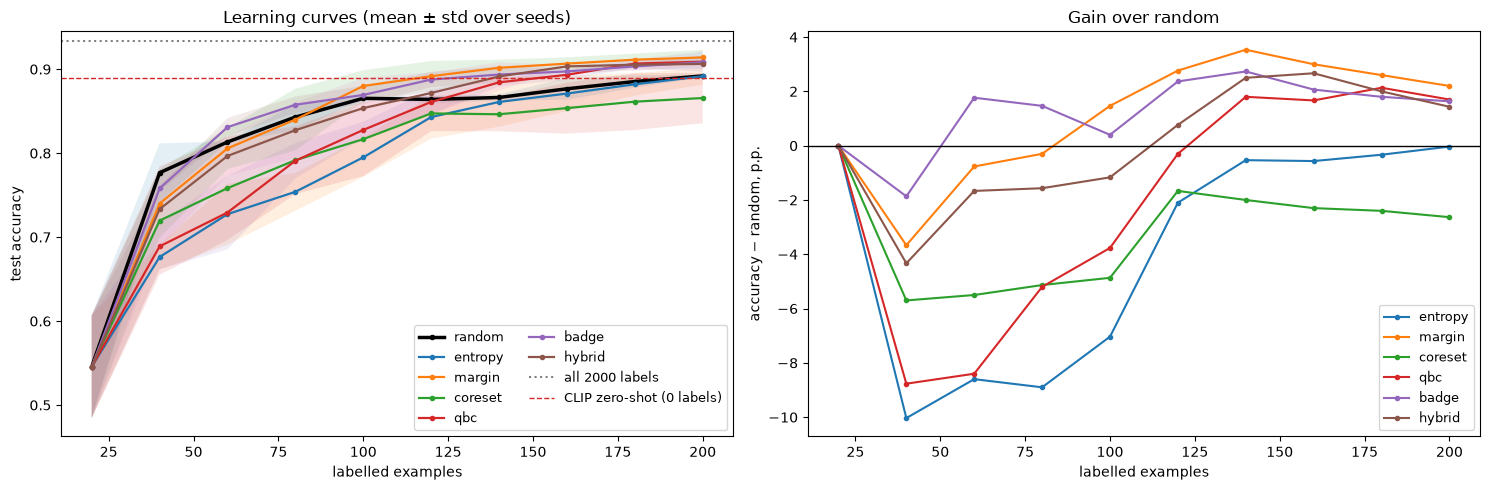

,strategy,AULC,acc_at_final,std_at_final,wins_vs_random
5,badge,0.8472,0.9083,0.0078,3
2,margin,0.8452,0.9140,0.0092,3
0,random,0.8344,0.8920,0.0017,0
6,hybrid,0.8343,0.9063,0.0040,3
4,qbc,0.8122,0.9090,0.0121,3
3,coreset,0.8001,0.8657,0.0300,0
1,entropy,0.7920,0.8917,0.0100,1


In [23]:
g = curves.groupby(["strategy", "n_labelled"]).test_acc.agg(["mean", "std"]).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for s_ in STRATEGIES:
    d = g[g.strategy == s_]
    axs[0].plot(d.n_labelled, d["mean"], "o-", ms=3, lw=2.5 if s_ == "random" else 1.6, label=s_,
                color="black" if s_ == "random" else None)
    axs[0].fill_between(d.n_labelled, d["mean"] - d["std"], d["mean"] + d["std"], alpha=0.12)
axs[0].axhline(full_acc, color="gray", ls=":", label=f"all {len(F_pool)} labels")
axs[0].axhline(clip_acc, color="tab:red", ls="--", lw=1, label="CLIP zero-shot (0 labels)")
axs[0].set_xlabel("labelled examples"); axs[0].set_ylabel("test accuracy"); axs[0].set_title("Learning curves (mean ± std over seeds)")
axs[0].legend(fontsize=9, ncol=2)
base_r = g[g.strategy == "random"].set_index("n_labelled")["mean"]
for s_ in STRATEGIES[1:]:
    d = g[g.strategy == s_].set_index("n_labelled")["mean"]
    axs[1].plot(d.index, 100 * (d - base_r), "o-", ms=3, label=s_)
axs[1].axhline(0, color="black", lw=1); axs[1].set_xlabel("labelled examples"); axs[1].set_ylabel("accuracy − random, p.p.")
axs[1].set_title("Gain over random"); axs[1].legend(fontsize=9); plt.tight_layout(); plt.show()

def aulc(d):
    x, yv = d.n_labelled.values, d["mean"].values
    return float(np.sum((x[1:] - x[:-1]) * (yv[1:] + yv[:-1]) / 2) / (x[-1] - x[0]))

last = curves[curves.n_labelled == curves.n_labelled.max()]
tab = pd.DataFrame([dict(strategy=s_, AULC=aulc(g[g.strategy == s_]),
                         acc_at_final=last[last.strategy == s_].test_acc.mean(),
                         std_at_final=last[last.strategy == s_].test_acc.std(),
                         wins_vs_random=int(np.sum(last[last.strategy == s_].test_acc.values > last[last.strategy == "random"].test_acc.values)))
                    for s_ in STRATEGIES]).sort_values("AULC", ascending=False)
for _, r in tab.iterrows():
    record("7 active learning", f"AULC {r.strategy}", float(r.AULC))
tab.round(4)

Результаты (CPU-режим: пул 2000, 3 сида, 20 → 200 меток):

- По площади под кривой первые BADGE (0.847) и margin (0.845), затем random и hybrid (0.834), QBC (0.812), core-set (0.800) и entropy (0.792). К 200 меткам margin (91.4 %), QBC, BADGE и hybrid (около 90.6–90.9 %) опережают random (89.2 %) на 1.4–2.2 п. п.; entropy равна random, core-set отстаёт (86.6 %).
- При малом числе меток (40–100) энтропия и QBC проигрывают случайной выборке до 8–10 п. п.: модель ещё плохая, а её «неуверенные» объекты нерепрезентативны. Это иллюстрация проблемы cold start и тезиса TypiClust: при малом бюджете полезны типичные объекты, при большом — трудные.
- Core-set на нормированных признаках CLIP выбирает «дальние» объекты, которые часто нетипичны, и проигрывает на всём диапазоне.
- Три сида и стандартное отклонение около 1 п. п. означают, что различия между лучшими стратегиями (BADGE, margin, hybrid) статистически неразличимы; уверенно можно сказать только, что margin и BADGE не хуже случайной выборки, а entropy и core-set в этой постановке хуже. Это согласуется с выводами [Munjal et al.](https://arxiv.org/abs/2002.09564).
- Красная линия — CLIP zero-shot без единой метки (88.95 %). Линейной голове со случайной выборкой нужно почти 200 меток, чтобы её превзойти. С foundation-моделями zero-shot — это базовая линия, которую обязан побить любой план разметки.

### 7.1. Смещение выборки: какие классы выбирает стратегия

Активная выборка по построению не случайна. Модель, обученная на такой выборке, видит искажённое распределение классов, а оценка качества на ней же была бы смещена — поэтому тест всегда отдельный и случайный.

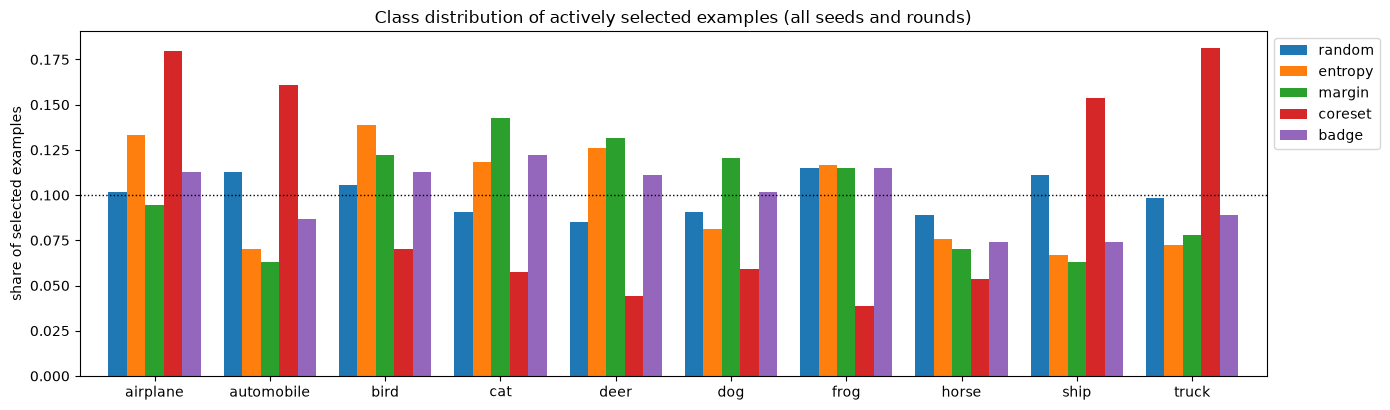

отклонение от равномерного (полусумма |доля − 0.1|): {'random': 0.046, 'entropy': 0.133, 'margin': 0.131, 'coreset': 0.276, 'qbc': 0.109, 'badge': 0.076, 'hybrid': 0.093}


In [24]:
hist = pd.DataFrame({s_: pd.Series(Counter(picked[s_])).reindex(range(10), fill_value=0) for s_ in STRATEGIES})
hist.index = CLASSES; hist = hist / hist.sum()
ax = hist[["random", "entropy", "margin", "coreset", "badge"]].plot.bar(figsize=(14, 4.2), width=0.8)
ax.axhline(0.1, color="black", ls=":", lw=1); ax.set_ylabel("share of selected examples")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("Class distribution of actively selected examples (all seeds and rounds)"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("отклонение от равномерного (полусумма |доля − 0.1|):", (hist.sub(0.1).abs().sum() / 2).round(3).to_dict())

Случайная выборка близка к равномерной (отклонение 0.046 — шум выборки). Uncertainty-стратегии смещены к трудным, путаемым классам: margin выбирает больше кошек, оленей, собак и птиц и меньше кораблей и грузовиков (отклонение 0.131, у entropy 0.133). Core-set смещён сильнее всех (0.276), причём в другую сторону: самолёты, автомобили, корабли и грузовики (по 15–18 %), лягушек всего 4 %. Транспорт на разнообразных фонах занимает в пространстве признаков CLIP больший объём, и k-center тратит на него бюджет. BADGE (0.076) и hybrid (0.093) смещены умеренно — добавка разнообразия частично компенсирует перекос uncertainty-выбора.

### 7.2. Когда остановиться: stabilizing predictions

Эталона в реальном AL нет, поэтому точность на тесте во время разметки неизвестна. Критерий stabilizing predictions ([Bloodgood & Vijay-Shanker](https://arxiv.org/abs/1409.5165)) смотрит на неразмеченный stop set и считает κ между предсказаниями моделей соседних раундов: если модель перестала менять свои ответы, новые метки мало что дают. Порог в оригинальной работе — κ ≥ 0.99, здесь для иллюстрации показываем всю кривую.

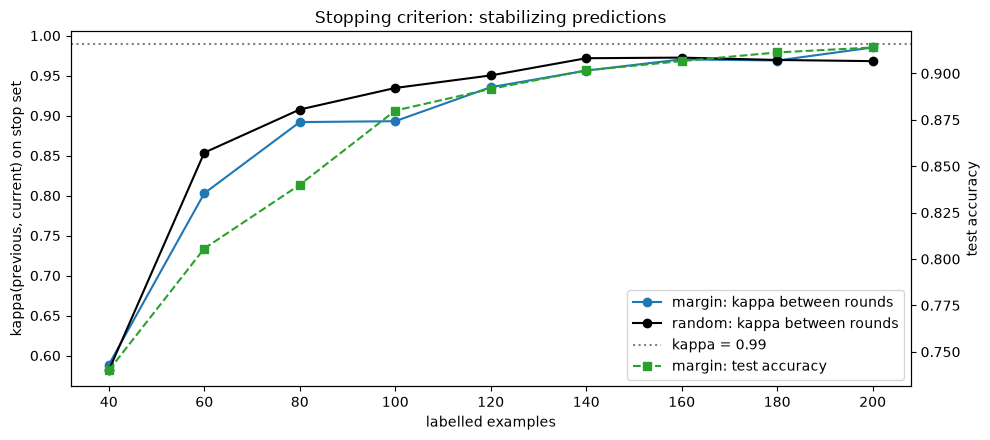

,strategy,n_labelled,stop_kappa,test_acc
40,margin,120,0.9355,0.8917
41,margin,140,0.9563,0.9017
42,margin,160,0.9703,0.9067
43,margin,180,0.9689,0.9113
44,margin,200,0.9852,0.9140


In [25]:
sk = curves.dropna().groupby(["strategy", "n_labelled"])[["stop_kappa", "test_acc"]].mean().reset_index()
fig, ax1 = plt.subplots(figsize=(10, 4.5))
for s_, c in [("margin", "tab:blue"), ("random", "black")]:
    d = sk[sk.strategy == s_]
    ax1.plot(d.n_labelled, d.stop_kappa, "o-", color=c, label=f"{s_}: kappa between rounds")
ax1.axhline(0.99, color="gray", ls=":", label="kappa = 0.99"); ax1.set_xlabel("labelled examples"); ax1.set_ylabel("kappa(previous, current) on stop set")
ax2 = ax1.twinx(); d = sk[sk.strategy == "margin"]
ax2.plot(d.n_labelled, d.test_acc, "s--", color="tab:green", label="margin: test accuracy"); ax2.set_ylabel("test accuracy")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax1.legend(h1 + h2, l1 + l2, loc="lower right")
plt.title("Stopping criterion: stabilizing predictions"); plt.tight_layout(); plt.show()
sk[sk.strategy == "margin"].round(4).tail(5)

κ между соседними раундами растёт с 0.59 (40 меток) до 0.985 (200 меток для margin), но порога 0.99 за 200 меток не достигает, и по критерию Bloodgood и Vijay-Shanker (среднее за 3 раунда выше 0.99) разметку следовало бы продолжать. Это согласуется с тем, что точность на тесте ещё растёт (89.2 → 91.4 % за последние 80 меток). Критерий удобен тем, что не требует меток: stop set — просто 500 неразмеченных объектов пула.

### 7.3. Cold start

Uncertainty-стратегиям нужна модель, а модели нужны метки: самый первый батч приходится выбирать без модели. Сравним при очень малых бюджетах (10, 20, 40 меток):

- random;
- k-means по признакам и самый «типичный» объект каждого кластера (идея [TypiClust](https://arxiv.org/abs/2202.02794)): типичность — величина, обратная среднему расстоянию до 20 ближайших соседей;
- zero-shot seed: для каждого класса берём объекты, в которых CLIP zero-shot уверен сильнее всего; человек только подтверждает или исправляет метку. Так foundation-модель решает проблему cold start, если классы можно описать текстом.

In [26]:
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
nn = NearestNeighbors(n_neighbors=21).fit(F_pool); dist_nn, _ = nn.kneighbors(F_pool)
typicality = 1 / (dist_nn[:, 1:].mean(1) + 1e-8)
cs = []
for budget in [10, 20, 40]:
    for seed in range(AL_SEEDS):
        rng = np.random.default_rng(seed)
        sel = {"random": rng.choice(len(F_pool), budget, replace=False)}
        km = KMeans(budget, n_init=3, random_state=seed).fit(F_pool)
        sel["typical (k-means)"] = np.array([np.where(km.labels_ == c)[0][np.argmax(typicality[km.labels_ == c])] for c in range(budget)])
        per = budget // 10
        sel["zero-shot seed"] = np.concatenate([np.where(clip_pred == c)[0][np.argsort(-P_clip[clip_pred == c, c])][:per] for c in range(10)])
        for name, idx in sel.items():
            m = fit_lr(F_pool[idx], y_pool[idx])
            cs.append(dict(budget=budget, method=name, seed=seed, test_acc=float((proba_full(m, F_test).argmax(1) == y_test).mean()),
                           classes_covered=len(np.unique(y_pool[idx]))))
cs = pd.DataFrame(cs)
cst = cs.groupby(["budget", "method"]).agg(test_acc=("test_acc", "mean"), std=("test_acc", "std"),
                                         classes_covered=("classes_covered", "mean")).round(4)
for (b_, mth), r in cst.iterrows():
    if b_ == 10:
        record("7 active learning", f"cold start 10 labels, {mth}", float(r.test_acc))
cst.unstack("method")

test_acc                                      std                    \
method   random typical (k-means) zero-shot seed  random typical (k-means)   
budget                                                                       
10       0.4063            0.6410          0.763  0.0772            0.0685   
20       0.5457            0.7300          0.796  0.0612            0.0304   
40       0.6830            0.7953          0.826  0.0877            0.0488   

                      classes_covered                                   
method zero-shot seed          random typical (k-means) zero-shot seed  
budget                                                                  
10                0.0          7.0000            9.3333           10.0  
20                0.0          8.6667           10.0000           10.0  
40                0.0          9.6667           10.0000           10.0

Холодный старт при бюджете 10 / 20 / 40 меток:

- случайная выборка: 40.6 / 54.6 / 68.3 %; при 10 метках в среднем покрыто только 7 классов из 10 — модель вообще не знает о трёх классах;
- типичные объекты k-means: 64.1 / 73.0 / 79.5 % и почти полное покрытие классов — выигрыш 10–24 п. п. над случайной выборкой;
- zero-shot seed: 76.3 / 79.6 / 82.6 %, все 10 классов с первой метки. Человек лишь подтверждает предложения CLIP, что дешевле разметки с нуля.

Но и 40 отобранных меток (82.6 %) хуже, чем zero-shot CLIP без меток (88.95 %): линейная голова, обученная с нуля на 40 примерах, «забывает» знание текстового энкодера. На практике их совмещают — инициализируют голову текстовыми эмбеддингами классов или используют zero-shot вероятности как априорное распределение и дообучают на отобранных метках.

## 8. Human-in-the-loop: маршрутизация по уверенности

Политика маршрутизации (теория, раздел 12): метку CLIP принимаем автоматически, если калиброванная уверенность не ниже порога $\tau$ и ответ устойчив к отражению изображения; иначе объект уходит человеку. 200 объектов калибровочного набора человек уже проверил в разделе 6.3, их метки берём эталонными — повторно платить за них не нужно.

Для каждого порога считаем долю объектов на ручной проверке (стоимость) и долю ошибок в итоговом датасете (качество). Затем обучаем downstream-модель на итоговых метках.

In [27]:
tta_ok = Z_flip.argmax(1) == clip_pred
already = np.zeros(len(pool_df), bool); already[cal_idx] = True
hitl = []
for tau in [0.0, 0.5, 0.8, 0.9, 0.95, 0.97, 0.99, 1.01]:
    review = already | ~((conf_cal >= tau) & tta_ok)
    final = np.where(review, y_pool, clip_pred)
    hitl.append(dict(tau=tau, review_share=review.mean(), new_reviews=int((review & ~already).sum()),
                     corrections=int((review & ~correct).sum()), final_error=float((final != y_pool).mean()),
                     errors_left=int((final != y_pool).sum())))
hitl = pd.DataFrame(hitl)
hitl["corrections_per_100_reviews"] = 100 * hitl.corrections / hitl.review_share.mul(len(pool_df)).clip(lower=1)
TARGET_ERR = 0.02
TAU = float(hitl[hitl.final_error <= TARGET_ERR].tau.min())
print(f"минимальный порог, при котором ошибок в датасете ≤ {TARGET_ERR:.0%}: tau = {TAU}")
hitl.round(4)

минимальный порог, при котором ошибок в датасете ≤ 2%: tau = 0.9


,tau,review_share,new_reviews,corrections,final_error,errors_left,corrections_per_100_reviews
0,0.00,0.1560,112,84,0.0685,137,26.9231
1,0.50,0.1895,179,120,0.0505,101,31.6623
2,0.80,0.2900,380,174,0.0235,47,30.0000
3,0.90,0.3605,521,190,0.0155,31,26.3523
4,0.95,0.4285,657,202,0.0095,19,23.5706
5,0.97,0.4755,751,206,0.0075,15,21.6614
6,0.99,0.6200,1040,217,0.0020,4,17.5000
7,1.01,1.0000,1800,221,0.0000,0,11.0500


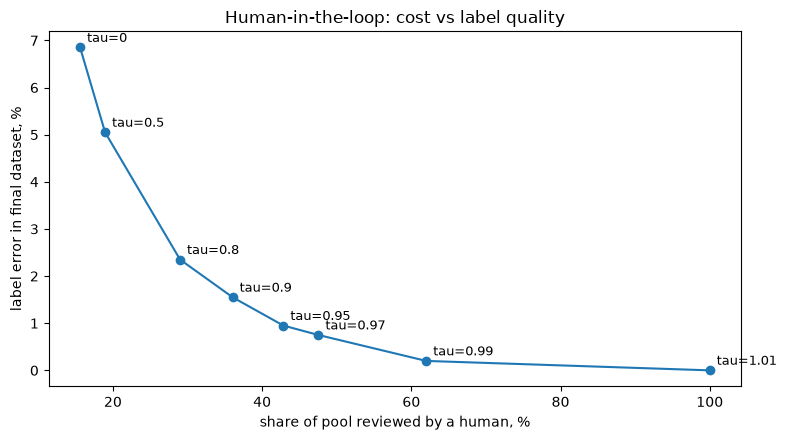

,labels,human_reviews,label_error,test_acc
0,v1: CLIP auto labels,0,0.1105,0.895
1,"v2: HITL, tau=0.9",721,0.0155,0.928
2,ground truth (review everything),2000,0.0000,0.933


In [28]:
review = already | ~((conf_cal >= TAU) & tta_ok)
labels_v1 = clip_pred.copy()                       # версия 1: только авторазметка
labels_v2 = np.where(review, y_pool, clip_pred)    # версия 2: после проверки человеком
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(100 * hitl.review_share, 100 * hitl.final_error, "o-")
for _, r in hitl.iterrows():
    ax.annotate(f"tau={r.tau:g}", (100 * r.review_share, 100 * r.final_error), textcoords="offset points", xytext=(5, 4), fontsize=9)
ax.set_xlabel("share of pool reviewed by a human, %"); ax.set_ylabel("label error in final dataset, %")
ax.set_title("Human-in-the-loop: cost vs label quality"); plt.tight_layout(); plt.show()

hd = pd.DataFrame([dict(labels="v1: CLIP auto labels", human_reviews=0, label_error=float((labels_v1 != y_pool).mean()), test_acc=downstream(F_pool, labels_v1)),
                   dict(labels=f"v2: HITL, tau={TAU:g}", human_reviews=int(review.sum()), label_error=float((labels_v2 != y_pool).mean()), test_acc=downstream(F_pool, labels_v2)),
                   dict(labels="ground truth (review everything)", human_reviews=len(y_pool), label_error=0.0, test_acc=downstream(F_pool, y_pool))])
record("8 HITL", f"review share at tau={TAU:g}", float(review.mean()))
record("8 HITL", "final label error v2", float((labels_v2 != y_pool).mean()))
hd.round(4)

Компромисс стоимость — качество:

- Даже при $\tau = 0$ проверяется 15.6 % пула: 200 объектов калибровочного набора и 112 объектов, где ответ CLIP изменился при отражении изображения. Уже это снижает долю ошибок с 11.05 % до 6.85 %.
- Минимальный порог, при котором ошибок в датасете не больше 2 %, — $\tau = 0.9$: человек проверяет 36 % пула (721 объект), исправляет 190 меток, и в датасете остаётся 1.55 % ошибок. При $\tau = 0.99$ — 62 % проверок и 0.2 % ошибок.
- Эффективность проверки падает с ростом её объёма: 27–32 исправления на 100 проверок при малых порогах и 11 на 100 при полной проверке (где исправляются все 11 % ошибок, а проверяются и все верные метки).
- Downstream-модель: 89.5 % на автоматических метках, 92.8 % после HITL и 93.3 % на эталоне. Проверка 36 % пула закрыла около 87 % разрыва между автоматическими и эталонными метками.

Эти числа оптимистичны: oracle не ошибается и не поддаётся влиянию подсказки (раздел 12.2 теории).

## 9. Provenance и версионирование датасета

Каждая метка должна отвечать на вопросы: кто или что её поставил, когда, какой версией модели, с каким промптом и параметрами, по какой версии схемы, и из какой предыдущей метки она получена. Минимальная модель — W3C PROV ([PROV-DM](https://www.w3.org/TR/prov-dm/)): сущности (entity: изображение, метка), действия (activity: прогон авторазметки, проверка человеком) и агенты (agent: модель, разметчик), связанные отношениями `used`, `wasGeneratedBy`, `wasAssociatedWith`, `wasDerivedFrom`.

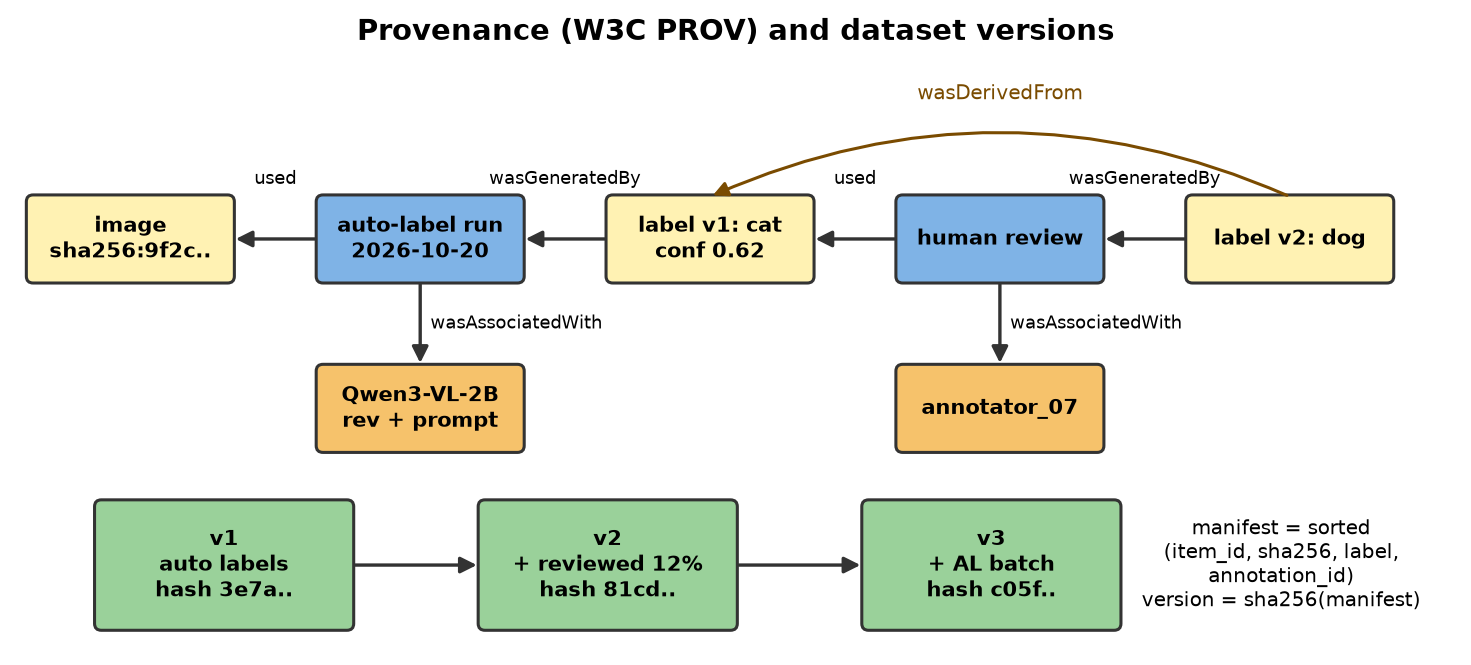

Журнал аннотаций хранится в формате JSONL «только на добавление» (append-only): метки не перезаписываются, новая метка ссылается на ту, из которой получена. Версия датасета — это детерминированный манифест (отсортированные тройки идентификатор объекта, хеш изображения, идентификатор аннотации), а идентификатор версии — SHA-256 манифеста.

In [29]:
CLIP_REVISION = Path(hf_hub_download(CLIP_ID, "config.json")).parent.name
NOW = lambda: datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")
TEMPLATES_SHA = hashlib.sha256(json.dumps(TEMPLATES).encode()).hexdigest()
RUN_CLIP = dict(activity_id="run:clip-zeroshot-001", type="auto-label", started=NOW(), code="lecture07.ipynb, section 5.2",
                params=dict(templates_sha256=TEMPLATES_SHA, temperature=round(T_STAR, 4), tta="hflip"), libraries=VERSIONS)
RUN_VLM = dict(activity_id="run:vlm-constrained-001", type="auto-label", started=NOW(), code="lecture07.ipynb, section 5.1",
               params=dict(prompt_sha256=PROMPT_SHA["schema"], prefill=PREFILL, decoding="greedy, masked to label tokens",
                           image_side=IMG_SIDE, dtype=str(COMPUTE_DTYPE)), libraries=VERSIONS)
RUN_REVIEW = dict(activity_id="run:review-001", type="human-review", started=NOW(),
                  params=dict(router=f"p_cal >= {TAU:g} and hflip agrees, else review"))

def ann_id(*parts):
    return "ann:" + hashlib.sha256("|".join(map(str, parts)).encode()).hexdigest()[:16]

log = []
for i, r in pool_df.iterrows():
    a1 = ann_id(r.item_id, RUN_CLIP["activity_id"], CLASSES[labels_v1[i]])
    log.append(dict(annotation_id=a1, item_id=r.item_id, image_sha256=r.sha256, label=CLASSES[labels_v1[i]],
                    confidence=round(float(conf_cal[i]), 4), schema_version=SCHEMA_VERSION,
                    agent=f"model:{CLIP_ID}@{CLIP_REVISION[:12]}", activity=RUN_CLIP["activity_id"], derived_from=None, created_at=NOW()))
    if review[i]:
        a2 = ann_id(r.item_id, RUN_REVIEW["activity_id"], CLASSES[labels_v2[i]])
        log.append(dict(annotation_id=a2, item_id=r.item_id, image_sha256=r.sha256, label=CLASSES[labels_v2[i]],
                        decision="accept" if labels_v2[i] == labels_v1[i] else "correct", schema_version=SCHEMA_VERSION,
                        agent="human:reviewer_01 (simulated oracle)", activity=RUN_REVIEW["activity_id"], derived_from=a1, created_at=NOW()))
for _, r in vlm_lab.iterrows():
    log.append(dict(annotation_id=ann_id(r.item_id, RUN_VLM["activity_id"], r.vlm_label), item_id=r.item_id,
                    image_sha256=pool_df.sha256.iloc[pos[r.item_id]], label=r.vlm_label, confidence=round(r.p_max, 4),
                    view_agree=round(r.view_agree, 3), schema_version=SCHEMA_VERSION, agent=f"model:{MODEL_ID}@{MODEL_REVISION[:12]}",
                    activity=RUN_VLM["activity_id"], derived_from=None, created_at=NOW()))
with open(ART / "annotations.jsonl", "w") as f:
    for rec in log:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")
(ART / "activities.json").write_text(json.dumps([RUN_CLIP, RUN_VLM, RUN_REVIEW], indent=2, default=str))
print(len(log), "записей в annotations.jsonl; пример исправления:")
print(json.dumps(next(x for x in log if x.get("decision") == "correct"), indent=1, ensure_ascii=False))

2741 записей в annotations.jsonl; пример исправления:
{
 "annotation_id": "ann:fe8b12f1f6c78e0f",
 "item_id": "cifar10/test/00085",
 "image_sha256": "c5cce4446b5a380ce29c3efdf5c2f43c4ac26529b3c4b7fe4558ecbb6f4f44d7",
 "label": "dog",
 "decision": "correct",
 "schema_version": "cifar_image_label/1.0.0",
 "agent": "human:reviewer_01 (simulated oracle)",
 "activity": "run:review-001",
 "derived_from": "ann:f985494732dc510b",
 "created_at": "2026-10-20T17:21:05+00:00"
}


In [30]:
def make_version(labels, ann_ids, parent=None, note=""):
    rows = sorted(zip(pool_df.item_id, pool_df.sha256, [CLASSES[k] for k in labels], ann_ids))
    body = "\n".join(",".join(r) for r in rows).encode()
    vid = hashlib.sha256(body).hexdigest()
    return dict(version=vid, parent=parent, created_at=NOW(), n_items=len(rows), schema_version=SCHEMA_VERSION,
                data_revision=f"{DATA_REPO}@{DATA_REVISION[:12]}", note=note,
                label_counts=dict(Counter(CLASSES[k] for k in labels))), rows

ids_v1 = [ann_id(r.item_id, RUN_CLIP["activity_id"], CLASSES[labels_v1[i]]) for i, r in pool_df.iterrows()]
ids_v2 = [ann_id(r.item_id, RUN_REVIEW["activity_id"], CLASSES[labels_v2[i]]) if review[i] else ids_v1[i] for i, r in pool_df.iterrows()]
V1, rows1 = make_version(labels_v1, ids_v1, note="CLIP zero-shot auto labels")
V2, rows2 = make_version(labels_v2, ids_v2, parent=V1["version"], note=f"human review of {int(review.sum())} items routed by tau={TAU:g}")
for V, rows_, name in [(V1, rows1, "v1"), (V2, rows2, "v2")]:
    (ART / f"manifest_{name}.csv").write_text("item_id,sha256,label,annotation_id\n" + "\n".join(",".join(r) for r in rows_))
    (ART / f"version_{name}.json").write_text(json.dumps(V, indent=2))
# воспроизводимость: тот же манифест → тот же хеш
assert make_version(labels_v1, ids_v1)[0]["version"] == V1["version"]
changed = labels_v1 != labels_v2
diff = pd.Series([f"{CLASSES[a]} -> {CLASSES[b]}" for a, b in zip(labels_v1[changed], labels_v2[changed])]).value_counts()
print("v1:", V1["version"][:16], "→ v2:", V2["version"][:16], f"| изменено меток: {changed.sum()}")
changelog = (f"# Changelog\n\n## v2 {V2['version'][:12]} (parent {V1['version'][:12]})\n\n- {V2['note']}\n"
             f"- labels changed: {int(changed.sum())}; most frequent corrections: " +
             ", ".join(f"{k} ({v})" for k, v in diff.head(5).items()) + "\n")
(ART / "CHANGELOG.md").write_text(changelog)
print(changelog)
diff.head(8).to_frame("count")

v1: 61d8f748de321993 → v2: cfbe4503d9a41338 | изменено меток: 190
# Changelog

## v2 cfbe4503d9a4 (parent 61d8f748de32)

- human review of 721 items routed by tau=0.9
- labels changed: 190; most frequent corrections: horse -> deer (16), dog -> cat (16), cat -> dog (13), cat -> frog (13), bird -> frog (9)



,count
horse -> deer,16
dog -> cat,16
cat -> dog,13
cat -> frog,13
bird -> frog,9
ship -> airplane,8
automobile -> truck,8
truck -> automobile,8


Документация датасета: короткий datasheet ([Gebru et al.](https://arxiv.org/abs/1803.09010)) генерируется из тех же артефактов, поэтому не расходится с данными. Ниже — фрагмент; в реальном проекте разделы о мотивации, составе, сборе, предобработке, использовании и сопровождении заполняет команда, а таблицы и числа подставляет код. Рядом — PROV-описание одной исправленной метки.

In [31]:
err_v2 = float((labels_v2 != y_pool).mean())
datasheet = f"""# Datasheet: CIFAR-10 pool, auto-labelled (lecture 7 demo)

- Version: {V2['version'][:16]} (parent {V1['version'][:16]}), schema {SCHEMA_VERSION} (sha256 {SCHEMA_SHA[:12]})
- Source images: {DATA_REPO} @ {DATA_REVISION[:12]}, file {DATA_FILE}; {len(pool_df)} items, stratified 10 classes
- Labelling: CLIP {CLIP_ID} zero-shot ({len(TEMPLATES)} templates, temperature {T_STAR:.2f}); human review of {int(review.sum())} items ({review.mean():.1%}) routed by calibrated confidence >= {TAU:g} and hflip agreement
- Estimated label error after review: {err_v2:.2%} (here measured exactly against ground truth; in practice estimate it with a stratified audit, section 6.4)
- Known issues: confusions {', '.join(diff.head(3).index)}; reviewer is a simulated oracle; CIFAR images are 32x32
- Intended use: teaching; not for benchmarking (labels derived from CIFAR-10 test split)
"""
(ART / "datasheet.md").write_text(datasheet); print(datasheet)
i0 = int(np.where(changed)[0][0]); r0 = pool_df.iloc[i0]
prov = {"entity": {f"img:{r0.sha256[:12]}": {"item_id": r0.item_id},
                   ids_v1[i0]: {"label": CLASSES[labels_v1[i0]], "confidence": round(float(conf_cal[i0]), 3)},
                   ids_v2[i0]: {"label": CLASSES[labels_v2[i0]]}},
        "activity": {RUN_CLIP["activity_id"]: {}, RUN_REVIEW["activity_id"]: {}},
        "agent": {f"model:{CLIP_ID}@{CLIP_REVISION[:12]}": {}, "human:reviewer_01": {}},
        "used": [[RUN_CLIP["activity_id"], f"img:{r0.sha256[:12]}"], [RUN_REVIEW["activity_id"], ids_v1[i0]]],
        "wasGeneratedBy": [[ids_v1[i0], RUN_CLIP["activity_id"]], [ids_v2[i0], RUN_REVIEW["activity_id"]]],
        "wasAssociatedWith": [[RUN_CLIP["activity_id"], f"model:{CLIP_ID}@{CLIP_REVISION[:12]}"], [RUN_REVIEW["activity_id"], "human:reviewer_01"]],
        "wasDerivedFrom": [[ids_v2[i0], ids_v1[i0]]]}
(ART / "prov_example.json").write_text(json.dumps(prov, indent=2)); print(json.dumps(prov, indent=1)[:1200])

# Datasheet: CIFAR-10 pool, auto-labelled (lecture 7 demo)

- Version: cfbe4503d9a41338 (parent 61d8f748de321993), schema cifar_image_label/1.0.0 (sha256 c8736a326507)
- Source images: uoft-cs/cifar10 @ 0b2714987fa4, file plain_text/test-00000-of-00001.parquet; 2000 items, stratified 10 classes
- Labelling: CLIP openai/clip-vit-base-patch32 zero-shot (6 templates, temperature 0.77); human review of 721 items (36.0%) routed by calibrated confidence >= 0.9 and hflip agreement
- Estimated label error after review: 1.55% (here measured exactly against ground truth; in practice estimate it with a stratified audit, section 6.4)
- Known issues: confusions horse -> deer, dog -> cat, cat -> dog; reviewer is a simulated oracle; CIFAR images are 32x32
- Intended use: teaching; not for benchmarking (labels derived from CIFAR-10 test split)

{
 "entity": {
  "img:c5cce4446b5a": {
   "item_id": "cifar10/test/00085"
  },
  "ann:f985494732dc510b": {
   "label": "horse",
   "confidence": 0.642
  },
  "

### 9.1. Утечки между разбиениями: точные и почти-дубликаты

Хеши ловят только побайтовые копии. Почти-дубликаты (другое сжатие, сдвиг, кадрирование) ищем по косинусной близости эмбеддингов CLIP между пулом и тестом. Порог подбирают, глядя на найденные пары; ниже показаны самые близкие пары.

общих SHA-256 между пулом и тестом: 0
пар пул–тест с косинусом > 0.95: 92
пар пул–тест с косинусом > 0.97: 3
пар пул–тест с косинусом > 0.98: 0


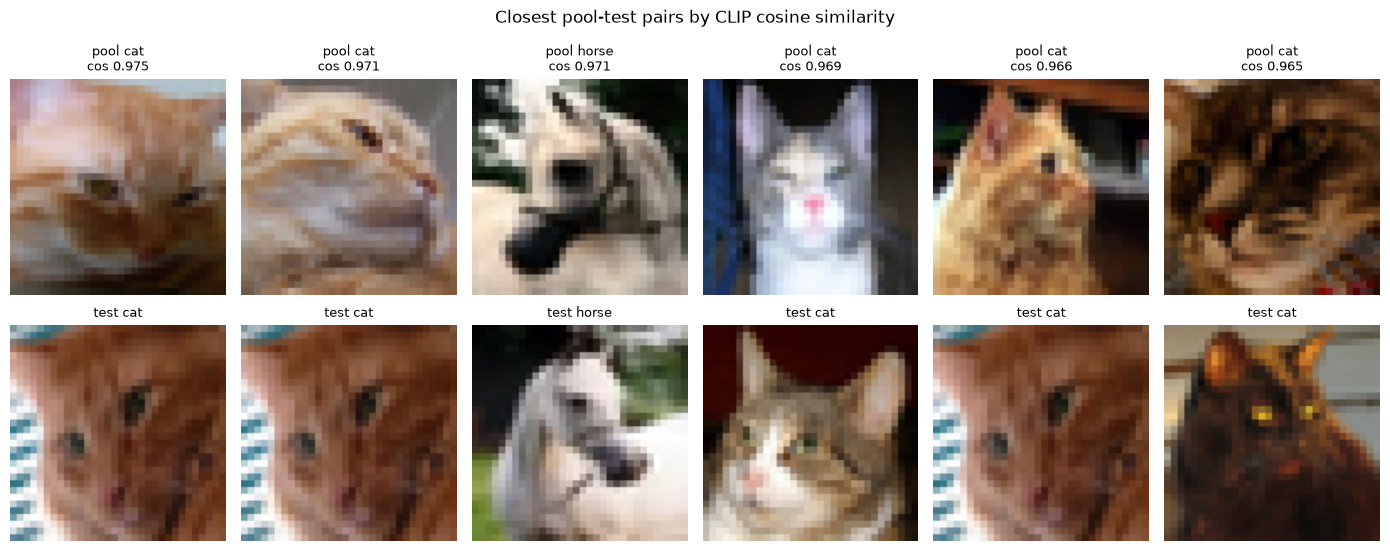

In [32]:
print("общих SHA-256 между пулом и тестом:", len(set(pool_df.sha256) & set(test_df.sha256)))
S_pt = F_pool @ F_test.T
best_test = S_pt.argmax(1); best_sim = S_pt.max(1)
for thr in [0.95, 0.97, 0.98]:
    print(f"пар пул–тест с косинусом > {thr}: {(best_sim > thr).sum()}")
top = np.argsort(-best_sim)[:6]
fig, axs = plt.subplots(2, 6, figsize=(14, 5.8))
for j, i in enumerate(top):
    axs[0, j].imshow(to_pil(pool_df.iloc[i]).resize((96, 96), Image.NEAREST)); axs[0, j].set_title(f"pool {pool_df.truth[i]}\ncos {best_sim[i]:.3f}", fontsize=9)
    axs[1, j].imshow(to_pil(test_df.iloc[best_test[i]]).resize((96, 96), Image.NEAREST)); axs[1, j].set_title(f"test {test_df.truth[best_test[i]]}", fontsize=9)
    axs[0, j].axis("off"); axs[1, j].axis("off")
plt.suptitle("Closest pool-test pairs by CLIP cosine similarity", fontsize=12); plt.tight_layout(); plt.show()
record("9 provenance", "pool-test pairs with cosine > 0.97", int((best_sim > 0.97).sum()))

Общих хешей нет, а пар с косинусом выше 0.97 — три, выше 0.98 — ни одной. Глядя на самые близкие пары, видно, что это не дубликаты, а разные фотографии похожих объектов (одна тестовая кошка «близка» сразу к нескольким кошкам пула). Эмбеддинги CLIP семантические: они хорошо находят «то же содержание», но порог для дубликатов нужно подбирать по просмотру пар, а для поиска именно копий (пережатие, кадрирование) лучше подходят перцептивные хеши или признаки, чувствительные к пикселям, например DINOv2. В нашем пуле и тесте (обе части взяты из тестового набора CIFAR-10) утечек не найдено.

## 10. Итоги практики

In [33]:
summary_df = pd.DataFrame(RESULTS)
summary_df["value"] = summary_df.value.map(lambda v: round(v, 4) if isinstance(v, float) else v)
(ART / "results.json").write_text(summary_df.to_json(orient="records", force_ascii=False, indent=1))
print("артефакты:", sorted(p.name for p in ART.iterdir()))
summary_df

артефакты: ['CHANGELOG.md', 'activities.json', 'annotations.jsonl', 'datasheet.md', 'images_manifest.csv', 'manifest_v1.csv', 'manifest_v2.csv', 'prov_example.json', 'results.json', 'schema.json', 'version_v1.json', 'version_v2.json']


,section,metric,value
0,4 structured generation,"valid rate, mode A",0.0000
1,4 structured generation,"valid rate, mode A+retry",1.0000
2,4 structured generation,"valid rate, mode B",1.0000
3,4 structured generation,"valid rate, mode C",1.0000
4,4 structured generation,"valid rate, mode D",1.0000
5,5 auto-labelling,VLM accuracy (view 1),0.9000
6,5 auto-labelling,CLIP zero-shot accuracy (pool),0.8895
7,6 QC,Cohen kappa CLIP vs GT (pool),0.8772
8,6 QC,AUROC p_max (CLIP pool),0.8873
9,6 QC,ECE before temperature scaling,0.0467


Главные выводы практики:

1. «Ответь в JSON» не даёт ответа по схеме (0 % валидных); схема в промпте даёт 100 % на простых изображениях; повтор с обратной связью исправляет формат за одну итерацию; constrained decoding гарантирует валидность и даёт вероятность класса за один проход.
2. Прокси уверенности ($p_{\max}$, margin) хорошо ранжируют ошибки CLIP (AUROC около 0.89); после temperature scaling они ещё и калиброваны (ECE 0.020), что позволяет выбрать порог по кривой risk–coverage.
3. Согласие моделей и self-consistency не ловят общих систематических ошибок (`automobile → truck`); confident learning не находит ошибки, порождённые моделью в том же пространстве признаков. Нужны независимые источники проверки.
4. Стратифицированный аудит с размещением Неймана при том же бюджете даёт оценку доли ошибок с дисперсией в 1.7 раза меньше, чем простая случайная выборка; для редких ошибок нужны интервалы Уилсона.
5. Active learning: margin, BADGE и hybrid при 200 метках лучше случайной выборки на 1.4–2.2 п. п. (на грани статистической различимости при 3 сидах), энтропия и core-set — не лучше; при холодном старте выигрывают типичные объекты и zero-shot кандидаты, а zero-shot CLIP без меток — сильная базовая линия.
6. HITL с порогом по калиброванной уверенности: проверка 36 % пула снижает долю ошибок с 11 % до 1.55 % и закрывает около 87 % разрыва downstream-качества.
7. Каждая метка записана в append-only журнал с моделью, ревизией, промптом и агентом; версии датасета идентифицируются хешем манифеста, а datasheet и changelog генерируются из тех же артефактов.

Чтобы получить информативные числа для VLM, запустите блокнот на GPU: `FAST_DEV_RUN` отключится автоматически, и VLM разметит 300 изображений.

# Контрольные вопросы

1. Чем класс-зависимый шум меток отличается от instance-dependent? Какой из них предполагает confident learning и почему автоматическая разметка моделью даёт в основном второй?
2. Зачем в таксономии нужен класс `other`? Что произойдёт с оценкой качества авторазметки, если его убрать?
3. Какие ограничения можно выразить в JSON Schema, а какие — нет? Приведите две семантические проверки для разметки рамок.
4. Объясните, как работает маскирование логитов в constrained decoding. Почему маска не делает ответ правильным и что означает большая доля вероятности, ушедшая на запрещённые токены?
5. Вероятность валидного ответа за попытку 0.7. Сколько попыток нужно, чтобы доля невалидных ответов была ниже 1 %, если попытки независимы? Почему на практике независимость нарушается?
6. Чем отличаются прокси уверенности по ранжированию и по калибровке? Какие метрики измеряют каждое свойство?
7. Почему self-consistency не защищает от систематических ошибок модели? Что защищает?
8. Что меняет и чего не меняет temperature scaling?
9. Есть 3 страты с $N_h = 6000, 3000, 1000$ и ожидаемой долей ошибок 1 %, 5 %, 30 %. Разместите 150 проверок по Нейману и пропорционально.
10. Два разметчика совпали на 95 % объектов, а κ = 0.3. Как такое возможно?
11. Когда стоит выбрать Krippendorff α вместо Fleiss κ?
12. Запишите acquisition-функции least confidence, margin, entropy и BALD. Чем BALD отличается от энтропии?
13. Почему жадный k-center чувствителен к выбросам? Как гибридные стратегии решают проблему избыточности батча?
14. Почему при малом бюджете лучше выбирать типичные объекты, а при большом — трудные?
15. Опишите критерий остановки stabilizing predictions. Почему stop set не обязан быть размеченным?
16. Какие эффекты влияния предразметки на людей известны и как их снизить?
17. Какие поля должна содержать запись в журнале аннотаций, чтобы восстановить provenance по модели W3C PROV?
18. Как определить идентификатор версии датасета так, чтобы одинаковые данные давали одинаковый идентификатор?

# Задания

1. (Схема) Расширьте `ImageLabel` полем `attributes` (массив из закрытого списка: `blurry`, `occluded`, `multiple_objects`) и семантической проверкой: если `uncertain = true`, то `confidence ≤ 0.6`. Добавьте тестовые случаи.
2. (Structured generation) Сравните режимы B и D при порядке полей «caption перед class_name». Меняется ли точность? Объясните результат с учётом раздела 3.3.
3. (Повтор) Измерьте вероятность успеха каждой следующей попытки в режиме C на 50 изображениях. Подтверждается ли формула $(1 - p)^K$?
4. (QC) Добавьте третью модель (например, SigLIP) и сравните AUROC прокси «согласие двух моделей» и «согласие трёх моделей».
5. (Аудит) Реализуйте интервал Уилсона для стратифицированной оценки и сравните покрытие с нормальным интервалом при бюджете 50.
6. (Active learning) Повторите эксперимент раздела 7 с несбалансированным пулом (один класс в 10 раз реже остальных). Какая стратегия лучше находит редкий класс?
7. (HITL) Добавьте в симуляцию человека, который с вероятностью 0.7 принимает неверную предложенную метку без исправления (automation bias). Как меняется оптимальный порог $\tau$?
8. (Provenance) Напишите функцию, которая по `annotations.jsonl` восстанавливает любую версию датасета и проверяет её хеш.

Лабораторные работы курса: lab 07 «Разметка с помощью VLM» и lab 08 «Active learning» в [репозитории курса](https://github.com/fmi-ml-courses/computer_vision_2026_students).

# Источники

Ошибки разметки и данные

1. Northcutt C. G., Athalye A., Mueller J. Pervasive Label Errors in Test Sets Destabilize Machine Learning Benchmarks. NeurIPS Datasets and Benchmarks, 2021. https://arxiv.org/abs/2103.14749
2. Northcutt C. G., Jiang L., Chuang I. L. Confident Learning: Estimating Uncertainty in Dataset Labels. JAIR, 2021. https://arxiv.org/abs/1911.00068 ; библиотека cleanlab: https://github.com/cleanlab/cleanlab
3. Wei J. et al. Learning with Noisy Labels Revisited: A Study Using Real-World Human Annotations (CIFAR-10N). ICLR, 2022. https://arxiv.org/abs/2110.12088
4. Barz B., Denzler J. Do We Train on Test Data? Purging CIFAR of Near-Duplicates. Journal of Imaging, 2020. https://arxiv.org/abs/1902.00423
5. Krizhevsky A. The CIFAR-10 dataset. https://www.cs.toronto.edu/~kriz/cifar.html ; копия на Hugging Face: https://huggingface.co/datasets/uoft-cs/cifar10

Автоматическая разметка

6. Kirillov A. et al. Segment Anything. ICCV, 2023. https://arxiv.org/abs/2304.02643
7. Ratner A. et al. Snorkel: Rapid Training Data Creation with Weak Supervision. VLDB, 2018. https://arxiv.org/abs/1711.10160
8. Wang S. et al. Want To Reduce Labeling Cost? GPT-3 Can Help. Findings of EMNLP, 2021. https://arxiv.org/abs/2108.13487
9. Gilardi F., Alizadeh M., Kubli M. ChatGPT Outperforms Crowd-Workers for Text-Annotation Tasks. PNAS, 2023. https://arxiv.org/abs/2303.15056
10. CVAT. https://github.com/cvat-ai/cvat ; Label Studio. https://labelstud.io/

Схемы и structured generation

11. JSON Schema: object. https://json-schema.org/understanding-json-schema/reference/object
12. Pydantic. https://docs.pydantic.dev/latest/
13. Willard B. T., Louf R. Efficient Guided Generation for Large Language Models (Outlines). 2023. https://arxiv.org/abs/2307.09702 ; https://github.com/dottxt-ai/outlines
14. Dong Y. et al. XGrammar: Flexible and Efficient Structured Generation Engine for Large Language Models. 2024. https://arxiv.org/abs/2411.15100 ; https://github.com/mlc-ai/xgrammar
15. llama.cpp: GBNF grammars. https://github.com/ggml-org/llama.cpp/blob/master/grammars/README.md
16. Hugging Face Transformers: Generation (`prefix_allowed_tokens_fn`). https://huggingface.co/docs/transformers/main_classes/text_generation
17. Tam Z. R. et al. Let Me Speak Freely? A Study on the Impact of Format Restrictions on Performance of Large Language Models. 2024. https://arxiv.org/abs/2408.02442

Уверенность, калибровка, согласие

18. Wang X. et al. Self-Consistency Improves Chain of Thought Reasoning in Language Models. ICLR, 2023. https://arxiv.org/abs/2203.11171
19. Xiong M. et al. Can LLMs Express Their Uncertainty? An Empirical Evaluation of Confidence Elicitation in LLMs. ICLR, 2024. https://arxiv.org/abs/2306.13063
20. Kadavath S. et al. Language Models (Mostly) Know What They Know. 2022. https://arxiv.org/abs/2207.05221
21. Guo C. et al. On Calibration of Modern Neural Networks. ICML, 2017. https://arxiv.org/abs/1706.04599
22. Geifman Y., El-Yaniv R. Selective Classification for Deep Neural Networks. NeurIPS, 2017. https://arxiv.org/abs/1705.08500
23. Landis J. R., Koch G. G. The Measurement of Observer Agreement for Categorical Data. Biometrics, 1977. https://doi.org/10.2307/2529310

Active learning

24. Settles B. Active Learning Literature Survey. University of Wisconsin–Madison, 2009. https://minds.wisconsin.edu/handle/1793/60660
25. Ren P. et al. A Survey of Deep Active Learning. ACM Computing Surveys, 2021. https://arxiv.org/abs/2009.00236
26. Houlsby N. et al. Bayesian Active Learning for Classification and Preference Learning (BALD). 2011. https://arxiv.org/abs/1112.5745
27. Gal Y., Islam R., Ghahramani Z. Deep Bayesian Active Learning with Image Data. ICML, 2017. https://arxiv.org/abs/1703.02910
28. Sener O., Savarese S. Active Learning for Convolutional Neural Networks: A Core-Set Approach. ICLR, 2018. https://arxiv.org/abs/1708.00489
29. Ash J. T. et al. Deep Batch Active Learning by Diverse, Uncertain Gradient Lower Bounds (BADGE). ICLR, 2020. https://arxiv.org/abs/1906.03671
30. Hacohen G., Dekel A., Weinshall D. Active Learning on a Budget: Opposite Strategies Suit High and Low Budgets (TypiClust). ICML, 2022. https://arxiv.org/abs/2202.02794
31. Yehuda O. et al. Active Learning Through a Covering Lens (ProbCover). NeurIPS, 2022. https://arxiv.org/abs/2205.11320
32. Munjal P. et al. Towards Robust and Reproducible Active Learning Using Neural Networks. CVPR, 2022. https://arxiv.org/abs/2002.09564
33. Bloodgood M., Vijay-Shanker K. A Method for Stopping Active Learning Based on Stabilizing Predictions and the Need for User-Adjustable Stopping. CoNLL, 2009. https://arxiv.org/abs/1409.5165

Human-in-the-loop

34. Schroeder H., Roy D., Kabbara J. Just Put a Human in the Loop? Investigating LLM-Assisted Annotation for Subjective Tasks. 2025. https://arxiv.org/abs/2507.15821
35. Beck J., Eckman S. et al. Bias in the Loop: How Humans Evaluate AI-Generated Suggestions. 2025. https://arxiv.org/html/2509.08514v1
36. Schulz C. et al. Analysis of Automatic Annotation Suggestions for Hard Discourse-Level Tasks in Expert Domains. ACL, 2019. https://arxiv.org/abs/1906.02564

Provenance и документация

37. W3C. PROV-DM: The PROV Data Model. W3C Recommendation, 30 April 2013. https://www.w3.org/TR/prov-dm/
38. Gebru T. et al. Datasheets for Datasets. Communications of the ACM, 2021. https://arxiv.org/abs/1803.09010
39. Pushkarna M., Zaldivar A., Kjartansson O. Data Cards: Purposeful and Transparent Dataset Documentation for Responsible AI. FAccT, 2022. https://arxiv.org/abs/2204.01075
40. DVC: Data Versioning. https://dvc.org/doc/start/data-management/data-versioning

Модели практики

41. Qwen3-VL-2B-Instruct. https://huggingface.co/Qwen/Qwen3-VL-2B-Instruct ; Qwen3-VL-4B-Instruct. https://huggingface.co/Qwen/Qwen3-VL-4B-Instruct
42. CLIP ViT-B/32. https://huggingface.co/openai/clip-vit-base-patch32 ; Radford A. et al. Learning Transferable Visual Models From Natural Language Supervision. ICML, 2021. https://arxiv.org/abs/2103.00020